# CBIS-DDSM — Fusion multimodale imagerie + tabulaire en SSL (Kaggle GPU)

Version simplifiée de **Hager et al., CVPR 2023** sur le dataset
[`awsaf49/cbis-ddsm-breast-cancer-image-dataset`](https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset).

### Avant de lancer

Le code du projet arrive par un Kaggle Dataset — voir la section suivante.

1. **Add Data** → chercher `cbis-ddsm-breast-cancer-image-dataset` → Add.
2. **Settings → Accelerator → GPU** (T4 x2 ou P100).
3. **Settings → Internet → On** (nécessaire pour `pip install timm`).

### Ce que fait ce notebook
| # | Étape | Durée T4 |
|---|---|---|
| 1 | Inspection du dataset (jointure CSV ↔ JPEG) | ~1 min |
| 2 | Préparation : manifeste + cache d'images 256 px | ~15-25 min |
| 3 | Smoke test | ~3 min |
| 4 | Pré-entraînement contrastif image ↔ tabulaire | ~40 min |
| 5 | Fine-tuning + 7 baselines × 3 fractions de labels | ~2 h |
| 6 | Figures, ablations, lecture des résultats | ~10 min |

### Pourquoi le dataset ne se lit pas directement
Les CSV de description pointent vers les chemins **DICOM** d'origine
(`Mass-Training_P_00001_LEFT_CC/1.3.6.../000000.dcm`) alors que les images sont
des **JPEG** rangés par `SeriesInstanceUID`. Le pont est `dicom_info.csv`, dont
`PatientID` vaut exactement le premier segment du chemin CSV. L'étape 2 fait
cette jointure une fois pour toutes.


In [6]:
import os, sys, subprocess
from pathlib import Path

# Chemin annoncé par Kaggle dans le panneau Data. Deux formes existent selon la
# façon dont le dataset est monté ; on essaie les deux, puis on balaie
# /kaggle/input. Aucune profondeur d'arborescence n'est supposée par la suite.
CANDIDATES = [
    "/kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset",
    "/kaggle/input/cbis-ddsm-breast-cancer-image-dataset",
]
DATASET = next((Path(c) for c in CANDIDATES if Path(c).exists()), None)
if DATASET is None:
    print("Contenu de /kaggle/input :")
    for r, d, f in os.walk("/kaggle/input"):
        depth = r.rstrip("/").count("/") - 2
        if depth > 2:
            d[:] = []
            continue
        print("  " * depth, Path(r).name or r, f"({len(d)} dossiers, {len(f)} fichiers)")
    raise SystemExit(
        "Dataset introuvable. Add Data -> cbis-ddsm-breast-cancer-image-dataset, "
        "puis reportez ici le chemin affiché dans le panneau Data.")

WORK  = Path("/kaggle/working")
CACHE = WORK / "cbis_cache"
REPO  = WORK / "fusion-multimodale"

print("dataset :", DATASET)
print(" ", sorted(p.name for p in DATASET.iterdir()))

# --- dépendances (torch/torchvision sont déjà là sur Kaggle)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "timm", "tabulate"], check=False)

import torch
print("\ntorch", torch.__version__, "| cuda", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("vCPU :", os.cpu_count())

dataset : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
  ['csv', 'jpeg']

torch 2.10.0+cu128 | cuda True | Tesla T4
vCPU : 4


## Récupérer le code du projet

Le code arrive par un **Kaggle Dataset**. Une seule préparation, une fois :

1. en local : `python scripts/make_code_dataset.py` → produit `fusion-multimodale-code.zip`
2. sur Kaggle : **Datasets → New Dataset** → déposez le zip → nommez-le
   `fusion-multimodale-code` → **Create**
3. dans ce notebook : **Add Data → Your Datasets** → ajoutez-le

La cellule suivante le localise toute seule (racine du dataset ou sous-dossier),
le copie dans `/kaggle/working` — `/kaggle/input` est en lecture seule — et purge
le cache d'import de Python.

> Après chaque modification du code : relancez `make_code_dataset.py`, puis
> **New Version** sur le Dataset. Un Dataset périmé fait tourner du vieux code
> sans rien signaler.


In [ ]:
# ============================================================================
# LE PROJET ENTIER EST DANS CETTE CELLULE, EN CLAIR.
#
# Aucun dépôt GitHub, aucun Kaggle Dataset de code, aucun upload : cette cellule
# écrit src/, configs/ et scripts/ dans /kaggle/working/fusion-multimodale.
#
# Le seul dataset à attacher est celui des IMAGES :
#     awsaf49/cbis-ddsm-breast-cancer-image-dataset
#
# Pour modifier le code : éditez directement les chaînes ci-dessous, ré-exécutez
# cette cellule, et les fichiers sont réécrits. En local, régénérez la cellule
# avec `python scripts/embed_sources.py`.
# ============================================================================
import importlib, os, sys, textwrap
from pathlib import Path

FILES = {}

# --------------------------------------------------------------------------
# src/__init__.py
# --------------------------------------------------------------------------
FILES['src/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/data/__init__.py
# --------------------------------------------------------------------------
FILES['src/data/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/data/cbis_paths.py
# --------------------------------------------------------------------------
FILES['src/data/cbis_paths.py'] = r'''"""
Découverte des chemins CBIS-DDSM — le seul endroit du projet qui connaît
l'arborescence sur disque.

Pourquoi un module dédié
------------------------
Le même dataset se présente sous des arborescences différentes selon la façon
dont il a été monté :

    /kaggle/input/cbis-ddsm-breast-cancer-image-dataset/            (Add Data classique)
    /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/
    ~/.cache/kagglehub/datasets/awsaf49/cbis-ddsm.../versions/1/    (kagglehub)

et la profondeur sous `jpeg/` n'est pas garantie non plus :

    jpeg/<SeriesInstanceUID>/1-1.jpg
    jpeg/<X>/<SeriesInstanceUID>/1-1.jpg
    jpeg/CBIS-DDSM/<X>/<SeriesInstanceUID>/1-1.jpg

Coder ces hypothèses en dur dans trois fichiers différents est le meilleur moyen
de casser à la première variation. On centralise donc ici, et **on ne suppose
aucune profondeur** : un seul `os.walk` construit un index
`{nom_de_dossier -> fichiers}`, et la résolution se fait par le
`SeriesInstanceUID`, qui est le nom du dossier terminal quel que soit ce qu'il y
a au-dessus.
"""
from __future__ import annotations

import os
from pathlib import Path
from typing import Dict, List, Optional, Tuple

IMAGE_EXTS = (".jpg", ".jpeg", ".png")

# Emplacements testés dans l'ordre quand --root n'est pas fourni.
CANDIDATE_ROOTS: List[str] = [
    "/kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset",
    "/kaggle/input/cbis-ddsm-breast-cancer-image-dataset",
    "/kaggle/input/cbis-ddsm",
    "./data/cbis-ddsm-breast-cancer-image-dataset",
    "./data/cbis",
]


# ---------------------------------------------------------------------------
# 1. Trouver la racine
# ---------------------------------------------------------------------------
SUBDIR_NAMES = {"csv", "jpeg", "jpg", "images", "png", "data"}


def discover_root(explicit: str | Path | None = None) -> Path:
    """
    Renvoie la racine du dataset : un dossier sous lequel on trouve À LA FOIS
    les `*_case_description_*.csv` et des fichiers image.

    Si `explicit` est donné, on tolère un pointage approximatif — sur `csv/`,
    sur `jpeg/`, ou sur un dossier qui contient la racine — mais **on ne remonte
    jamais en aveugle** : un chemin inexistant échoue immédiatement, avec un
    message qui dit quoi faire. Remonter silencieusement au parent conduirait à
    balayer une arborescence énorme et à retourner une racine absurde.
    """
    tried: List[Path] = []

    if explicit:
        p = Path(explicit)
        if not p.exists():
            raise FileNotFoundError(
                f"Le chemin {p} n'existe pas.\n"
                f"Sur Kaggle, vérifiez le panneau Data à droite : le chemin est "
                f"généralement /kaggle/input/<slug-du-dataset>/. "
                f"Listez-le avec :  import os; print(os.listdir('/kaggle/input'))")
        cands = [p]
        # l'utilisateur a pointé sur csv/ ou jpeg/ -> la racine est au-dessus
        if p.name.lower() in SUBDIR_NAMES:
            cands.append(p.parent)
        # ou bien il a pointé un cran trop haut -> la racine est en dessous
        cands += [x for x in _safe_iterdir(p) if x.is_dir()]
        for cand in cands:
            tried.append(cand)
            if _looks_like_cbis(cand):
                return cand
        raise FileNotFoundError(
            f"{p} ne ressemble pas à la racine de CBIS-DDSM.\n"
            f"Attendu : un dossier contenant à la fois les *_case_description_*.csv "
            f"(directement ou dans csv/) et des images (directement ou dans jpeg/).\n"
            f"Contenu de {p} : {[x.name for x in _safe_iterdir(p)][:15]}\n"
            f"Emplacements testés :\n" + "\n".join(f"  {t}" for t in tried[:8]))

    for c in CANDIDATE_ROOTS:
        cand = Path(c)
        tried.append(cand)
        if _looks_like_cbis(cand):
            return cand

    # balayage de /kaggle/input sur deux niveaux
    ki = Path("/kaggle/input")
    if ki.is_dir():
        for lvl1 in _safe_iterdir(ki):
            for cand in (lvl1, *_safe_iterdir(lvl1)):
                if cand.is_dir():
                    tried.append(cand)
                    if _looks_like_cbis(cand):
                        return cand

    raise FileNotFoundError(
        "Racine CBIS-DDSM introuvable automatiquement. Passez --root.\n"
        "Emplacements testés :\n" + "\n".join(f"  {t}" for t in tried[:12]))


def _safe_iterdir(p: Path) -> List[Path]:
    try:
        return sorted(p.iterdir())
    except (OSError, PermissionError):
        return []


def _looks_like_cbis(root: Path) -> bool:
    """Une racine valide contient les CSV de cas ET des images."""
    if not root.is_dir():
        return False
    return _find_csv_dir(root) is not None and _find_image_dir(root) is not None


# ---------------------------------------------------------------------------
# 2. Trouver csv/ et jpeg/, à n'importe quelle profondeur
# ---------------------------------------------------------------------------
def _find_csv_dir(root: Path, max_depth: int = 3) -> Optional[Path]:
    """Premier dossier contenant les *_case_description_*.csv."""
    if not root.is_dir():
        return None
    root_depth = len(root.parts)
    for dirpath, dirnames, filenames in os.walk(root):
        d = Path(dirpath)
        if len(d.parts) - root_depth > max_depth:
            dirnames[:] = []
            continue
        if any(f.endswith("_case_description_train_set.csv") or
               f.endswith("_case_description_test_set.csv") for f in filenames):
            return d
    return None


def _find_image_dir(root: Path, max_depth: int = 4) -> Optional[Path]:
    """
    Dossier racine des images. On préfère un dossier nommé `jpeg`/`images` ;
    sinon on prend le plus haut ancêtre commun des fichiers image trouvés.
    """
    if not root.is_dir():
        return None
    root_depth = len(root.parts)
    fallback = None
    for dirpath, dirnames, filenames in os.walk(root):
        d = Path(dirpath)
        depth = len(d.parts) - root_depth
        if depth > max_depth:
            dirnames[:] = []
            continue
        if d.name.lower() in ("jpeg", "jpg", "images", "png"):
            return d
        if fallback is None and any(f.lower().endswith(IMAGE_EXTS) for f in filenames):
            fallback = d
    return fallback if fallback is None else _highest_image_ancestor(root, fallback)


def _highest_image_ancestor(root: Path, found: Path) -> Path:
    """Remonte depuis `found` jusqu'au dernier ancêtre encore sous `root`."""
    cur = found
    while cur.parent != cur and cur.parent != root and root in cur.parents:
        cur = cur.parent
    return cur


def find_dirs(root: str | Path) -> Tuple[Path, Path]:
    """(csv_dir, image_dir). Lève une erreur explicite si l'un des deux manque."""
    root = Path(root)
    csv_dir = _find_csv_dir(root)
    img_dir = _find_image_dir(root)
    if csv_dir is None:
        raise FileNotFoundError(
            f"Aucun *_case_description_*.csv trouvé sous {root} (profondeur 3).\n"
            f"Contenu : {[p.name for p in _safe_iterdir(root)][:15]}")
    if img_dir is None:
        raise FileNotFoundError(
            f"Aucune image ({'/'.join(IMAGE_EXTS)}) trouvée sous {root} "
            f"(profondeur 4).\n"
            f"Contenu : {[p.name for p in _safe_iterdir(root)][:15]}")
    return csv_dir, img_dir


# ---------------------------------------------------------------------------
# 3. Index des images — un seul os.walk, aucune hypothèse de profondeur
# ---------------------------------------------------------------------------
class ImageIndex:
    """
    Index des fichiers image, construit en un seul parcours.

    Trois tables de résolution, de la plus fiable à la plus permissive :
        by_folder : nom du dossier terminal -> [fichiers triés]
                    C'est la bonne clé : ce nom est le SeriesInstanceUID, quelle
                    que soit la profondeur au-dessus.
        by_stem   : nom de fichier sans extension -> [fichiers]
        by_suffix : "<dossier>/<fichier>" -> fichier  (lève les rares collisions
                    de noms de dossier)
    """

    def __init__(self, image_dir: Path):
        self.image_dir = Path(image_dir)
        self.by_folder: Dict[str, List[str]] = {}
        self.by_stem: Dict[str, List[str]] = {}
        self.by_suffix: Dict[str, str] = {}
        self.n_files = 0
        self._build()

    def _build(self) -> None:
        for dirpath, _dirnames, filenames in os.walk(self.image_dir):
            files = sorted(f for f in filenames if f.lower().endswith(IMAGE_EXTS))
            if not files:
                continue
            d = Path(dirpath)
            full = [str(d / f) for f in files]
            self.by_folder.setdefault(d.name, []).extend(full)
            for f, fp in zip(files, full):
                self.by_stem.setdefault(Path(f).stem, []).append(fp)
                self.by_suffix[f"{d.name}/{f}"] = fp
            self.n_files += len(files)
        for v in self.by_folder.values():
            v.sort()

    # -- résolution ---------------------------------------------------------
    def folder_files(self, folder_name: str) -> List[str]:
        return self.by_folder.get(folder_name, [])

    def resolve(self, image_path: str) -> Optional[List[str]]:
        """
        Depuis un `image_path` de dicom_info.csv
        (`CBIS-DDSM/jpeg/<uid>/1-1.jpg`), renvoie les fichiers du dossier
        correspondant — ou None.
        """
        ip = str(image_path).strip().replace("\\", "/").rstrip("/")
        if not ip or ip.lower() == "nan":
            return None
        parts = [p for p in ip.split("/") if p]
        if not parts:
            return None

        # 1) "<dossier>/<fichier>" exact
        if len(parts) >= 2:
            hit = self.by_suffix.get(f"{parts[-2]}/{parts[-1]}")
            if hit:
                return self.folder_files(parts[-2]) or [hit]
            # 2) nom du dossier parent (= SeriesInstanceUID)
            files = self.folder_files(parts[-2])
            if files:
                return files
        # 3) n'importe quel segment qui serait un dossier connu
        for seg in reversed(parts[:-1]):
            files = self.folder_files(seg)
            if files:
                return files
        # 4) dernier recours : le nom de fichier
        stem = Path(parts[-1]).stem
        files = self.by_stem.get(stem)
        return list(files) if files else None

    def summary(self) -> str:
        # Compte EXACT, sur tous les dossiers. La version précédente s'arrêtait
        # aux 5000 premiers et affichait donc « {1: 5000} » là où il y avait
        # 6774 dossiers — un plafond qui ressemblait à une vraie mesure.
        depths: Dict[int, int] = {}
        for files in self.by_folder.values():
            if files:
                rel = Path(files[0]).relative_to(self.image_dir)
                d = len(rel.parts) - 1
                depths[d] = depths.get(d, 0) + 1
        per_folder: Dict[int, int] = {}
        for files in self.by_folder.values():
            per_folder[len(files)] = per_folder.get(len(files), 0) + 1
        return (f"{self.n_files} fichiers dans {len(self.by_folder)} dossiers sous "
                f"{self.image_dir}\n  profondeur des dossiers : "
                f"{dict(sorted(depths.items()))}"
                f"  | images par dossier : {dict(sorted(per_folder.items()))}")
'''

# --------------------------------------------------------------------------
# src/data/datamodule.py
# --------------------------------------------------------------------------
FILES['src/data/datamodule.py'] = r'''"""
Dataset PyTorch multimodal + construction des splits et des DataLoaders.

Deux régimes de sortie :

* mode="pretrain"   -> (image augmentée, vue tabulaire corrompue)   [pas de label]
* mode="supervised" -> (image, tabulaire propre, label)             [tâche aval]

Le même objet sert donc au pré-entraînement contrastif et au fine-tuning, ce qui
garantit que les deux voient exactement le même prétraitement d'image.
"""
from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Optional, Sequence

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

from .splits import stratified_split
from .tabular import TabularPreprocessor, TabularSchema, corrupt_tabular

TARGET_COLS = ("malignancy", "birads")


# ---------------------------------------------------------------------------
# Augmentations
# ---------------------------------------------------------------------------
def build_image_transforms(image_size: int, strong: bool) -> T.Compose:
    """
    Augmentations SimCLR adaptées à la mammographie.

    Différences volontaires avec SimCLR standard :
      * pas de color jitter en teinte/saturation (images en niveaux de gris) ;
      * pas de flip vertical (l'orientation cranio-caudale est informative) ;
      * crop peu agressif (scale >= 0.6) : une lésion occupe peu de pixels,
        un crop trop fort la ferait disparaître et créerait des paires
        contrastives fausses.
    """
    if strong:
        return T.Compose([
            T.RandomResizedCrop(image_size, scale=(0.6, 1.0), ratio=(0.8, 1.25),
                                antialias=True),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomApply([T.RandomRotation(12)], p=0.5),
            T.RandomApply([T.ColorJitter(brightness=0.3, contrast=0.3)], p=0.8),
            T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.3),
            T.ToTensor(),
        ])
    return T.Compose([
        T.Resize((image_size, image_size), antialias=True),
        T.ToTensor(),
    ])


# ---------------------------------------------------------------------------
# Dataset
# ---------------------------------------------------------------------------
class MultimodalMammoDataset(Dataset):
    def __init__(
        self,
        images: np.ndarray | List[str],
        x_num: np.ndarray,
        x_cat: np.ndarray,
        mask: np.ndarray,
        labels: np.ndarray,
        image_size: int = 128,
        mode: str = "supervised",
        train: bool = True,
        corruption_rate: float = 0.3,
        marginal_num: Optional[np.ndarray] = None,
        marginal_cat: Optional[np.ndarray] = None,
        marginal_mask: Optional[np.ndarray] = None,
        seed: int = 0,
    ):
        assert mode in ("pretrain", "supervised")
        self.images = images
        self.from_disk = isinstance(images, list)
        self.x_num, self.x_cat, self.mask = x_num, x_cat, mask
        self.labels = labels
        self.mode = mode
        self.train = train
        self.corruption_rate = corruption_rate
        self.marginal_num = marginal_num if marginal_num is not None else x_num
        self.marginal_cat = marginal_cat if marginal_cat is not None else x_cat
        self.marginal_mask = marginal_mask if marginal_mask is not None else mask
        self.seed = seed
        self.image_size = image_size
        self._rng: Optional[np.random.Generator] = None
        self.tf_strong = build_image_transforms(image_size, strong=True)
        self.tf_weak = build_image_transforms(image_size, strong=False)

    @property
    def rng(self) -> np.random.Generator:
        """
        RNG créé paresseusement et dérivé de l'ID du worker.

        Sans ça, tous les workers du DataLoader héritent du MÊME état après le
        fork : chaque worker applique exactement la même corruption tabulaire,
        ce qui réduit d'autant la diversité des vues contrastives.
        """
        if self._rng is None:
            try:
                import torch.utils.data as tud
                info = tud.get_worker_info()
                wid = info.id if info is not None else 0
            except Exception:
                wid = 0
            self._rng = np.random.default_rng([self.seed, wid])
        return self._rng

    def __len__(self) -> int:
        return len(self.labels)

    def _load_pil(self, i: int) -> Image.Image:
        if not self.from_disk:
            return Image.fromarray(self.images[i], mode="L")
        im = Image.open(self.images[i])
        # `draft` demande à PIL de décoder directement à une échelle réduite,
        # dans le domaine DCT du JPEG. Sur une mammographie CBIS-DDSM de
        # 3000x5000 px, c'est environ 8x plus rapide qu'un décodage complet
        # suivi d'un resize — et sur Kaggle (2 vCPU) c'est la différence entre
        # un GPU alimenté et un GPU qui attend le CPU. Sans effet sur les PNG.
        try:
            im.draft("L", (self.image_size * 2, self.image_size * 2))
        except Exception:
            pass
        # Les mammographies converties sont parfois en PNG 16 bits (mode 'I;16'
        # ou 'I'). .convert("L") les ÉCRÊTE à 255 au lieu de les rééchelonner :
        # 99 % des pixels saturent et l'image devient blanche. On rééchelonne
        # donc explicitement avant de repasser en 8 bits.
        if im.mode in ("I;16", "I;16B", "I;16L", "I", "F"):
            a = np.asarray(im).astype(np.float32)
            lo, hi = float(a.min()), float(a.max())
            a = (a - lo) / max(hi - lo, 1e-6)
            return Image.fromarray((a * 255).astype(np.uint8), mode="L")
        return im.convert("L")

    def __getitem__(self, i: int) -> Dict[str, torch.Tensor]:
        pil = self._load_pil(i)
        out: Dict[str, torch.Tensor] = {}

        if self.mode == "pretrain":
            # --- vue image : augmentation forte
            out["image"] = self.tf_strong(pil)
            # --- 2e vue image (utile si terme intra-modal SimCLR activé)
            out["image2"] = self.tf_strong(pil)
            # --- vue tabulaire : corruption dans la marginale empirique
            xn, xc, mk = corrupt_tabular(
                self.x_num[i], self.x_cat[i], self.mask[i],
                self.marginal_num, self.marginal_cat,
                self.corruption_rate, self.rng,
                marginal_mask=self.marginal_mask)
        else:
            out["image"] = self.tf_strong(pil) if self.train else self.tf_weak(pil)
            xn, xc, mk = self.x_num[i], self.x_cat[i], self.mask[i]

        out["x_num"] = torch.from_numpy(np.ascontiguousarray(xn)).float()
        out["x_cat"] = torch.from_numpy(np.ascontiguousarray(xc)).long()
        out["mask"] = torch.from_numpy(np.ascontiguousarray(mk)).bool()
        out["label"] = torch.tensor(self.labels[i]).long()
        out["index"] = torch.tensor(i).long()
        return out


# ---------------------------------------------------------------------------
# Assemblage complet
# ---------------------------------------------------------------------------
class DataBundle:
    """Contient tout ce dont les entraînements ont besoin."""

    def __init__(self, train_ds, val_ds, test_ds, schema: TabularSchema,
                 n_classes: int, class_weights: np.ndarray, pre: TabularPreprocessor):
        self.train_ds, self.val_ds, self.test_ds = train_ds, val_ds, test_ds
        self.schema = schema
        self.n_classes = n_classes
        self.class_weights = class_weights
        self.pre = pre

    def loader(self, split: str, batch_size: int, shuffle: bool | None = None,
               num_workers: int = 2, mode: str | None = None,
               subset_idx: Sequence[int] | None = None,
               drop_last: bool | None = None) -> DataLoader:
        """
        `drop_last=None` (défaut) applique la règle d'entraînement : on jette le
        dernier batch incomplet du split train, pour éviter un batch de taille 1
        qui ferait planter les BatchNorm des têtes de projection.

        **Passez explicitement `drop_last=False` dès que vous avez besoin d'un
        alignement ligne à ligne avec le dataset** — extraction de features,
        sondes, prédictions à réindexer. Sinon les dernières lignes disparaissent
        en silence : sur 2276 exemples et un batch de 128, on n'en voit que 2176,
        et tout masque construit sur le dataset devient décalé.
        """
        ds = {"train": self.train_ds, "val": self.val_ds, "test": self.test_ds}[split]
        if mode is not None:
            ds = _clone_with_mode(ds, mode, train=(split == "train"))
        if subset_idx is not None:
            ds = torch.utils.data.Subset(ds, list(subset_idx))
        if shuffle is None:
            shuffle = split == "train"
        if drop_last is None:
            drop_last = split == "train" and len(ds) > batch_size
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                          num_workers=num_workers, pin_memory=True,
                          drop_last=drop_last,
                          persistent_workers=num_workers > 0)


def _clone_with_mode(ds: MultimodalMammoDataset, mode: str, train: bool):
    import copy
    new = copy.copy(ds)
    new.mode = mode
    new.train = train
    new._rng = None          # le RNG sera re-dérivé par worker
    return new


def build_datasets(cfg, seed: int = 42) -> DataBundle:
    """Point d'entrée unique : lit la config, renvoie un DataBundle prêt à l'emploi."""
    source = cfg.data.source
    cache_dir = Path(cfg.out_dir) / "cache"

    # ---------------- 1. Chargement brut ----------------
    if source == "synthetic":
        from .synthetic import build_synthetic_dataset, NUM_COLS, CAT_COLS
        images, df, descriptions = build_synthetic_dataset(
            n=cfg.data.n_synthetic, image_size=cfg.data.image_size,
            missing_rate=cfg.data.missing_rate, seed=seed, cache_dir=cache_dir)
        num_cols, cat_cols = list(NUM_COLS), list(CAT_COLS)
    elif source == "cbis_ddsm":
        from .real_datasets import load_cbis_ddsm
        images, df, num_cols, cat_cols, descriptions = load_cbis_ddsm(
            cfg.data.root,
            clinical_only=bool(cfg.data.get("clinical_only", False)),
            kind=cfg.data.get("cbis_kind", "roi"),
            min_category_count=int(cfg.data.get("min_category_count", 20)),
            tabular_view=cfg.data.get("tabular_view", None))
    elif source == "vindr":
        from .real_datasets import load_vindr
        images, df, num_cols, cat_cols, descriptions = load_vindr(cfg.data.root)
    else:
        raise ValueError(f"source inconnue : {source}")

    # ---------------- 2. Anti-fuite ----------------
    # On retire des entrées tabulaires toute colonne qui *est* la cible ou la
    # détermine trivialement. Sans ça, le modèle tabulaire atteint 100 % d'AUC
    # et la comparaison n'a plus de sens.
    banned = set(TARGET_COLS) | {"pathology", "assessment", "breast_birads",
                                 "_dens_idx"} | set(cfg.data.get("drop_columns", []))
    num_cols = [c for c in num_cols if c not in banned and c in df.columns]
    cat_cols = [c for c in cat_cols if c not in banned and c in df.columns]

    # ---------------- 3. Cible ----------------
    target = cfg.data.target
    y_raw = df[target].to_numpy()
    classes = np.unique(y_raw)
    class_to_idx = {c: i for i, c in enumerate(classes)}
    y = np.array([class_to_idx[v] for v in y_raw], dtype=np.int64)
    n_classes = len(classes)

    # ---------------- 4. Splits ----------------
    # Sur les vrais datasets, un patient a plusieurs vues (CC/MLO, G/D) et
    # souvent plusieurs lésions annotées. Les mettre à cheval sur train et test
    # gonflerait artificiellement l'AUC : le split doit être GROUPÉ par patient.
    groups = None
    for gc in ("patient_id", "study_id", "patient_number"):
        if gc in df.columns:
            groups = df[gc].astype(str).to_numpy()
            print(f"[data] groupes détectés sur '{gc}' "
                  f"({len(np.unique(groups))} groupes pour {len(df)} lignes)")
            break

    use_official = bool(cfg.data.get("use_official_split", False)) and "split" in df.columns
    if use_official:
        # Split officiel fourni par le dataset : l'utiliser rend les chiffres
        # comparables à la littérature. La validation est découpée DANS le train
        # officiel, en respectant les groupes patient.
        is_test = df["split"].astype(str).str.lower().str.startswith("test").to_numpy()
        te = np.where(is_test)[0]
        pool = np.where(~is_test)[0]

        # ATTENTION, piège spécifique à CBIS-DDSM : le split officiel a été fait
        # SÉPARÉMENT pour les masses et pour les calcifications. Un même patient
        # peut donc se retrouver dans mass_test ET dans calc_train. On détecte le
        # chevauchement et, par défaut, on retire ces patients du TRAIN (jamais
        # du test, qui reste la référence comparable).
        if groups is not None:
            overlap = set(groups[pool]) & set(groups[te])
            if overlap:
                n_rows = int(np.isin(groups[pool], list(overlap)).sum())
                msg = (f"[data] {len(overlap)} patients présents à la fois dans "
                       f"le train et le test officiels ({n_rows} lignes de train). "
                       f"Cause : CBIS-DDSM sépare masses et calcifications "
                       f"indépendamment.")
                if bool(cfg.data.get("enforce_group_disjoint", True)):
                    pool = pool[~np.isin(groups[pool], list(overlap))]
                    print(msg + " -> retirés du train.")
                else:
                    print(msg + " -> CONSERVÉS (enforce_group_disjoint=false) : "
                                "l'AUROC de test sera optimiste.")

        # part de validation recalculée relativement au train officiel
        val_rel = cfg.data.val_frac / max(1.0 - cfg.data.test_frac, 1e-6)
        val_rel = float(min(max(val_rel, 0.01), 0.4))
        sub_tr, sub_va, _ = stratified_split(
            y[pool], val_frac=val_rel, test_frac=0.0, seed=seed,
            groups=None if groups is None else groups[pool])
        tr, va = pool[sub_tr], pool[sub_va]
        print(f"[data] SPLIT OFFICIEL : train={len(tr)} val={len(va)} "
              f"test={len(te)} (val prélevée dans le train officiel, "
              f"{val_rel:.0%})")
        if groups is not None and bool(cfg.data.get("enforce_group_disjoint", True)):
            assert not (set(groups[tr]) & set(groups[te])), "fuite train/test"
            assert not (set(groups[tr]) & set(groups[va])), "fuite train/val"
            assert not (set(groups[va]) & set(groups[te])), "fuite val/test"
    else:
        tr, va, te = stratified_split(y, cfg.data.val_frac, cfg.data.test_frac,
                                      seed, groups=groups)

    # ---------------- 5. Prétraitement tabulaire (fit sur TRAIN seulement) ----
    pre = TabularPreprocessor(num_cols, cat_cols, descriptions).fit(df.iloc[tr])
    parts = {}
    for name, ii in (("train", tr), ("val", va), ("test", te)):
        xn, xc, mk = pre.transform(df.iloc[ii])
        parts[name] = (ii, xn, xc, mk, y[ii])

    def _imgs(ii):
        return [images[k] for k in ii] if isinstance(images, list) else images[ii]

    common = dict(image_size=cfg.data.image_size,
                  corruption_rate=cfg.pretrain.tabular_corruption_rate,
                  marginal_num=pre.marginal_num_, marginal_cat=pre.marginal_cat_,
                  marginal_mask=pre.marginal_mask_)

    train_ds = MultimodalMammoDataset(_imgs(parts["train"][0]), *parts["train"][1:],
                                      mode="supervised", train=True, seed=seed, **common)
    val_ds = MultimodalMammoDataset(_imgs(parts["val"][0]), *parts["val"][1:],
                                    mode="supervised", train=False, seed=seed + 1, **common)
    test_ds = MultimodalMammoDataset(_imgs(parts["test"][0]), *parts["test"][1:],
                                     mode="supervised", train=False, seed=seed + 2, **common)

    counts = np.bincount(y[tr], minlength=n_classes).astype(float)
    class_weights = counts.sum() / (n_classes * np.maximum(counts, 1.0))

    return DataBundle(train_ds, val_ds, test_ds, pre.schema, n_classes,
                      class_weights, pre)
'''

# --------------------------------------------------------------------------
# src/data/identifiability.py
# --------------------------------------------------------------------------
FILES['src/data/identifiability.py'] = r'''"""
Identifiabilité du vecteur tabulaire — le diagnostic qui dit AVANT
l'entraînement si l'alignement contrastif peut fonctionner.

Le problème
-----------
L'InfoNCE image ↔ tabulaire demande : « parmi les B lignes tabulaires de ce
batch, laquelle correspond à cette image ? ». Cette question n'a de réponse
**unique** que si la ligne tabulaire est quasiment une empreinte du patient.

Chez Hager et al. (UK Biobank), c'est le cas : ~75-120 features dont beaucoup de
continues (âge, mesures sanguines, anthropométrie). Deux sujets ne partagent
jamais le même vecteur.

Sur CBIS-DDSM, c'est faux : 11 features, toutes discrètes et de faible
cardinalité après regroupement (densité 1-4, subtilité 1-5, latéralité, incidence,
type, forme, marges, morphologie et distribution des calcifications). Des
centaines de lésions partagent exactement le même vecteur. La cible one-hot de
l'InfoNCE est alors **fausse** : elle demande de distinguer des lignes
indistinguables, et la perte est bornée loin de zéro.

Ce que ce module calcule
------------------------
1. Nombre de vecteurs tabulaires DISTINCTS, et taille des groupes de doublons.
2. L'entropie de la ligne tabulaire, en bits, comparée aux `log2(B)` bits
   nécessaires pour désigner un élément dans un batch de taille B.
3. Le **plafond de R@1** : le meilleur score qu'un modèle parfait puisse
   atteindre compte tenu des collisions. C'est la référence à laquelle comparer
   le R@1 mesuré — pas le hasard `1/N`.

Sans ce plafond, on lit « R@1 = 0.012, hasard = 0.002 » et on conclut que
l'alignement marche un peu. Avec, on voit si 0.012 est proche ou très loin du
maximum possible, ce qui change complètement le diagnostic.
"""
from __future__ import annotations

from typing import Dict, List, Optional, Sequence

import numpy as np


def row_keys(x_num: np.ndarray, x_cat: np.ndarray,
             mask: Optional[np.ndarray] = None,
             round_num: int = 6) -> np.ndarray:
    """
    Encode chaque ligne tabulaire en un entier de groupe : deux lignes reçoivent
    le même code si et seulement si elles sont identiques (valeurs ET masque).

    `round_num` arrondit les numériques : sans ça, deux âges qui ne diffèrent que
    par un bruit de virgule flottante compteraient comme distincts alors qu'ils
    sont indiscernables en pratique.
    """
    parts: List[np.ndarray] = []
    n = x_cat.shape[0] if x_cat.size else x_num.shape[0]
    if x_num.size:
        parts.append(np.round(x_num.astype(np.float64), round_num))
    if x_cat.size:
        parts.append(x_cat.astype(np.float64))
    if mask is not None and mask.size:
        parts.append(mask.astype(np.float64))
    if not parts:
        return np.zeros(n, dtype=np.int64)
    flat = np.concatenate(parts, axis=1)
    _, codes = np.unique(flat, axis=0, return_inverse=True)
    return codes.astype(np.int64)


def max_recall_at_k(codes: np.ndarray, batch_size: int, ks: Sequence[int] = (1, 5, 10),
                    n_draws: int = 200, seed: int = 0) -> Dict[str, float]:
    """
    Plafond de R@K imposé par les collisions, par Monte-Carlo sur des batchs.

    Pour une image dont le groupe compte `m` lignes identiques dans le batch, le
    meilleur modèle possible ne peut que les classer ex æquo : la probabilité de
    placer la bonne en tête est `1/m`, et dans le top-K `min(1, K/m)`.
    """
    rng = np.random.default_rng(seed)
    n = len(codes)
    b = min(batch_size, n)
    acc = {k: 0.0 for k in ks}
    total = 0
    for _ in range(n_draws):
        idx = rng.choice(n, size=b, replace=False)
        c = codes[idx]
        _, inv, counts = np.unique(c, return_inverse=True, return_counts=True)
        m = counts[inv].astype(np.float64)          # taille du groupe dans le batch
        for k in ks:
            acc[k] += np.minimum(1.0, k / m).sum()
        total += b
    return {f"max_R@{k}": acc[k] / max(total, 1) for k in ks}


def identifiability_report(x_num: np.ndarray, x_cat: np.ndarray,
                           mask: Optional[np.ndarray] = None,
                           batch_size: int = 128,
                           eval_size: Optional[int] = None,
                           ks: Sequence[int] = (1, 5, 10),
                           seed: int = 0) -> Dict[str, float]:
    """
    Rapport complet. `eval_size` = taille de l'ensemble sur lequel le retrieval
    est mesuré (le split de validation), pour donner le plafond dans les mêmes
    conditions que la métrique rapportée pendant l'entraînement.
    """
    codes = row_keys(x_num, x_cat, mask)
    n = len(codes)
    _, counts = np.unique(codes, return_counts=True)

    p = counts / n
    entropy_bits = float(-(p * np.log2(p)).sum())

    out: Dict[str, float] = {
        "n_rows": float(n),
        "n_distinct": float(len(counts)),
        "frac_distinct": float(len(counts) / max(n, 1)),
        "frac_rows_in_duplicate_group": float((counts[counts > 1]).sum() / max(n, 1)),
        "largest_group": float(counts.max()),
        "median_group": float(np.median(counts)),
        "entropy_bits": entropy_bits,
        "bits_needed_batch": float(np.log2(min(batch_size, n))),
    }
    out.update(max_recall_at_k(codes, batch_size, ks, seed=seed))
    if eval_size:
        for k, v in max_recall_at_k(codes, eval_size, ks, seed=seed + 1).items():
            out[f"{k}_eval"] = v
    return out


def format_report(rep: Dict[str, float], batch_size: int,
                  eval_size: Optional[int] = None) -> str:
    lines = [
        "IDENTIFIABILITÉ DU VECTEUR TABULAIRE",
        f"  lignes                       : {rep['n_rows']:.0f}",
        f"  vecteurs distincts           : {rep['n_distinct']:.0f} "
        f"({rep['frac_distinct']:.1%})",
        f"  lignes dans un groupe dupliqué: {rep['frac_rows_in_duplicate_group']:.1%}",
        f"  plus grand groupe / médiane   : {rep['largest_group']:.0f} / "
        f"{rep['median_group']:.0f}",
        f"  entropie de la ligne         : {rep['entropy_bits']:.2f} bits "
        f"(il en faut {rep['bits_needed_batch']:.2f} pour désigner 1 élément "
        f"parmi {batch_size})",
        f"  PLAFOND de retrieval, batch {batch_size} : " + "  ".join(
            f"{k.replace('max_', '')}<={v:.3f}"
            for k, v in rep.items() if k.startswith("max_R@") and not k.endswith("_eval")),
    ]
    if eval_size:
        lines.append(
            f"  PLAFOND sur l'ensemble d'éval ({eval_size}) : " + "  ".join(
                f"{k.replace('max_', '').replace('_eval', '')}<={v:.3f}"
                for k, v in rep.items() if k.endswith("_eval")))

    ratio = rep["entropy_bits"] / max(rep["bits_needed_batch"], 1e-9)
    lines.append("")
    if ratio < 0.8 or rep["frac_rows_in_duplicate_group"] > 0.25:
        lines += [
            "  VERDICT : le vecteur tabulaire n'identifie PAS le patient.",
            "  La cible one-hot de l'InfoNCE demande de distinguer des lignes",
            "  indistinguables ; la perte restera loin de zéro quoi que fasse",
            "  le modèle.",
            "  -> activez `pretrain.soft_targets: true` (cible pondérée par la",
            "     similarité tabulaire au lieu de la diagonale stricte),",
            "  -> et comparez le R@1 mesuré au PLAFOND ci-dessus, pas au hasard.",
        ]
    else:
        lines += [
            "  VERDICT : le vecteur tabulaire est quasiment une empreinte, et le",
            "  plafond de retrieval est proche de 1. Les collisions ne sont donc",
            "  PAS la cause d'un éventuel plateau de l'InfoNCE.",
            "",
            "  Si l'alignement stagne malgré ce plafond élevé, la cause est",
            "  ailleurs : certaines colonnes ne sont tout simplement pas",
            "  OBSERVABLES dans l'image. Sur un patch ROI recadré autour de la",
            "  lésion, la latéralité, l'incidence, la densité mammaire et le",
            "  nombre de lésions sont invisibles — l'InfoNCE doit alors les",
            "  deviner, ce qui est impossible, et cette part d'entropie devient",
            "  du bruit irréductible dans la cible.",
            "  -> mesurez-le avec `src/eval/probe.py` (colonne par colonne),",
            "  -> puis restreignez le vecteur avec `data.tabular_view: roi_visible`.",
        ]
    return "\n".join(lines)
'''

# --------------------------------------------------------------------------
# src/data/real_datasets.py
# --------------------------------------------------------------------------
FILES['src/data/real_datasets.py'] = r'''"""
Adaptateurs vers les vrais datasets de mammographie.

Deux cibles supportées :

1) CBIS-DDSM  (RECOMMANDÉ pour démarrer — c'est le plus léger)
   - ~3 500 cas / ~10 000 images, disponible en PNG/JPEG (~6 Go) sur Kaggle,
     ou en DICOM sur le TCIA.
   - Métadonnées tabulaires TRÈS riches et, surtout, avec une **manquance
     structurelle naturelle** : `mass_shape`/`mass_margins` n'existent que pour
     les cas de masse, `calc_type`/`calc_distribution` que pour les
     calcifications. C'est le cas d'usage parfait pour ce projet.
   - CSV attendus : mass_case_description_train_set.csv, mass_..._test_set.csv,
     calc_case_description_train_set.csv, calc_..._test_set.csv

2) VinDr-Mammo (PhysioNet, ~300 Go de DICOM)
   - breast-level_annotations.csv : study_id, image_id, laterality, view_position,
     breast_birads, breast_density, split
   - finding_annotations.csv : catégories de findings + BI-RADS par lésion
   - Nécessite un pré-traitement DICOM -> PNG (script fourni : scripts/prepare_vindr.py)

Les deux adaptateurs renvoient le même contrat :
    (chemins_images: list[str], df: pd.DataFrame, num_cols, cat_cols, descriptions)
"""
from __future__ import annotations

from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd

# ===========================================================================
# CBIS-DDSM — version Kaggle `awsaf49/cbis-ddsm-breast-cancer-image-dataset`
# ===========================================================================
#
# Structure du dataset :
#     csv/  calc_case_description_{train,test}_set.csv
#           mass_case_description_{train,test}_set.csv
#           dicom_info.csv        <- le pont CSV <-> JPEG
#           meta.csv
#     jpeg/ <SeriesInstanceUID>/1-1.jpg  (parfois aussi 1-2.jpg)
#
# Le chargement passe par `scripts/prepare_cbis.py`, qui fait une fois pour
# toutes la jointure et le cache d'images, et écrit `cbis_manifest.csv`.
# `load_cbis_ddsm` lit ce manifeste. Si le manifeste n'existe pas, on tente la
# jointure à la volée et on explique quoi lancer.

# `abnormality_id` est volontairement ABSENTE : c'est un simple index de la
# lésion dans l'examen (1, 2, 3…), pas un fait clinique. Elle n'apporte rien à la
# prédiction et, pire, elle aide la perte contrastive à identifier la ligne par
# sa position plutôt que par sa sémantique.
CBIS_NUM_COLS = ["breast_density", "subtlety", "n_abnormalities"]
CBIS_CAT_COLS = ["left_or_right_breast", "image_view", "abnormality_type",
                 "mass_shape", "mass_margins", "calc_type", "calc_distribution"]

# --- Trois "vues" du vecteur tabulaire, chacune répondant à une question ------
#
# full         : tout. Borne supérieure de ce que les métadonnées apportent.
#
# clinical_only: ce qui est disponible AVANT toute lecture experte de l'image
#                (densité, latéralité, incidence, nombre de lésions). Les
#                descripteurs morphologiques sont des annotations de radiologue
#                portant sur la lésion montrée : légitimes comme métadonnées de
#                compte rendu, mais nettement plus informatives. C'est la vue à
#                mettre en avant dans une discussion scientifique.
#
# roi_visible  : ce qui est effectivement OBSERVABLE dans un patch recadré.
#                Latéralité, incidence, densité mammaire et nombre de lésions
#                disparaissent au recadrage : l'InfoNCE ne peut pas les deviner,
#                et cette entropie devient du bruit irréductible dans la cible.
#                Cette vue est le bon choix avec `cbis_kind: roi`, et
#                `src/eval/probe.py` le vérifie colonne par colonne.
CBIS_CLINICAL_NUM = ["breast_density", "n_abnormalities"]
CBIS_CLINICAL_CAT = ["left_or_right_breast", "image_view", "abnormality_type"]

CBIS_ROI_VISIBLE_NUM = ["subtlety"]
CBIS_ROI_VISIBLE_CAT = ["abnormality_type", "mass_shape", "mass_margins",
                        "calc_type", "calc_distribution"]

TABULAR_VIEWS = {
    "full": (None, None),                                     # -> CBIS_*_COLS
    "clinical_only": (CBIS_CLINICAL_NUM, CBIS_CLINICAL_CAT),
    "roi_visible": (CBIS_ROI_VISIBLE_NUM, CBIS_ROI_VISIBLE_CAT),
}

CBIS_DESCRIPTIONS: Dict[str, str] = {
    "breast_density": "BI-RADS breast density category from 1 (almost entirely fatty) "
                      "to 4 (extremely dense breast tissue)",
    "subtlety": "radiologist rating of how subtle the finding is to detect, from 1 "
                "(very subtle) to 5 (obvious)",
    "abnormality_id": "index of this annotated abnormality within the mammogram",
    "n_abnormalities": "number of abnormalities annotated on this mammogram",
    "left_or_right_breast": "laterality of the imaged breast, left or right",
    "image_view": "mammographic projection, craniocaudal (CC) or "
                  "mediolateral oblique (MLO)",
    "abnormality_type": "type of the annotated finding, mass or calcification",
    "mass_shape": "morphological shape of the mass lesion, such as round, oval, "
                  "lobulated, irregular or architectural distortion",
    "mass_margins": "margin characteristics of the mass lesion, such as "
                    "circumscribed, obscured, microlobulated, ill defined or spiculated",
    "calc_type": "morphology of the microcalcifications, such as punctate, amorphous, "
                 "pleomorphic, fine linear branching or vascular",
    "calc_distribution": "spatial distribution of the microcalcifications, such as "
                         "diffuse, regional, clustered, linear or segmental",
}

MANIFEST_NAME = "cbis_manifest.csv"


def load_cbis_ddsm(root: str | Path, clinical_only: bool = False,
                   kind: str = "roi", min_category_count: int = 20,
                   tabular_view: str | None = None
                   ) -> Tuple[List[str], pd.DataFrame, List[str], List[str], Dict[str, str]]:
    """
    Charge CBIS-DDSM depuis le manifeste produit par scripts/prepare_cbis.py.

    Paramètres
    ----------
    root : dossier contenant `cbis_manifest.csv` (= le `--out` de prepare_cbis),
           ou bien la racine du dataset Kaggle si le manifeste est absent.
    clinical_only : restreint le vecteur tabulaire aux champs de routine
           (densité, latéralité, incidence, nb d'anomalies).
    kind : 'roi' (patch recadré) ou 'full' (mammographie complète) — utilisé
           seulement pour la jointure de secours.
    min_category_count : les catégories vues moins de N fois sont regroupées en
           'OTHER'. Indispensable sur CBIS : `calc_type` contient des valeurs
           composées comme 'PLEOMORPHIC-FINE_LINEAR_BRANCHING' et atteint ~45
           modalités, dont beaucoup à 1 ou 2 occurrences. Sans regroupement, ces
           modalités rares sont du bruit pur et, pire, fuient l'identité du
           patient dans la perte contrastive.

    Renvoie (chemins_images, dataframe, num_cols, cat_cols, descriptions).
    Le dataframe contient `split` (train/test officiels CBIS) et `patient_id`.
    """
    root = Path(root)
    manifest = _find_manifest(root)

    if manifest is None:
        raise FileNotFoundError(
            f"`{MANIFEST_NAME}` introuvable sous {root}.\n\n"
            "Le dataset Kaggle ne peut pas être lu directement : les CSV de\n"
            "description pointent vers des chemins DICOM alors que les images\n"
            "sont des JPEG rangés par SeriesInstanceUID. Lancez d'abord :\n\n"
            "  python scripts/inspect_cbis.py --root <dataset>\n"
            "  python scripts/prepare_cbis.py --root <dataset> "
            "--out <cache> --size 256 --kind roi\n\n"
            "puis pointez `data.root` sur <cache>.")

    df = pd.read_csv(manifest)
    print(f"[cbis] manifeste : {manifest} ({len(df)} lignes, "
          f"{df.patient_id.nunique()} patients)")

    # --- chemins d'images : on ne garde que ce qui existe réellement
    df["image_path"] = df["image_path"].astype(str)
    exists = df["image_path"].map(lambda p: Path(p).exists())
    if not exists.all():
        print(f"[cbis] {(~exists).sum()} images du manifeste sont absentes du "
              f"disque — lignes ignorées")
        df = df[exists].reset_index(drop=True)
    if df.empty:
        raise FileNotFoundError(
            "aucune image du manifeste n'existe. Le cache a-t-il été effacé "
            "(sessions Kaggle : /kaggle/working est vidé entre sessions) ? "
            "Relancez prepare_cbis.py.")

    # --- typage
    for c in CBIS_NUM_COLS:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    # 0 code « non évalué » dans CBIS-DDSM (densité 1-4, subtilité 1-5), pas une
    # valeur basse. Filet de sécurité si le manifeste vient d'une version
    # antérieure de prepare_cbis.py.
    for c in ("breast_density", "subtlety"):
        if c in df.columns:
            df.loc[df[c] == 0, c] = np.nan

    for c in CBIS_CAT_COLS:
        if c in df.columns:
            df[c] = (df[c].astype(str).str.strip().str.upper()
                     .replace({"N/A": np.nan, "NAN": np.nan, "": np.nan,
                               "NONE": np.nan}))

    # --- cibles
    if "malignancy" not in df.columns:
        df["malignancy"] = (df["pathology"].astype(str).str.upper()
                            .str.strip() == "MALIGNANT").astype(int)
    if "birads" not in df.columns:
        df["birads"] = pd.to_numeric(df["assessment"], errors="coerce").fillna(0).astype(int)
    df["malignancy"] = df["malignancy"].astype(int)
    df["birads"] = df["birads"].astype(int)

    # `tabular_view` a la priorité ; `clinical_only` reste accepté pour ne pas
    # casser les configs existantes et vaut view="clinical_only".
    view = tabular_view or ("clinical_only" if clinical_only else "full")
    if view not in TABULAR_VIEWS:
        raise ValueError(f"tabular_view inconnue : {view!r} "
                         f"(attendu {sorted(TABULAR_VIEWS)})")
    v_num, v_cat = TABULAR_VIEWS[view]
    num_cols = [c for c in (v_num or CBIS_NUM_COLS) if c in df.columns]
    cat_cols = [c for c in (v_cat or CBIS_CAT_COLS) if c in df.columns]

    # --- regroupement de la queue de distribution des catégories
    if min_category_count > 0:
        for c in cat_cols:
            vc = df[c].value_counts()
            rare = set(vc[vc < min_category_count].index)
            if rare:
                n_rows = int(df[c].isin(rare).sum())
                df[c] = df[c].where(~df[c].isin(rare), "OTHER")
                print(f"[cbis] {c}: {len(rare)} modalités rares regroupées en "
                      f"'OTHER' ({n_rows} lignes) -> "
                      f"{df[c].nunique()} modalités")

    if "split" not in df.columns:
        df["split"] = "train"

    print(f"[cbis] malignité : {df.malignancy.mean():.1%} de positifs | "
          f"split officiel {dict(df['split'].value_counts())}")
    print(f"[cbis] tabulaire : {len(num_cols)} num + {len(cat_cols)} cat "
          f"(vue '{view}') -> {num_cols + cat_cols}")

    paths = df["image_path"].tolist()
    return paths, df, num_cols, cat_cols, CBIS_DESCRIPTIONS


def _find_manifest(root: Path) -> Path | None:
    """
    Cherche `cbis_manifest.csv` : dans root, à côté, dans un sous-dossier, ou
    dans les emplacements de cache usuels. Tolère qu'on pointe `data.root` sur
    le dataset d'entrée au lieu du cache.
    """
    cands = [root / MANIFEST_NAME, root.parent / MANIFEST_NAME,
             Path("/kaggle/working/cbis_cache") / MANIFEST_NAME,
             Path("outputs/cbis_cache") / MANIFEST_NAME]
    for cand in cands:
        if cand.exists():
            return cand
    for pattern in (f"*/{MANIFEST_NAME}", f"*/*/{MANIFEST_NAME}"):
        hits = sorted(root.glob(pattern))
        if hits:
            return hits[0]
    return None


# ---------------------------------------------------------------------------
# VinDr-Mammo
# ---------------------------------------------------------------------------
VINDR_NUM_COLS = ["n_findings", "xmin_norm", "ymin_norm", "box_area_norm"]
VINDR_CAT_COLS = ["laterality", "view_position", "breast_density", "finding_categories"]

VINDR_DESCRIPTIONS: Dict[str, str] = {
    "n_findings": "number of annotated findings on this mammogram",
    "xmin_norm": "normalized horizontal position of the finding bounding box",
    "ymin_norm": "normalized vertical position of the finding bounding box",
    "box_area_norm": "normalized area of the finding bounding box",
    "laterality": "laterality of the imaged breast, left or right",
    "view_position": "mammographic projection, craniocaudal or mediolateral oblique",
    "breast_density": "BI-RADS breast density category from A to D",
    "finding_categories": "radiological category of the annotated finding",
}


def load_vindr(root: str | Path, image_subdir: str = "images_png"
               ) -> Tuple[List[str], pd.DataFrame, List[str], List[str], Dict[str, str]]:
    """
    Charge VinDr-Mammo à partir de breast-level_annotations.csv (+ findings).

    Attendu sous `root` :
        breast-level_annotations.csv
        finding_annotations.csv          (optionnel mais recommandé)
        <image_subdir>/<study_id>/<image_id>.png
    """
    root = Path(root)
    bl = pd.read_csv(root / "breast-level_annotations.csv")
    bl.columns = [c.strip().lower() for c in bl.columns]

    fa_path = root / "finding_annotations.csv"
    if fa_path.exists():
        fa = pd.read_csv(fa_path)
        fa.columns = [c.strip().lower() for c in fa.columns]
        # une ligne par image : on agrège les findings
        # width/height existent DÉJÀ dans breast-level ; ne pas les ré-agréger,
        # sinon le merge crée width_x / width_y et casse la normalisation.
        agg_spec = dict(
            n_findings=("image_id", "size"),
            finding_categories=("finding_categories", lambda s: str(s.iloc[0])),
            xmin=("xmin", "min"), ymin=("ymin", "min"),
            xmax=("xmax", "max"), ymax=("ymax", "max"),
        )
        if "width" not in bl.columns:
            agg_spec["width"] = ("width", "first")
            agg_spec["height"] = ("height", "first")
        agg = fa.groupby("image_id").agg(**agg_spec).reset_index()
        bl = bl.merge(agg, on="image_id", how="left", suffixes=("", "_fa"))
    else:
        for c in ["n_findings", "finding_categories", "xmin", "ymin", "xmax", "ymax"]:
            bl[c] = np.nan
    for c in ["width", "height"]:
        if c not in bl.columns:
            bl[c] = np.nan

    bl["n_findings"] = bl["n_findings"].fillna(0)
    w = pd.to_numeric(bl["width"], errors="coerce").replace(0, np.nan)
    h = pd.to_numeric(bl["height"], errors="coerce").replace(0, np.nan)
    bl["xmin_norm"] = bl["xmin"] / w
    bl["ymin_norm"] = bl["ymin"] / h
    bl["box_area_norm"] = ((bl["xmax"] - bl["xmin"]) * (bl["ymax"] - bl["ymin"])) / (w * h)

    # cibles : BI-RADS 1-5, malignité = BI-RADS >= 4 (proxy usuel sur VinDr)
    if "breast_birads" not in bl.columns:
        raise KeyError("colonne 'breast_birads' absente de breast-level_annotations.csv")
    bl["birads"] = bl["breast_birads"].astype(str).str.extract(r"(\d)").astype(float)
    bl["malignancy"] = (bl["birads"] >= 4).astype(int)
    bl = bl.dropna(subset=["birads"]).reset_index(drop=True)
    bl["birads"] = bl["birads"].astype(int)

    img_root = root / image_subdir
    paths, keep = [], []
    for i, r in bl.iterrows():
        p = img_root / str(r["study_id"]) / f"{r['image_id']}.png"
        if p.exists():
            paths.append(str(p))
            keep.append(i)
    if not keep:
        raise FileNotFoundError(
            f"Aucune image PNG trouvée sous {img_root}. "
            "Lancez d'abord scripts/prepare_vindr.py pour convertir les DICOM.")
    bl = bl.iloc[keep].reset_index(drop=True)

    return paths, bl, VINDR_NUM_COLS, VINDR_CAT_COLS, VINDR_DESCRIPTIONS
'''

# --------------------------------------------------------------------------
# src/data/semantic.py
# --------------------------------------------------------------------------
FILES['src/data/semantic.py'] = r'''"""
Embeddings SÉMANTIQUES des colonnes tabulaires.

Motivation (mot-clé explicite du sujet de thèse : "sémantique des données
tabulaires"). Un encodeur tabulaire classique traite la colonne 3 comme un
entier arbitraire : il ignore que "breast_density" et "densité mammaire" sont
la même chose, et que "mass_margins" est plus proche de "mass_shape" que de
"patient age". Conséquences pratiques :

  * impossible de transférer un modèle de CBIS-DDSM vers VinDr-Mammo, dont le
    schéma tabulaire diffère ;
  * une colonne rarement observée n'hérite d'aucun a priori.

Solution : encoder le **texte** décrivant chaque colonne avec un modèle de
langage, et injecter ce vecteur dans le token de la feature (voir
`FeatureTokenizer`). Deux colonnes de sens voisin démarrent alors proches dans
l'espace des tokens.

Trois backends, du meilleur au plus dégradé :
  1. sentence-transformers (all-MiniLM-L6-v2) — recommandé
  2. le text encoder de CLIP via open_clip
  3. sac-de-mots par hachage — aucune dépendance, suffisant pour vérifier que
     la mécanique fonctionne
"""
from __future__ import annotations

import hashlib
import re
from typing import List, Optional, Sequence

import numpy as np


def encode_column_texts(texts: Sequence[str], backend: str = "auto",
                        dim: int = 128, verbose: bool = True) -> np.ndarray:
    """Renvoie une matrice (n_colonnes, d) d'embeddings sémantiques L2-normalisés."""
    if backend in ("auto", "sentence-transformers"):
        try:
            from sentence_transformers import SentenceTransformer
            m = SentenceTransformer("all-MiniLM-L6-v2")
            emb = m.encode(list(texts), normalize_embeddings=True)
            if verbose:
                print(f"[semantic] sentence-transformers -> {emb.shape}")
            return np.asarray(emb, dtype=np.float32)
        except Exception as e:                       # pragma: no cover
            if backend != "auto":
                raise
            if verbose:
                print(f"[semantic] sentence-transformers indisponible ({e}) -> repli")

    if backend in ("auto", "clip"):
        try:
            import open_clip
            import torch
            model, _, _ = open_clip.create_model_and_transforms(
                "ViT-B-32", pretrained="laion2b_s34b_b79k")
            tok = open_clip.get_tokenizer("ViT-B-32")
            with torch.no_grad():
                e = model.encode_text(tok(list(texts)))
                e = e / e.norm(dim=-1, keepdim=True)
            if verbose:
                print(f"[semantic] open_clip -> {tuple(e.shape)}")
            return e.cpu().numpy().astype(np.float32)
        except Exception as e:                       # pragma: no cover
            if backend != "auto":
                raise
            if verbose:
                print(f"[semantic] open_clip indisponible ({e}) -> repli hachage")

    return _hashing_embeddings(texts, dim)


def _hashing_embeddings(texts: Sequence[str], dim: int = 128) -> np.ndarray:
    """
    Repli sans dépendance : sac-de-mots projeté par hachage (hashing trick).

    Ce n'est PAS un vrai modèle de langage — deux synonymes ne se ressemblent
    pas. Mais deux descriptions partageant des mots ("mass shape" / "mass
    margins") obtiennent bien des vecteurs corrélés, ce qui suffit à valider la
    plomberie avant de brancher un vrai encodeur.
    """
    out = np.zeros((len(texts), dim), dtype=np.float32)
    for i, t in enumerate(texts):
        for w in re.findall(r"[a-z0-9]+", str(t).lower()):
            h = int(hashlib.md5(w.encode()).hexdigest(), 16)
            out[i, h % dim] += 1.0 if (h >> 8) % 2 else -1.0
    n = np.linalg.norm(out, axis=1, keepdims=True)
    return out / np.maximum(n, 1e-8)


def build_semantic_matrix(schema, backend: str = "auto", dim: int = 128,
                          verbose: bool = True) -> Optional[np.ndarray]:
    """Depuis un TabularSchema : une ligne d'embedding par feature, dans l'ordre."""
    texts: List[str] = schema.texts()
    return encode_column_texts(texts, backend=backend, dim=dim, verbose=verbose)


def load_semantic_matrix(path: str | None, schema) -> Optional[np.ndarray]:
    """Charge un .npy pré-calculé et vérifie sa cohérence avec le schéma."""
    if not path:
        return None
    emb = np.load(path)
    if emb.shape[0] != schema.n_features:
        raise ValueError(f"{path} : {emb.shape[0]} lignes, attendu {schema.n_features}")
    return emb.astype(np.float32)


def resolve_semantic_emb(cfg, schema, verbose: bool = True) -> Optional[np.ndarray]:
    """
    Interprète `cfg.model.tabular.semantic_field_emb` :
        null / false      -> pas d'embedding sémantique (field embeddings appris)
        "auto" / true     -> calculé à la volée depuis les descriptions de colonnes
        "hashing"         -> repli sans dépendance
        "chemin.npy"      -> matrice pré-calculée
    """
    spec = cfg.model.tabular.get("semantic_field_emb", None)
    if spec in (None, False, "none", "null"):
        return None
    if spec in (True, "auto"):
        return build_semantic_matrix(schema, backend="auto", verbose=verbose)
    if spec == "hashing":
        return build_semantic_matrix(schema, backend="hashing", verbose=verbose)
    return load_semantic_matrix(str(spec), schema)
'''

# --------------------------------------------------------------------------
# src/data/splits.py
# --------------------------------------------------------------------------
FILES['src/data/splits.py'] = r'''"""Découpage train/val/test — numpy pur, aucune dépendance lourde."""
from __future__ import annotations

from typing import Optional, Tuple

import numpy as np


def stratified_split(y: np.ndarray, val_frac: float, test_frac: float,
                     seed: int = 42,
                     groups: Optional[np.ndarray] = None
                     ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Split stratifié par classe.

    Stratifier est indispensable ici : la malignité est déséquilibrée
    (~20-40 % de positifs). Un split naïf ferait varier la prévalence d'un
    split à l'autre et rendrait les AUC incomparables entre runs.

    `groups` (ex. patient_id / study_id) active un **split par groupe** :
    toutes les images d'un même patient tombent dans le même split. C'est
    OBLIGATOIRE sur CBIS-DDSM et VinDr-Mammo, où un patient a 2 à 4 vues :
    sans ça, la même patiente se retrouve en train ET en test et l'AUC est
    artificiellement gonflée.
    """
    rng = np.random.default_rng(seed)

    if groups is not None:
        return _grouped_split(y, groups, val_frac, test_frac, rng)

    tr, va, te = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n = len(idx)
        n_te = int(round(test_frac * n))
        n_va = int(round(val_frac * n))
        # Une fraction demandée à 0 doit rester à 0 (cas du split officiel, où
        # l'on ne découpe qu'une validation dans le train). Sinon on garantit au
        # moins un exemple par split pour ne pas perdre une classe rare.
        if test_frac > 0:
            n_te = max(n_te, 1 if n >= 3 else 0)
        if val_frac > 0:
            n_va = max(n_va, 1 if n >= 3 else 0)
        n_te = min(n_te, max(n - 1, 0))
        n_va = min(n_va, max(n - n_te - 1, 0))
        te.append(idx[:n_te])
        va.append(idx[n_te:n_te + n_va])
        tr.append(idx[n_te + n_va:])
    out = [np.concatenate(p) for p in (tr, va, te)]
    for p in out:
        rng.shuffle(p)
    return tuple(out)  # type: ignore[return-value]


def _grouped_split(y, groups, val_frac, test_frac, rng):
    """
    Stratification approchée : chaque groupe est étiqueté par sa classe
    majoritaire, puis on stratifie AU NIVEAU DES GROUPES.

    Implémentation vectorisée : la version naïve `[... for g in uniq]` fait
    O(n_groupes x n_lignes) comparaisons, soit ~10^9 sur VinDr.
    """
    codes, uniq = _factorize(groups)
    n_classes = int(y.max()) + 1
    counts = np.zeros((len(uniq), n_classes), dtype=np.int64)
    np.add.at(counts, (codes, y), 1)
    g_label = counts.argmax(axis=1)

    g_tr, g_va, g_te = stratified_split(g_label, val_frac, test_frac,
                                        seed=int(rng.integers(0, 2**31)))
    out = []
    for g_idx in (g_tr, g_va, g_te):
        sel = np.zeros(len(uniq), dtype=bool)
        sel[g_idx] = True
        out.append(np.where(sel[codes])[0])
    return tuple(out)


def _factorize(values: np.ndarray):
    uniq, codes = np.unique(values, return_inverse=True)
    return codes, uniq
'''

# --------------------------------------------------------------------------
# src/data/synthetic.py
# --------------------------------------------------------------------------
FILES['src/data/synthetic.py'] = r'''"""
Générateur de "pseudo-mammographies" + métadonnées cliniques.

Pourquoi un dataset synthétique ?
---------------------------------
Pour que le pipeline soit exécutable *immédiatement*, sans attendre le
téléchargement de VinDr-Mammo (~300 Go de DICOM). Mais un dataset jouet ne sert
à rien s'il n'a pas la propriété qui nous intéresse : **image et tableau doivent
partager une information latente commune** — sinon l'alignement contrastif n'a
rien à apprendre et la démonstration est vide.

Modèle génératif utilisé (variables latentes → image ET tableau) :

    age  ─┐
          ├─> densité mammaire ─┐
          │                     ├─> texture fibroglandulaire de l'image
    antécédents familiaux ──────┘
          │
          └─> risque ─> présence/type de lésion ─> apparence de la lésion
                                 │                  (taille, contours, spiculation)
                                 ├─> mass_shape / mass_margins   (NaN si calcif.)
                                 ├─> calc_type / calc_distribution (NaN si masse)
                                 └─> BI-RADS ─> malignité

Le point important : `mass_*` est **structurellement manquant** pour les cas de
calcification et inversement. C'est exactement la situation de CBIS-DDSM et de
VinDr-Mammo — la manquance n'est pas aléatoire, elle porte du sens (MNAR).
"""
from __future__ import annotations

from pathlib import Path
from typing import Dict, Tuple

import numpy as np
import pandas as pd

DENSITY_LEVELS = ["A", "B", "C", "D"]
MASS_SHAPES = ["ROUND", "OVAL", "LOBULATED", "IRREGULAR"]
MASS_MARGINS = ["CIRCUMSCRIBED", "OBSCURED", "MICROLOBULATED", "ILL_DEFINED", "SPICULATED"]
CALC_TYPES = ["PUNCTATE", "AMORPHOUS", "PLEOMORPHIC", "FINE_LINEAR"]
CALC_DISTRIB = ["DIFFUSE", "REGIONAL", "GROUPED", "LINEAR", "SEGMENTAL"]
VIEWS = ["CC", "MLO"]
SIDES = ["L", "R"]

COLUMN_DESCRIPTIONS: Dict[str, str] = {
    "age": "age of the patient in years at the time of the mammography exam",
    "breast_density": "BI-RADS breast density category from A (fatty) to D (extremely dense)",
    "family_history": "whether the patient has a family history of breast cancer",
    "prior_biopsy": "whether the patient underwent a previous breast biopsy",
    "bmi": "body mass index of the patient",
    "view": "mammographic projection, craniocaudal or mediolateral oblique",
    "side": "laterality of the imaged breast, left or right",
    "abnormality_type": "type of the annotated finding, mass or calcification",
    "mass_shape": "morphological shape of the mass lesion",
    "mass_margins": "margin characteristics of the mass lesion",
    "calc_type": "morphology of the microcalcifications",
    "calc_distribution": "spatial distribution of the microcalcifications",
    "subtlety": "radiologist rating of how subtle the finding is, from 1 to 5",
    "n_findings": "number of annotated findings on this image",
}

NUM_COLS = ["age", "bmi", "subtlety", "n_findings"]
CAT_COLS = ["breast_density", "family_history", "prior_biopsy", "view", "side",
            "abnormality_type", "mass_shape", "mass_margins",
            "calc_type", "calc_distribution"]


# ---------------------------------------------------------------------------
# 1. Métadonnées cliniques
# ---------------------------------------------------------------------------
def _sample_metadata(n: int, rng: np.random.Generator) -> pd.DataFrame:
    age = np.clip(rng.normal(58, 11, n), 32, 88)
    bmi = np.clip(rng.normal(27, 5, n), 16, 48)

    # densité corrélée (négativement) à l'âge et au BMI
    dens_score = -0.06 * (age - 58) - 0.05 * (bmi - 27) + rng.normal(0, 1.0, n)
    dens_idx = np.digitize(dens_score, np.quantile(dens_score, [0.2, 0.55, 0.85]))
    density = np.array(DENSITY_LEVELS)[dens_idx]

    family_history = rng.random(n) < 0.18
    prior_biopsy = rng.random(n) < (0.10 + 0.15 * family_history)

    # --- risque latent : combine facteurs cliniques
    risk = (
        0.045 * (age - 58)
        + 0.9 * family_history
        + 0.6 * prior_biopsy
        + 0.45 * dens_idx
        + rng.normal(0, 1.0, n)
    )
    p_mal = 1 / (1 + np.exp(-(risk - 1.6)))
    malignant = rng.random(n) < p_mal

    # type d'anomalie : les malins penchent vers masse spiculée / calc pléomorphes
    abn = np.where(rng.random(n) < 0.55, "MASS", "CALCIFICATION")

    # --- descripteurs conditionnels => manquance STRUCTURELLE
    mass_shape = np.full(n, np.nan, dtype=object)
    mass_margins = np.full(n, np.nan, dtype=object)
    calc_type = np.full(n, np.nan, dtype=object)
    calc_distribution = np.full(n, np.nan, dtype=object)

    is_mass = abn == "MASS"
    n_mass = int(is_mass.sum())
    if n_mass:
        p_shape = np.where(malignant[is_mass][:, None],
                           np.array([0.08, 0.12, 0.25, 0.55]),
                           np.array([0.35, 0.33, 0.22, 0.10]))
        mass_shape[is_mass] = [MASS_SHAPES[i] for i in _cat_sample(p_shape, rng)]
        p_marg = np.where(malignant[is_mass][:, None],
                          np.array([0.05, 0.10, 0.20, 0.20, 0.45]),
                          np.array([0.50, 0.20, 0.12, 0.13, 0.05]))
        mass_margins[is_mass] = [MASS_MARGINS[i] for i in _cat_sample(p_marg, rng)]

    is_calc = ~is_mass
    n_calc = int(is_calc.sum())
    if n_calc:
        p_ct = np.where(malignant[is_calc][:, None],
                        np.array([0.05, 0.20, 0.45, 0.30]),
                        np.array([0.55, 0.25, 0.15, 0.05]))
        calc_type[is_calc] = [CALC_TYPES[i] for i in _cat_sample(p_ct, rng)]
        p_cd = np.where(malignant[is_calc][:, None],
                        np.array([0.05, 0.15, 0.30, 0.25, 0.25]),
                        np.array([0.35, 0.25, 0.25, 0.08, 0.07]))
        calc_distribution[is_calc] = [CALC_DISTRIB[i] for i in _cat_sample(p_cd, rng)]

    subtlety = np.clip(np.round(rng.normal(3.2 - 0.5 * malignant, 1.0)), 1, 5)
    n_findings = rng.poisson(0.7, n) + 1

    # BI-RADS : dépend de la malignité + du bruit d'interprétation
    birads_score = 2.0 + 2.2 * malignant + 0.25 * (subtlety - 3) + rng.normal(0, 0.8, n)
    birads = np.clip(np.round(birads_score), 1, 5).astype(int)

    return pd.DataFrame({
        "age": age.round(1),
        "bmi": bmi.round(1),
        "subtlety": subtlety,
        "n_findings": n_findings,
        "breast_density": density,
        "family_history": family_history.astype(int).astype(str),
        "prior_biopsy": prior_biopsy.astype(int).astype(str),
        "view": rng.choice(VIEWS, n),
        "side": rng.choice(SIDES, n),
        "abnormality_type": abn,
        "mass_shape": mass_shape,
        "mass_margins": mass_margins,
        "calc_type": calc_type,
        "calc_distribution": calc_distribution,
        # --- cibles (JAMAIS dans le vecteur tabulaire d'entrée)
        "malignancy": malignant.astype(int),
        "birads": birads,
        # --- latents cachés utilisés pour rendre l'image
        "_dens_idx": dens_idx,
    })


def _cat_sample(probs: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Tire un indice par ligne selon la matrice de probabilités (n, k)."""
    probs = probs / probs.sum(axis=1, keepdims=True)
    cum = probs.cumsum(axis=1)
    u = rng.random((probs.shape[0], 1))
    return (u > cum).sum(axis=1)


# ---------------------------------------------------------------------------
# 2. Rendu d'image
# ---------------------------------------------------------------------------
def _render_image(row: pd.Series, size: int, rng: np.random.Generator) -> np.ndarray:
    """Construit une image niveau de gris 'mammographie-like' cohérente avec la ligne."""
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    cy, cx = size / 2, size * 0.1 if row["side"] == "L" else size * 0.9

    # --- 1) silhouette du sein : demi-ellipse partant du bord
    a = size * (0.85 if row["view"] == "MLO" else 0.78)
    b = size * 0.42
    ell = ((xx - cx) / a) ** 2 + ((yy - cy) / b) ** 2
    breast = np.clip(1.2 - ell, 0, 1) ** 0.6

    # --- 2) tissu fibroglandulaire : plus dense => plus clair et plus texturé
    dens = int(row["_dens_idx"])                     # 0=A ... 3=D
    base = 0.22 + 0.13 * dens
    n_blobs = 6 + 6 * dens
    tissue = np.zeros_like(breast)
    for _ in range(n_blobs):
        r = rng.uniform(0.08, 0.25) * size
        by = rng.normal(cy, size * 0.15)
        bx = rng.normal(cx + (1 if row["side"] == "L" else -1) * size * 0.28, size * 0.18)
        tissue += np.exp(-(((xx - bx) ** 2 + (yy - by) ** 2) / (2 * r ** 2)))
    tissue = tissue / (tissue.max() + 1e-6)
    img = breast * (base + 0.35 * tissue)

    # --- 3) la lésion
    ly = rng.normal(cy, size * 0.16)
    lx = rng.normal(cx + (1 if row["side"] == "L" else -1) * size * 0.30, size * 0.16)
    contrast = 0.42 - 0.05 * (row["subtlety"] - 1)   # subtilité élevée => faible contraste

    if row["abnormality_type"] == "MASS":
        shape = row["mass_shape"]
        margins = row["mass_margins"]
        r = rng.uniform(0.05, 0.11) * size
        # forme : irrégulière => ellipse anisotrope + perturbation angulaire
        aniso = {"ROUND": 1.0, "OVAL": 1.5, "LOBULATED": 1.25, "IRREGULAR": 1.8}[shape]
        theta = rng.uniform(0, np.pi)
        dx, dy = xx - lx, yy - ly
        rx = dx * np.cos(theta) + dy * np.sin(theta)
        ry = -dx * np.sin(theta) + dy * np.cos(theta)
        d = np.sqrt((rx / aniso) ** 2 + ry ** 2)
        if shape in ("LOBULATED", "IRREGULAR"):
            ang = np.arctan2(ry, rx)
            d = d * (1 + 0.25 * np.sin(rng.integers(3, 7) * ang + rng.uniform(0, 6.28)))
        # netteté du bord selon les marges
        sharp = {"CIRCUMSCRIBED": 14.0, "OBSCURED": 6.0, "MICROLOBULATED": 9.0,
                 "ILL_DEFINED": 3.5, "SPICULATED": 5.0}[margins]
        # clip : évite des milliers de RuntimeWarning overflow (exp(230)...)
        img += contrast * breast * (1 / (1 + np.exp(np.clip((d - r) * sharp / r, -60, 60))))
        # spicules : rayons fins partant du centre
        if margins == "SPICULATED":
            ang = np.arctan2(yy - ly, xx - lx)
            rad = np.sqrt((xx - lx) ** 2 + (yy - ly) ** 2)
            spic = np.cos(rng.integers(8, 14) * ang + rng.uniform(0, 6.28))
            env = np.exp(-((rad - r) ** 2) / (2 * (0.9 * r) ** 2)) * (rad > r)
            img += 0.30 * contrast * breast * np.clip(spic, 0, 1) ** 3 * env
    else:
        ctype, cdist = row["calc_type"], row["calc_distribution"]
        spread = {"DIFFUSE": 0.32, "REGIONAL": 0.18, "GROUPED": 0.06,
                  "LINEAR": 0.10, "SEGMENTAL": 0.14}[cdist] * size
        n_c = {"PUNCTATE": 14, "AMORPHOUS": 20, "PLEOMORPHIC": 26, "FINE_LINEAR": 18}[ctype]
        elong = 4.0 if cdist in ("LINEAR", "SEGMENTAL") else 1.0
        phi = rng.uniform(0, np.pi)
        for _ in range(n_c):
            u, v = rng.normal(0, spread * elong), rng.normal(0, spread)
            px = lx + u * np.cos(phi) - v * np.sin(phi)
            py = ly + u * np.sin(phi) + v * np.cos(phi)
            rr = rng.uniform(0.008, 0.020) * size * (1.4 if ctype == "PLEOMORPHIC" else 1.0)
            amp = contrast * (1.3 if ctype in ("PLEOMORPHIC", "FINE_LINEAR") else 0.9)
            img += amp * breast * np.exp(-(((xx - px) ** 2 + (yy - py) ** 2) / (2 * rr ** 2)))

    # --- 4) bruit d'acquisition + quantification 8 bits
    img += rng.normal(0, 0.02, img.shape) * breast
    img = np.clip(img, 0, 1)
    return (img * 255).astype(np.uint8)


# ---------------------------------------------------------------------------
# 3. API publique
# ---------------------------------------------------------------------------
def build_synthetic_dataset(
    n: int = 3000,
    image_size: int = 128,
    missing_rate: float = 0.25,
    seed: int = 42,
    cache_dir: str | Path | None = None,
) -> Tuple[np.ndarray, pd.DataFrame, Dict[str, str]]:
    """
    Renvoie (images uint8 (N,H,W), dataframe métadonnées, descriptions colonnes).

    `missing_rate` ajoute une manquance MCAR *en plus* de la manquance
    structurelle (mass_* / calc_*) déjà présente par construction.
    """
    cache = None
    if cache_dir is not None:
        cache = Path(cache_dir) / f"synth_n{n}_s{image_size}_m{missing_rate}_seed{seed}.npz"
        if cache.exists():
            z = np.load(cache, allow_pickle=True)
            df = pd.DataFrame({k: z[f"col_{k}"] for k in z["columns"]})
            df = _restore_dtypes(df)
            return z["images"], df, COLUMN_DESCRIPTIONS

    rng = np.random.default_rng(seed)
    df = _sample_metadata(n, rng)
    images = np.stack([_render_image(df.iloc[i], image_size, rng) for i in range(n)])

    # manquance MCAR additionnelle sur les colonnes "recueil clinique"
    mcar_cols = ["age", "bmi", "breast_density", "family_history", "prior_biopsy", "subtlety"]
    for c in mcar_cols:
        m = rng.random(n) < missing_rate
        df.loc[m, c] = np.nan

    if cache is not None:
        cache.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(
            cache, images=images, columns=np.array(df.columns, dtype=object),
            **{f"col_{c}": df[c].to_numpy() for c in df.columns})
    return images, df, COLUMN_DESCRIPTIONS


def _restore_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    for c in ["age", "bmi", "subtlety", "n_findings", "_dens_idx"]:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    for c in ["malignancy", "birads"]:
        if c in df:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype(int)
    return df
'''

# --------------------------------------------------------------------------
# src/data/tabular.py
# --------------------------------------------------------------------------
FILES['src/data/tabular.py'] = r'''"""
Prétraitement des données tabulaires cliniques — *missing-aware*.

Idée clé (et différenciante) : on ne "bouche pas les trous" par une imputation
moyenne qui ferait croire au modèle qu'une valeur existe. On produit :

    x_num   : (N, n_num)  valeurs numériques standardisées, 0.0 là où c'est manquant
    x_cat   : (N, n_cat)  indices entiers ; la catégorie `cardinality-1` est
                          réservée au marqueur MISSING
    mask    : (N, n_feat) booléen, True = valeur MANQUANTE

Le masque est ensuite consommé par l'encodeur tabulaire, qui remplace le token
de la feature manquante par un embedding appris `[MISSING]_j` **propre à cette
colonne**. Le modèle sait donc *quoi* il ignore, et peut apprendre que
"densité mammaire manquante" n'a pas le même sens que "âge manquant".
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, List, Sequence, Tuple

import numpy as np
import pandas as pd

MISSING_TOKEN = "__MISSING__"


@dataclass
class TabularSchema:
    """Décrit la structure du vecteur tabulaire (partagée train/val/test)."""

    num_cols: List[str] = field(default_factory=list)
    cat_cols: List[str] = field(default_factory=list)
    # cardinalité par colonne catégorielle, MISSING inclus
    cat_cardinalities: List[int] = field(default_factory=list)
    # description textuelle par colonne (sert aux embeddings sémantiques)
    descriptions: Dict[str, str] = field(default_factory=dict)

    @property
    def n_num(self) -> int:
        return len(self.num_cols)

    @property
    def n_cat(self) -> int:
        return len(self.cat_cols)

    @property
    def n_features(self) -> int:
        return self.n_num + self.n_cat

    @property
    def feature_names(self) -> List[str]:
        return list(self.num_cols) + list(self.cat_cols)

    def texts(self) -> List[str]:
        """Texte descriptif de chaque feature, dans l'ordre des tokens."""
        return [self.descriptions.get(c, c.replace("_", " ")) for c in self.feature_names]


class TabularPreprocessor:
    """Ajuste les statistiques sur le TRAIN uniquement, puis transforme."""

    def __init__(self, num_cols: Sequence[str], cat_cols: Sequence[str],
                 descriptions: Dict[str, str] | None = None):
        self.num_cols = list(num_cols)
        self.cat_cols = list(cat_cols)
        self.descriptions = descriptions or {}
        self.means_: np.ndarray | None = None
        self.stds_: np.ndarray | None = None
        self.cat_maps_: List[Dict[object, int]] = []
        self.schema_: TabularSchema | None = None
        # distributions marginales empiriques du TRAIN (pour l'augmentation SCARF)
        self.marginal_num_: np.ndarray | None = None
        self.marginal_cat_: np.ndarray | None = None
        self.marginal_mask_: np.ndarray | None = None

    # -- fit -----------------------------------------------------------------
    def fit(self, df: pd.DataFrame) -> "TabularPreprocessor":
        num = df[self.num_cols].astype(float).to_numpy() if self.num_cols else np.zeros((len(df), 0))
        # nanmean/nanstd : on ignore les manquants pour calculer les stats.
        # Le filtre de warnings couvre le cas "colonne 100 % manquante" —
        # on veut un NaN silencieux, qui est ensuite remplacé proprement.
        import warnings as _w
        with np.errstate(invalid="ignore"), _w.catch_warnings():
            _w.filterwarnings("ignore", message="Mean of empty slice")
            _w.filterwarnings("ignore", message="Degrees of freedom <= 0")
            _w.filterwarnings("ignore", message="All-NaN slice encountered")
            self.means_ = np.nanmean(num, axis=0) if num.shape[1] else np.zeros(0)
            self.stds_ = np.nanstd(num, axis=0) if num.shape[1] else np.zeros(0)
        self.means_ = np.nan_to_num(self.means_, nan=0.0)
        # attention : une colonne 100 % manquante dans le TRAIN donne std=NaN.
        # Il faut remplacer la valeur elle-même, pas seulement tester dessus,
        # sinon le NaN se propage jusqu'à la perte.
        self.stds_ = np.nan_to_num(self.stds_, nan=1.0)
        self.stds_[self.stds_ < 1e-6] = 1.0

        self.cat_maps_ = []
        cards = []
        for c in self.cat_cols:
            vals = df[c].dropna().astype(str).unique().tolist()
            vals = sorted(vals)
            mapping = {v: i for i, v in enumerate(vals)}
            mapping[MISSING_TOKEN] = len(vals)          # dernier index = MISSING
            self.cat_maps_.append(mapping)
            cards.append(len(vals) + 1)

        self.schema_ = TabularSchema(
            num_cols=self.num_cols,
            cat_cols=self.cat_cols,
            cat_cardinalities=cards,
            descriptions=self.descriptions,
        )

        # mémorise les valeurs observées pour l'augmentation par corruption
        x_num, x_cat, mask = self.transform(df)
        self.marginal_num_ = x_num.copy()
        self.marginal_cat_ = x_cat.copy()
        self.marginal_mask_ = mask.copy()
        return self

    # -- transform -----------------------------------------------------------
    def transform(self, df: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        n = len(df)
        # --- numériques
        if self.num_cols:
            raw = df[self.num_cols].astype(float).to_numpy()
            mask_num = np.isnan(raw)
            z = (raw - self.means_) / self.stds_
            z[mask_num] = 0.0                        # neutre ; le masque porte l'info
            x_num = z.astype(np.float32)
        else:
            x_num = np.zeros((n, 0), dtype=np.float32)
            mask_num = np.zeros((n, 0), dtype=bool)

        # --- catégorielles
        if self.cat_cols:
            x_cat = np.zeros((n, len(self.cat_cols)), dtype=np.int64)
            mask_cat = np.zeros((n, len(self.cat_cols)), dtype=bool)
            for j, c in enumerate(self.cat_cols):
                mapping = self.cat_maps_[j]
                miss_idx = mapping[MISSING_TOKEN]
                col = df[c]
                isna = col.isna().to_numpy()
                as_str = col.astype(str)
                # catégorie inconnue au test -> traitée comme MISSING
                idx = np.array([mapping.get(v, miss_idx) for v in as_str], dtype=np.int64)
                idx[isna] = miss_idx
                x_cat[:, j] = idx
                mask_cat[:, j] = isna | (idx == miss_idx)
        else:
            x_cat = np.zeros((n, 0), dtype=np.int64)
            mask_cat = np.zeros((n, 0), dtype=bool)

        mask = np.concatenate([mask_num, mask_cat], axis=1)
        return x_num, x_cat, mask

    def fit_transform(self, df: pd.DataFrame):
        return self.fit(df).transform(df)

    @property
    def schema(self) -> TabularSchema:
        assert self.schema_ is not None, "appeler fit() d'abord"
        return self.schema_


# ---------------------------------------------------------------------------
# Augmentation tabulaire : "corruption" façon SCARF / VIME
# ---------------------------------------------------------------------------
def corrupt_tabular(
    x_num: np.ndarray,
    x_cat: np.ndarray,
    mask: np.ndarray,
    marginal_num: np.ndarray,
    marginal_cat: np.ndarray,
    rate: float,
    rng: np.random.Generator,
    marginal_mask: np.ndarray | None = None,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Crée une "vue" augmentée d'une ligne tabulaire.

    Pour une fraction `rate` des colonnes tirée au hasard, on remplace la valeur
    par celle d'une **autre ligne prise au hasard dans le train**. On échantillonne
    donc dans la distribution marginale empirique de chaque colonne : la vue reste
    plausible feature par feature mais casse les corrélations inter-features.
    C'est l'équivalent tabulaire du random-crop en vision — sans cette
    augmentation, la perte contrastive s'effondre (solution triviale).
    """
    n_num, n_cat = x_num.shape[-1], x_cat.shape[-1]
    n_feat = n_num + n_cat
    if n_feat == 0 or rate <= 0:
        return x_num.copy(), x_cat.copy(), mask.copy()

    corrupt_idx = rng.random(n_feat) < rate
    x_num_c, x_cat_c, mask_c = x_num.copy(), x_cat.copy(), mask.copy()
    pool = len(marginal_num) if n_num else len(marginal_cat)

    for j in range(n_feat):
        if not corrupt_idx[j]:
            continue
        donor = rng.integers(0, pool)
        if j < n_num:
            x_num_c[j] = marginal_num[donor, j]
        else:
            x_cat_c[j - n_num] = marginal_cat[donor, j - n_num]
        # Le masque suit la valeur donneuse. Point important : si le donneur
        # avait une valeur manquante, la vue augmentée doit rester "manquante".
        # Sinon on déclare "observé" un 0 standardisé qui n'existe pas, et on
        # réintroduit exactement l'imputation trompeuse qu'on veut éviter.
        mask_c[j] = bool(marginal_mask[donor, j]) if marginal_mask is not None else False
    return x_num_c, x_cat_c, mask_c


def inject_missing(df: pd.DataFrame, cols: Sequence[str], rate: float,
                   rng: np.random.Generator) -> pd.DataFrame:
    """Injecte des NaN MCAR (utile pour l'ablation 'robustesse aux manquants')."""
    out = df.copy()
    for c in cols:
        m = rng.random(len(out)) < rate
        out.loc[m, c] = np.nan
    return out
'''

# --------------------------------------------------------------------------
# src/eval/__init__.py
# --------------------------------------------------------------------------
FILES['src/eval/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/eval/metrics.py
# --------------------------------------------------------------------------
FILES['src/eval/metrics.py'] = r'''"""
Métriques d'évaluation, implémentées en numpy pur (aucune dépendance sklearn,
pour que le projet tourne tel quel sur un Colab minimal).

Deux familles :

1. Qualité de la tâche aval  : AUROC, AUPRC, balanced accuracy, F1 macro.
   -> On privilégie AUROC/AUPRC à l'accuracy : la malignité est déséquilibrée,
      et prédire "toujours bénin" donnerait déjà ~75 % d'accuracy.

2. Qualité de l'ALIGNEMENT multimodal : retrieval croisé image <-> tabulaire.
   -> C'est la métrique diagnostique du pré-entraînement : si R@10 ne décolle
      pas au-dessus du hasard, la perte contrastive n'a rien appris et il est
      inutile d'aller plus loin.
"""
from __future__ import annotations

from typing import Dict, Sequence

import numpy as np


# ---------------------------------------------------------------------------
# Courbes ROC / PR
# ---------------------------------------------------------------------------
def _rank_auc(y_true: np.ndarray, score: np.ndarray) -> float:
    """AUROC par la statistique de Mann-Whitney (gère les ex-aequo)."""
    pos, neg = y_true == 1, y_true == 0
    n_pos, n_neg = pos.sum(), neg.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    order = np.argsort(score, kind="mergesort")
    ranks = np.empty(len(score), dtype=float)
    ranks[order] = np.arange(1, len(score) + 1)
    # moyenne des rangs pour les valeurs identiques
    s_sorted = score[order]
    i = 0
    while i < len(s_sorted):
        j = i
        while j + 1 < len(s_sorted) and s_sorted[j + 1] == s_sorted[i]:
            j += 1
        if j > i:
            ranks[order[i:j + 1]] = ranks[order[i:j + 1]].mean()
        i = j + 1
    return float((ranks[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def auroc(y_true: np.ndarray, score: np.ndarray) -> float:
    return _rank_auc(np.asarray(y_true), np.asarray(score, dtype=float))


def auprc(y_true: np.ndarray, score: np.ndarray) -> float:
    """Average precision (aire sous la courbe précision-rappel)."""
    y_true = np.asarray(y_true)
    score = np.asarray(score, dtype=float)
    order = np.argsort(-score, kind="mergesort")
    y = y_true[order]
    tp = np.cumsum(y == 1)
    fp = np.cumsum(y == 0)
    precision = tp / np.maximum(tp + fp, 1)
    n_pos = (y_true == 1).sum()
    if n_pos == 0:
        return float("nan")
    recall = tp / n_pos
    d_recall = np.diff(np.concatenate([[0.0], recall]))
    return float((precision * d_recall).sum())


def balanced_accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    recalls = []
    for c in np.unique(y_true):
        m = y_true == c
        recalls.append((y_pred[m] == c).mean())
    return float(np.mean(recalls))


def macro_f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    f1s = []
    for c in np.unique(y_true):
        tp = ((y_pred == c) & (y_true == c)).sum()
        fp = ((y_pred == c) & (y_true != c)).sum()
        fn = ((y_pred != c) & (y_true == c)).sum()
        p = tp / max(tp + fp, 1)
        r = tp / max(tp + fn, 1)
        f1s.append(0.0 if p + r == 0 else 2 * p * r / (p + r))
    return float(np.mean(f1s))


def expected_calibration_error(y_true: np.ndarray, prob: np.ndarray,
                               n_bins: int = 10) -> float:
    """ECE : écart moyen entre confiance annoncée et exactitude réelle."""
    conf = prob.max(axis=1)
    pred = prob.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def classification_report(y_true: np.ndarray, logits: np.ndarray) -> Dict[str, float]:
    """Rapport complet à partir des logits bruts."""
    y_true = np.asarray(y_true)
    logits = np.asarray(logits, dtype=float)
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    prob = e / e.sum(axis=1, keepdims=True)
    pred = prob.argmax(axis=1)
    n_classes = prob.shape[1]

    out = {
        "accuracy": float((pred == y_true).mean()),
        "balanced_accuracy": balanced_accuracy(y_true, pred),
        "macro_f1": macro_f1(y_true, pred),
        "ece": expected_calibration_error(y_true, prob),
    }
    if n_classes == 2:
        out["auroc"] = auroc(y_true, prob[:, 1])
        out["auprc"] = auprc(y_true, prob[:, 1])
    else:
        # macro one-vs-rest
        aus = [auroc((y_true == c).astype(int), prob[:, c]) for c in range(n_classes)]
        aps = [auprc((y_true == c).astype(int), prob[:, c]) for c in range(n_classes)]
        out["auroc"] = float(np.nanmean(aus))
        out["auprc"] = float(np.nanmean(aps))
    return out


# ---------------------------------------------------------------------------
# Alignement multimodal
# ---------------------------------------------------------------------------
def retrieval_metrics(z_img: np.ndarray, z_tab: np.ndarray,
                      ks: Sequence[int] = (1, 5, 10)) -> Dict[str, float]:
    """
    Recall@K du retrieval croisé sur un ensemble de N paires.

    Pour chaque image, on classe les N vecteurs tabulaires par similarité
    cosinus ; le succès = le vrai partenaire est dans le top-K.
    Hasard = K/N. Un R@10 de 0.9 sur N=500 (hasard 0.02) signifie que
    l'espace latent est réellement partagé entre les deux modalités.
    """
    a = z_img / (np.linalg.norm(z_img, axis=1, keepdims=True) + 1e-8)
    b = z_tab / (np.linalg.norm(z_tab, axis=1, keepdims=True) + 1e-8)
    sim = a @ b.T
    n = sim.shape[0]
    truth = np.arange(n)
    out: Dict[str, float] = {}
    for direction, s in (("i2t", sim), ("t2i", sim.T)):
        order = np.argsort(-s, axis=1)
        rank = np.argmax(order == truth[:, None], axis=1)
        for k in ks:
            out[f"R@{k}_{direction}"] = float((rank < k).mean())
        out[f"medr_{direction}"] = float(np.median(rank) + 1)
    out["chance_R@1"] = 1.0 / n
    return out


def bootstrap_ci(y_true: np.ndarray, score: np.ndarray, fn=auroc,
                 n_boot: int = 1000, seed: int = 0, alpha: float = 0.05):
    """Intervalle de confiance bootstrap — indispensable sur petits jeux de test."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(fn(y_true[idx], score[idx]))
    if not vals:
        return float("nan"), float("nan")
    lo, hi = np.quantile(vals, [alpha / 2, 1 - alpha / 2])
    return float(lo), float(hi)
'''

# --------------------------------------------------------------------------
# src/eval/probe.py
# --------------------------------------------------------------------------
FILES['src/eval/probe.py'] = r'''"""
Sonde image → tabulaire : quelles colonnes l'image peut-elle réellement prédire ?

À quoi ça sert
--------------
L'InfoNCE image ↔ tabulaire demande d'apparier une image à SA ligne tabulaire.
Pour que ce soit possible, il faut que la ligne soit (a) identifiable — pas de
doublons, ce que vérifie `src/data/identifiability.py` — et (b) **prédictible
depuis l'image**. Le point (b) est celui qu'on oublie, et c'est en général le
vrai plafond.

Sur CBIS-DDSM avec `--kind roi`, l'entrée est un patch recadré autour de la
lésion. Or :

  * `mass_shape`, `mass_margins`, `calc_type`, `calc_distribution`, `subtlety`
    décrivent la lésion montrée -> **visibles** ;
  * `left_or_right_breast`, `image_view` sont perdus au recadrage -> invisibles ;
  * `breast_density` décrit le sein entier, pas le patch -> invisible ;
  * `n_abnormalities` est un compte à l'échelle de l'examen -> invisible.

Chaque colonne invisible ajoute de l'entropie que la perte contrastive doit
« deviner ». Elle ne le peut pas : cette part est du bruit irréductible dans la
cible, et elle borne l'alignement atteignable.

Ce module mesure (b) empiriquement : on gèle l'encodeur image, on extrait les
embeddings une fois, puis on ajuste une régression logistique multinomiale par
colonne et on compare sa *balanced accuracy* à celle du classifieur majoritaire.
Une colonne dont le gain est nul est invisible — donc à retirer du vecteur, ou
au moins à ne pas espérer aligner.

    python -m src.eval.probe --config configs/cbis_kaggle.yaml \
        --ckpt outputs/pretrain/multimodal/best.pt
"""
from __future__ import annotations

import argparse
from pathlib import Path
from typing import Dict, List

import numpy as np
import torch
import torch.nn as nn

from ..data.datamodule import build_datasets
from ..data.semantic import resolve_semantic_emb
from ..models.multimodal import build_pretrain_model
from ..utils import get_device, load_config, set_seed


@torch.no_grad()
def extract_image_features(encoder: nn.Module, loader, device) -> np.ndarray:
    encoder.eval()
    feats = []
    for batch in loader:
        feats.append(encoder(batch["image"].to(device)).float().cpu().numpy())
    return np.concatenate(feats)


def fit_and_predict(X_train: np.ndarray, y_train: np.ndarray, X_test: np.ndarray,
                    n_classes: int, epochs: int = 300, lr: float = 0.05,
                    wd: float = 1e-3, device="cpu") -> np.ndarray:
    """
    Régression logistique multinomiale (plein batch, Adam) ajustée sur le train,
    logits renvoyés sur le test.

    Les poids de classe sont indispensables : sans eux, la sonde se contente de
    prédire la classe majoritaire et la balanced accuracy reste au niveau du
    hasard pour une raison triviale, ce qui masquerait le vrai signal.
    """
    Xa = torch.as_tensor(X_train, dtype=torch.float32, device=device)
    ya = torch.as_tensor(y_train, dtype=torch.long, device=device)
    head = nn.Linear(X_train.shape[1], n_classes).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=wd)
    counts = np.bincount(y_train, minlength=n_classes).astype(np.float32)
    w = torch.as_tensor(counts.sum() / (n_classes * np.maximum(counts, 1)),
                        dtype=torch.float32, device=device)
    lossf = nn.CrossEntropyLoss(weight=w)
    for _ in range(epochs):
        opt.zero_grad()
        lossf(head(Xa), ya).backward()
        opt.step()
    with torch.no_grad():
        Xb = torch.as_tensor(X_test, dtype=torch.float32, device=device)
        return head(Xb).cpu().numpy()


def _balanced_accuracy(y: np.ndarray, pred: np.ndarray) -> float:
    return float(np.mean([(pred[y == c] == c).mean() for c in np.unique(y)]))


def probe_tabular_from_image(cfg, ckpt: str | None = None,
                             bundle=None, verbose: bool = True) -> List[Dict]:
    """
    Pour chaque colonne tabulaire : la balanced accuracy d'une sonde linéaire sur
    les embeddings image gelés, contre celle du classifieur majoritaire.

    `bundle` : passez celui déjà construit pour éviter de tout recharger.
    """
    device = get_device(cfg.device)
    set_seed(cfg.seed)
    if bundle is None:
        bundle = build_datasets(cfg, seed=cfg.seed)
    schema = bundle.schema

    sem = resolve_semantic_emb(cfg, schema, verbose=False)
    model = build_pretrain_model(cfg, schema, sem).to(device)
    if ckpt:
        state = torch.load(ckpt, map_location=device, weights_only=False)
        model.load_state_dict(state["model"] if "model" in state else state)
        if verbose:
            print(f"[probe] encodeur image chargé depuis {ckpt}")
    elif verbose:
        print("[probe] encodeur image NON entraîné "
              "(mesure la prédictibilité intrinsèque du patch)")

    # shuffle=False ET drop_last=False : la sonde indexe ensuite ces features
    # avec des masques construits sur le dataset, donc l'alignement doit être
    # ligne à ligne. Avec le drop_last par défaut du split train, les dernières
    # lignes du dataset disparaîtraient (2276 -> 2176 avec un batch de 128).
    tr = bundle.loader("train", 128, shuffle=False, drop_last=False,
                       num_workers=cfg.data.num_workers)
    te = bundle.loader("test", 128, shuffle=False, drop_last=False,
                       num_workers=cfg.data.num_workers)
    if verbose:
        print("[probe] extraction des embeddings image…")
    Xtr = extract_image_features(model.image_encoder, tr, device)
    Xte = extract_image_features(model.image_encoder, te, device)

    # garde-fou : si l'alignement casse un jour, on veut une erreur claire ici,
    # pas un IndexError obscur ni — pire — des features silencieusement décalées
    n_tr, n_te = len(bundle.train_ds.labels), len(bundle.test_ds.labels)
    if len(Xtr) != n_tr or len(Xte) != n_te:
        raise RuntimeError(
            f"features désalignées : {len(Xtr)} embeddings train pour {n_tr} "
            f"lignes, {len(Xte)} pour {n_te}. Le DataLoader a-t-il été construit "
            f"avec drop_last=True ou shuffle=True ?")

    mu, sd = Xtr.mean(0, keepdims=True), Xtr.std(0, keepdims=True) + 1e-6
    Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd

    rows: List[Dict] = []
    n_num = schema.n_num

    # --- colonnes catégorielles : classification directe
    for j, col in enumerate(schema.cat_cols):
        ytr = bundle.train_ds.x_cat[:, j]
        yte = bundle.test_ds.x_cat[:, j]
        card = schema.cat_cardinalities[j]
        keep_tr = ~bundle.train_ds.mask[:, n_num + j]
        keep_te = ~bundle.test_ds.mask[:, n_num + j]
        if keep_tr.sum() < 30 or keep_te.sum() < 10:
            continue
        Xa, ya = Xtr[keep_tr], ytr[keep_tr]
        Xb, yb = Xte[keep_te], yte[keep_te]
        if len(np.unique(ya)) < 2 or len(np.unique(yb)) < 2:
            continue
        lg = fit_and_predict(Xa, ya, Xb, card, device=device)
        bacc = _balanced_accuracy(yb, lg.argmax(1))
        maj = _balanced_accuracy(yb, np.full_like(yb, np.bincount(ya).argmax()))
        rows.append({"column": col, "kind": "cat", "n_classes": int(card),
                     "n_observed_test": int(keep_te.sum()),
                     "probe_bacc": bacc, "majority_bacc": maj,
                     "gain": bacc - maj})

    # --- colonnes numériques : discrétisées en terciles observés
    for j, col in enumerate(schema.num_cols):
        keep_tr = ~bundle.train_ds.mask[:, j]
        keep_te = ~bundle.test_ds.mask[:, j]
        if keep_tr.sum() < 60:
            continue
        v_tr = bundle.train_ds.x_num[keep_tr, j]
        v_te = bundle.test_ds.x_num[keep_te, j]
        edges = np.quantile(v_tr, [1 / 3, 2 / 3])
        ytr = np.digitize(v_tr, edges)
        yte = np.digitize(v_te, edges)
        if len(np.unique(ytr)) < 2 or len(np.unique(yte)) < 2 or keep_te.sum() < 10:
            continue
        lg = fit_and_predict(Xtr[keep_tr], ytr, Xte[keep_te], 3, device=device)
        bacc = _balanced_accuracy(yte, lg.argmax(1))
        maj = _balanced_accuracy(yte, np.full_like(yte, np.bincount(ytr).argmax()))
        rows.append({"column": col, "kind": "num(terciles)", "n_classes": 3,
                     "n_observed_test": int(keep_te.sum()),
                     "probe_bacc": bacc, "majority_bacc": maj,
                     "gain": bacc - maj})

    rows.sort(key=lambda r: -r["gain"])
    if verbose:
        print(f"\n{'colonne':24s} {'type':14s} {'cl.':>4s} {'sonde':>7s} "
              f"{'major.':>7s} {'gain':>7s}  visible ?")
        print("-" * 78)
        for r in rows:
            visible = "OUI" if r["gain"] > 0.05 else ("~" if r["gain"] > 0.02 else "NON")
            print(f"{r['column']:24s} {r['kind']:14s} {r['n_classes']:4d} "
                  f"{r['probe_bacc']:7.3f} {r['majority_bacc']:7.3f} "
                  f"{r['gain']:+7.3f}  {visible}")
        inv = [r["column"] for r in rows if r["gain"] <= 0.02]
        print("\nLecture : une colonne à gain nul n'est pas observable dans l'image.")
        print("L'InfoNCE doit alors la deviner — impossible — et cette entropie")
        print("devient du bruit irréductible qui borne l'alignement atteignable.")
        if inv:
            print(f"\nColonnes non observables ici : {inv}")
            print("-> essayez `data.tabular_view: roi_visible` pour les retirer.")
    return rows


def _predict(Xa, ya, Xb, n_classes, device):
    Xat = torch.as_tensor(Xa, dtype=torch.float32, device=device)
    yat = torch.as_tensor(ya, dtype=torch.long, device=device)
    head = nn.Linear(Xa.shape[1], n_classes).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=0.05, weight_decay=1e-3)
    counts = np.bincount(ya, minlength=n_classes).astype(np.float32)
    w = torch.as_tensor(counts.sum() / (n_classes * np.maximum(counts, 1)),
                        dtype=torch.float32, device=device)
    lossf = nn.CrossEntropyLoss(weight=w)
    for _ in range(300):
        opt.zero_grad()
        lossf(head(Xat), yat).backward()
        opt.step()
    with torch.no_grad():
        return head(torch.as_tensor(Xb, dtype=torch.float32,
                                    device=device)).cpu().numpy()


def main():
    ap = argparse.ArgumentParser(description="Sonde image -> colonnes tabulaires")
    ap.add_argument("--config", default="configs/cbis_kaggle.yaml")
    ap.add_argument("--ckpt", default=None,
                    help="checkpoint SSL ; sans lui, encodeur non entraîné")
    ap.add_argument("--set", nargs="*", default=[])
    a = ap.parse_args()
    import yaml as _y
    ov = {k: _y.safe_load(v) for k, v in (s.split("=", 1) for s in a.set)}
    cfg = load_config(a.config, ov)
    rows = probe_tabular_from_image(cfg, ckpt=a.ckpt)
    import pandas as pd
    out = Path(cfg.out_dir) / "probe_tabular_from_image.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(out, index=False)
    print(f"\n-> {out}")


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# src/eval/report.py
# --------------------------------------------------------------------------
FILES['src/eval/report.py'] = r'''"""Figures et tableau de synthèse à partir de outputs/results.csv."""
from __future__ import annotations

import json
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd

PRETTY = {
    "A_img_scratch": "A image seule, sans pré-entr.",
    "B_img_imagenet": "B image seule, ImageNet",
    "C_img_simclr": "C image seule, +SimCLR",
    "D_tab_only": "D tabulaire seul",
    "E_concat_naive": "E concaténation naïve",
    "F_ours_img": "F SSL multimodal -> image",
    "G_ours_both": "G SSL multimodal -> img+tab",
}


def plot_label_efficiency(results_csv: str | Path, out_png: str | Path,
                          metric: str = "test_auroc") -> None:
    """Courbe AUROC vs fraction de labels — la figure qui vend le projet."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    df = pd.read_csv(results_csv)
    df = df[~df["method"].astype(str).str.startswith("abl_")]
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for m, g in df.groupby("method"):
        g = g.sort_values("label_fraction")
        style = dict(marker="o", lw=2.4) if m.startswith(("F_", "G_")) else dict(
            marker="s", lw=1.4, alpha=0.75, ls="--")
        ax.plot(g["label_fraction"] * 100, g[metric], label=PRETTY.get(m, m), **style)
    ax.set_xscale("log")
    ax.set_xlabel("Fraction des étiquettes utilisées (%)")
    ax.set_ylabel(metric.replace("test_", "").upper())
    ax.set_title("Efficacité en labels — le SSL multimodal gagne surtout en régime peu annoté")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png, dpi=150)
    plt.close(fig)
    print(f"[report] {out_png}")


def plot_pretrain_curves(log_jsonl: str | Path, out_png: str | Path) -> None:
    """Perte contrastive et qualité de retrieval au fil des époques."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    rows = [json.loads(l) for l in Path(log_jsonl).read_text().splitlines() if l.strip()]
    df = pd.DataFrame(rows)
    recalls = [c for c in df.columns if c.startswith("R@") and c.endswith("_i2t")]
    # un log SimCLR n'a pas de retrieval croisé : on n'affiche qu'un panneau
    # plutôt qu'un axe vide et trompeur
    n_panels = 2 if recalls else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(11 if recalls else 6, 4),
                             squeeze=False)
    axes = axes[0]
    axes[0].plot(df["epoch"], df["loss"], label="perte contrastive (train)")
    axes[0].set_xlabel("époque"); axes[0].set_ylabel("perte"); axes[0].grid(alpha=0.3)
    axes[0].legend(); axes[0].set_title("Perte contrastive")
    if recalls:
        for c in recalls:
            axes[1].plot(df["epoch"], df[c], marker="o", ms=3, label=c)
        if "chance_R@1" in df:
            axes[1].axhline(df["chance_R@1"].iloc[-1], color="k", ls=":",
                            label="hasard R@1")
        axes[1].set_xlabel("époque"); axes[1].set_ylabel("recall")
        axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
        axes[1].set_title("Retrieval croisé image → tabulaire (val)")
    fig.tight_layout()
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png, dpi=150)
    plt.close(fig)
    print(f"[report] {out_png}")


def plot_embedding_umap(z_img: np.ndarray, z_tab: np.ndarray, labels: np.ndarray,
                        out_png: str | Path, n: int = 400) -> None:
    """
    Projette les deux modalités dans le même plan 2D.
    Si l'alignement a fonctionné, les paires (image_i, tableau_i) se superposent.
    Repli sur une ACP si umap-learn n'est pas installé.
    """
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    n = min(n, len(z_img))
    Z = np.concatenate([z_img[:n], z_tab[:n]])
    try:
        import umap
        P = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(Z)
        name = "UMAP"
    except Exception:
        Zc = Z - Z.mean(0)
        U, S, Vt = np.linalg.svd(Zc, full_matrices=False)
        P = Zc @ Vt[:2].T
        name = "ACP"

    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.scatter(P[:n, 0], P[:n, 1], c=labels[:n], cmap="coolwarm", marker="o",
               s=22, alpha=0.8, label="image")
    ax.scatter(P[n:, 0], P[n:, 1], c=labels[:n], cmap="coolwarm", marker="^",
               s=22, alpha=0.8, label="tabulaire")
    for i in range(0, n, max(n // 40, 1)):
        ax.plot([P[i, 0], P[n + i, 0]], [P[i, 1], P[n + i, 1]], color="gray",
                lw=0.4, alpha=0.5)
    ax.set_title(f"Espace latent partagé ({name}) — traits = paires réelles")
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_png, dpi=150)
    plt.close(fig)
    print(f"[report] {out_png}")


def markdown_table(results_csv: str | Path, out_md: Optional[str | Path] = None) -> str:
    df = pd.read_csv(results_csv)
    keep = ["method", "label_fraction", "modalities", "test_auroc", "test_auprc",
            "test_balanced_accuracy"]
    df = df[[c for c in keep if c in df.columns]].copy()
    df["method"] = df["method"].map(lambda m: PRETTY.get(m, m))
    md = df.to_markdown(index=False, floatfmt=".4f")
    if out_md:
        Path(out_md).write_text(md, encoding="utf-8")
        print(f"[report] {out_md}")
    return md


def main():
    import argparse
    ap = argparse.ArgumentParser()
    ap.add_argument("--out-dir", default="outputs")
    a = ap.parse_args()
    d = Path(a.out_dir)
    if (d / "results.csv").exists():
        plot_label_efficiency(d / "results.csv", d / "figures" / "label_efficiency.png")
        markdown_table(d / "results.csv", d / "results.md")
    log = d / "pretrain" / "multimodal" / "log.jsonl"
    if log.exists():
        plot_pretrain_curves(log, d / "figures" / "pretrain_curves.png")


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# src/losses/__init__.py
# --------------------------------------------------------------------------
FILES['src/losses/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/losses/contrastive.py
# --------------------------------------------------------------------------
FILES['src/losses/contrastive.py'] = r'''"""
Pertes contrastives.

`CLIPLoss` : InfoNCE bidirectionnel entre deux jeux d'embeddings appariés.
Pour un batch de B paires (image_i, tableau_i) :

        z^I, z^T  in R^{B x d},  normalisés L2
        logits    = (z^I @ z^T.T) / tau
        L_{I->T}  = CE(logits,   [0..B-1])      # retrouver le bon tableau
        L_{T->I}  = CE(logits.T, [0..B-1])      # retrouver la bonne image
        L         = lambda * L_{I->T} + (1-lambda) * L_{T->I}

La diagonale = les vraies paires (positifs), tout le reste du batch = négatifs.
Le modèle est donc forcé à encoder, dans l'image, l'information qui identifie
le patient dans le tableau (âge, densité, type de lésion...) et réciproquement.

Subtilité propre au tabulaire (soulignée par Hager et al.) : deux patients
distincts peuvent avoir des vecteurs cliniques identiques (surtout après
discrétisation). Ce sont des **faux négatifs** : la perte les pousse à
s'éloigner alors qu'ils sont sémantiquement identiques. `mask_duplicates`
retire ces paires du dénominateur.
"""
from __future__ import annotations

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


class CLIPLoss(nn.Module):
    """
    InfoNCE bidirectionnel, avec deux traitements des faux positifs/négatifs.

    `duplicate_mask` (doublons EXACTS) : les paires hors-diagonale identiques
    sont mises à -inf, donc retirées du dénominateur.

    `soft_targets` : quand le vecteur tabulaire n'identifie pas le patient — le
    cas de CBIS-DDSM, cf. `src/data/identifiability.py` — la cible one-hot est
    tout simplement fausse. On la remplace alors par une cible **pondérée par la
    similarité tabulaire** : si trois lignes du batch sont identiques, la masse
    de probabilité est répartie entre elles au lieu d'exiger de les distinguer.
    C'est une cross-entropie à cible douce, qui redevient exactement l'InfoNCE
    classique quand toutes les lignes sont distinctes.
    """

    def __init__(self, temperature: float = 0.1, learnable: bool = True,
                 lambda_i2t: float = 0.5, soft_targets: bool = False,
                 soft_temperature: float = 0.25):
        super().__init__()
        self.lambda_i2t = lambda_i2t
        self.soft_targets = soft_targets
        self.soft_temperature = soft_temperature
        logit_scale = torch.tensor(np.log(1.0 / temperature), dtype=torch.float32)
        if learnable:
            self.logit_scale = nn.Parameter(logit_scale)
        else:
            self.register_buffer("logit_scale", logit_scale)

    @property
    def temperature(self) -> float:
        return float(1.0 / self.logit_scale.exp().item())

    def forward(self, z_img: torch.Tensor, z_tab: torch.Tensor,
                duplicate_mask: torch.Tensor | None = None,
                tabular_similarity: torch.Tensor | None = None
                ) -> tuple[torch.Tensor, dict]:
        z_img = F.normalize(z_img, dim=-1)
        z_tab = F.normalize(z_tab, dim=-1)

        # borne le scale pour éviter la divergence (astuce OpenCLIP)
        scale = self.logit_scale.clamp(max=np.log(100.0)).exp()
        logits = scale * z_img @ z_tab.t()                     # (B, B)
        B = logits.shape[0]
        target = torch.arange(B, device=logits.device)

        if self.soft_targets and tabular_similarity is not None:
            # cible douce : masse répartie sur les lignes tabulairement proches,
            # la vraie paire gardant toujours le poids maximal
            q = _soft_target(tabular_similarity, self.soft_temperature)
            loss_i2t = _soft_cross_entropy(logits, q)
            loss_t2i = _soft_cross_entropy(logits.t(), q.t())
        else:
            if duplicate_mask is not None:
                logits = logits.masked_fill(duplicate_mask, float("-inf"))
            loss_i2t = F.cross_entropy(logits, target)
            loss_t2i = F.cross_entropy(logits.t(), target)

        loss = self.lambda_i2t * loss_i2t + (1 - self.lambda_i2t) * loss_t2i

        with torch.no_grad():
            acc_i2t = (logits.argmax(dim=1) == target).float().mean()
            acc_t2i = (logits.argmax(dim=0) == target).float().mean()
        return loss, {"loss_i2t": loss_i2t.item(), "loss_t2i": loss_t2i.item(),
                      "acc_i2t": acc_i2t.item(), "acc_t2i": acc_t2i.item(),
                      "temperature": float(1.0 / scale.item())}


def _soft_target(sim: torch.Tensor, tau: float) -> torch.Tensor:
    """
    Distribution cible (B, B) à partir d'une similarité tabulaire dans [0, 1].

    La diagonale est forcée à 1 (la vraie paire reste toujours le mode), puis on
    applique un softmax de température `tau` : petit tau -> cible presque
    one-hot, grand tau -> masse largement partagée avec les lignes similaires.
    """
    sim = sim.float().clone()
    sim.fill_diagonal_(1.0)
    return F.softmax(sim / max(tau, 1e-6), dim=1)


def _soft_cross_entropy(logits: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    return -(q * F.log_softmax(logits, dim=1)).sum(dim=1).mean()


class NTXentLoss(nn.Module):
    """SimCLR classique : deux vues augmentées de la MÊME modalité."""

    def __init__(self, temperature: float = 0.1):
        super().__init__()
        self.t = temperature

    def forward(self, z1: torch.Tensor, z2: torch.Tensor) -> torch.Tensor:
        B = z1.shape[0]
        z = F.normalize(torch.cat([z1, z2], dim=0), dim=-1)      # (2B, d)
        sim = z @ z.t() / self.t
        # exclut la similarité d'un élément avec lui-même (hors-place : évite
        # les soucis d'autograd et reste compatible AMP)
        eye = torch.eye(2 * B, dtype=torch.bool, device=z.device)
        sim = sim.masked_fill(eye, float("-inf"))
        target = torch.cat([torch.arange(B, 2 * B), torch.arange(0, B)]).to(z.device)
        return F.cross_entropy(sim, target)


def build_duplicate_mask(x_num: torch.Tensor, x_cat: torch.Tensor,
                         tol: float = 1e-6) -> torch.Tensor:
    """
    True là où deux lignes tabulaires DIFFÉRENTES du batch sont identiques
    (faux négatifs). La diagonale reste False : ce sont les vrais positifs.
    """
    B = x_cat.shape[0] if x_cat.numel() else x_num.shape[0]
    same_num = torch.ones(B, B, dtype=torch.bool, device=x_num.device)
    if x_num.shape[1]:
        # float32 explicite : cdist n'est pas fiable en half sous AMP
        xn = x_num.detach().float()
        same_num = (torch.cdist(xn, xn, p=1) < tol)
    same_cat = torch.ones(B, B, dtype=torch.bool, device=x_num.device)
    if x_cat.shape[1]:
        same_cat = (x_cat.unsqueeze(1) == x_cat.unsqueeze(0)).all(dim=-1)
    dup = same_num & same_cat
    dup.fill_diagonal_(False)
    return dup


def tabular_similarity(x_num: torch.Tensor, x_cat: torch.Tensor,
                       mask: torch.Tensor | None = None) -> torch.Tensor:
    """
    Similarité tabulaire dans [0, 1] : fraction de features qui coïncident.

    Simple et volontairement grossière — c'est exactement la quantité qui décide
    si deux lignes sont interchangeables du point de vue de la perte. Les
    catégorielles se comparent par égalité, les numériques (déjà standardisées)
    par une exponentielle de leur écart. Les features manquantes des deux côtés
    comptent comme identiques : deux dossiers également incomplets *sont* peu
    distinguables.
    """
    B = x_cat.shape[0] if x_cat.numel() else x_num.shape[0]
    device = x_num.device
    agree = torch.zeros(B, B, device=device)
    n_feat = 0

    if x_cat.numel() and x_cat.shape[1]:
        eq = (x_cat.unsqueeze(1) == x_cat.unsqueeze(0)).float().sum(-1)
        agree = agree + eq
        n_feat += x_cat.shape[1]

    if x_num.numel() and x_num.shape[1]:
        xn = x_num.detach().float()
        d = (xn.unsqueeze(1) - xn.unsqueeze(0)).abs()
        agree = agree + torch.exp(-d).sum(-1)      # 1 si égal, ->0 si éloigné
        n_feat += x_num.shape[1]

    if n_feat == 0:
        return torch.eye(B, device=device)
    return (agree / n_feat).clamp(0.0, 1.0)
'''

# --------------------------------------------------------------------------
# src/models/__init__.py
# --------------------------------------------------------------------------
FILES['src/models/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/models/encoders.py
# --------------------------------------------------------------------------
FILES['src/models/encoders.py'] = r'''"""
Les deux encodeurs + les têtes de projection.

  ImageEncoder    : CNN/ViT (timm), sortie = vecteur de dimension d_img
  TabularEncoder  : deux variantes
                      - MLP naïf (baseline, "concaténation naïve")
                      - FT-Transformer missing-aware (proposition du projet)
  ProjectionHead  : MLP 2 couches vers l'espace contrastif partagé
"""
from __future__ import annotations

from typing import List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ===========================================================================
# 1. Encodeur image
# ===========================================================================
class ImageEncoder(nn.Module):
    """Backbone timm sans tête de classification (num_classes=0)."""

    def __init__(self, name: str = "resnet18", pretrained: bool = False,
                 in_chans: int = 1, image_size: int = 128):
        super().__init__()
        import timm
        kwargs = dict(pretrained=pretrained, num_classes=0, in_chans=in_chans)
        # les ViT timm exigent une taille d'image compatible avec le patch size
        if "vit" in name or "swin" in name or "deit" in name:
            kwargs["img_size"] = image_size
        self.backbone = timm.create_model(name, **kwargs)
        self.out_dim: int = self.backbone.num_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)


# ===========================================================================
# 2. Encodeur tabulaire
# ===========================================================================
class FeatureTokenizer(nn.Module):
    """
    Transforme une ligne tabulaire hétérogène en une séquence de tokens.

    Pour chaque feature j on produit un vecteur de dimension d :

        numérique   :  t_j = x_j * W_j + b_j
        catégoriel  :  t_j = Embedding_j[k]
        MANQUANTE   :  t_j = m_j            <- embedding appris, PROPRE à j

    puis on ajoute un *field embedding* e_j (identité de la colonne) et,
    optionnellement, un embedding **sémantique** issu du texte décrivant la
    colonne ("age of the patient in years..."). Ce dernier point est ce qui
    permet de parler de "sémantique des données tabulaires" : deux colonnes de
    sens proche démarrent avec des représentations proches, et un modèle
    entraîné sur un dataset peut être transféré vers un autre schéma tabulaire.
    """

    def __init__(self, n_num: int, cat_cardinalities: List[int], d_token: int,
                 semantic_emb: Optional[np.ndarray] = None):
        super().__init__()
        self.n_num = n_num
        self.n_cat = len(cat_cardinalities)
        self.n_features = n_num + self.n_cat
        self.d_token = d_token

        # --- numériques : un poids et un biais par colonne
        if n_num:
            self.num_weight = nn.Parameter(torch.empty(n_num, d_token))
            self.num_bias = nn.Parameter(torch.empty(n_num, d_token))
            nn.init.normal_(self.num_weight, std=d_token ** -0.5)
            nn.init.normal_(self.num_bias, std=d_token ** -0.5)

        # --- catégorielles : une table d'embedding par colonne
        #     (le dernier indice de chaque table est déjà le marqueur MISSING,
        #      mais on le neutralise pour utiliser un embedding MISSING unifié)
        self.cat_embeddings = nn.ModuleList(
            [nn.Embedding(c, d_token) for c in cat_cardinalities])
        for emb in self.cat_embeddings:
            nn.init.normal_(emb.weight, std=d_token ** -0.5)

        # --- embedding "valeur manquante", un par feature
        self.missing_emb = nn.Parameter(torch.randn(self.n_features, d_token) * d_token ** -0.5)

        # --- field embedding (identité de colonne)
        self.field_emb = nn.Parameter(torch.randn(self.n_features, d_token) * d_token ** -0.5)

        # --- embedding sémantique optionnel (figé, projeté)
        self.semantic_proj = None
        if semantic_emb is not None:
            sem = torch.as_tensor(np.asarray(semantic_emb), dtype=torch.float32)
            assert sem.shape[0] == self.n_features, (
                f"semantic_emb doit avoir {self.n_features} lignes, reçu {sem.shape[0]}")
            self.register_buffer("semantic_emb", F.normalize(sem, dim=-1))
            self.semantic_proj = nn.Linear(sem.shape[1], d_token)

        # --- token [CLS] : agrège toute la ligne
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_token) * d_token ** -0.5)

    def forward(self, x_num: torch.Tensor, x_cat: torch.Tensor,
                mask: torch.Tensor) -> torch.Tensor:
        """(B, n_num), (B, n_cat), (B, n_feat) -> (B, 1 + n_feat, d)"""
        B = mask.shape[0]
        toks = []
        if self.n_num:
            toks.append(x_num.unsqueeze(-1) * self.num_weight + self.num_bias)
        if self.n_cat:
            toks.append(torch.stack(
                [emb(x_cat[:, j]) for j, emb in enumerate(self.cat_embeddings)], dim=1))
        t = torch.cat(toks, dim=1) if toks else torch.zeros(B, 0, self.d_token,
                                                            device=mask.device)

        # substitution des features manquantes par leur embedding dédié
        t = torch.where(mask.unsqueeze(-1), self.missing_emb.unsqueeze(0).expand(B, -1, -1), t)

        # identité + sémantique de la colonne
        t = t + self.field_emb.unsqueeze(0)
        if self.semantic_proj is not None:
            t = t + self.semantic_proj(self.semantic_emb).unsqueeze(0)

        return torch.cat([self.cls_token.expand(B, -1, -1), t], dim=1)


class FTTransformerTabularEncoder(nn.Module):
    """
    Transformer sur la séquence de tokens de features.

    Pourquoi un Transformer plutôt qu'un MLP sur le vecteur concaténé ?
      * l'attention modélise explicitement les **interactions entre colonnes**
        (ex. "densité D" + "marges spiculées" pèse plus que la somme des deux) ;
      * elle permet d'**ignorer proprement** un token manquant plutôt que de le
        remplacer par une moyenne trompeuse ;
      * elle rend le modèle **agnostique au nombre de colonnes**, condition pour
        transférer entre schémas tabulaires différents.
    """

    def __init__(self, n_num: int, cat_cardinalities: List[int], d_token: int = 64,
                 n_layers: int = 3, n_heads: int = 4, dropout: float = 0.1,
                 semantic_emb: Optional[np.ndarray] = None,
                 attend_missing: bool = True):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_num, cat_cardinalities, d_token, semantic_emb)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=4 * d_token,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        # enable_nested_tensor=False : avec norm_first=True le chemin « nested
        # tensor » est de toute façon désactivé par PyTorch, mais il émet un
        # UserWarning à chaque construction. On le désactive explicitement.
        self.transformer = nn.TransformerEncoder(layer, num_layers=n_layers,
                                                 enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_token)
        self.out_dim = d_token
        # si False, les tokens manquants sont masqués dans l'attention
        # (variante "drop") plutôt que représentés par [MISSING] (variante "learn")
        self.attend_missing = attend_missing

    def forward(self, x_num, x_cat, mask) -> torch.Tensor:
        t = self.tokenizer(x_num, x_cat, mask)
        key_padding = None
        if not self.attend_missing:
            cls_col = torch.zeros(mask.shape[0], 1, dtype=torch.bool, device=mask.device)
            key_padding = torch.cat([cls_col, mask], dim=1)
            # garde-fou : si TOUTES les features sont manquantes, la ligne
            # n'aurait plus que le [CLS] comme clé visible — c'est valide, mais
            # on désactive alors le masquage pour éviter les NaN d'attention.
            all_missing = mask.all(dim=1, keepdim=True)
            key_padding = key_padding & ~all_missing
        h = self.transformer(t, src_key_padding_mask=key_padding)
        return self.norm(h[:, 0])          # représentation [CLS]


class NaiveMLPTabularEncoder(nn.Module):
    """
    Baseline "concaténation naïve" : on empile [valeurs numériques imputées à 0,
    one-hot des catégorielles, masque binaire] et on passe un MLP.
    C'est le point de comparaison que le projet doit battre.
    """

    def __init__(self, n_num: int, cat_cardinalities: List[int], d_token: int = 64,
                 n_layers: int = 3, dropout: float = 0.1, **_):
        super().__init__()
        self.n_num = n_num
        self.cards = cat_cardinalities
        in_dim = n_num + sum(cat_cardinalities) + n_num + len(cat_cardinalities)
        dims = [in_dim] + [4 * d_token] * (n_layers - 1) + [d_token]
        layers: List[nn.Module] = []
        for i in range(len(dims) - 1):
            layers += [nn.Linear(dims[i], dims[i + 1])]
            if i < len(dims) - 2:
                layers += [nn.BatchNorm1d(dims[i + 1]), nn.GELU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*layers)
        self.out_dim = d_token

    def forward(self, x_num, x_cat, mask) -> torch.Tensor:
        feats = [x_num]
        for j, c in enumerate(self.cards):
            feats.append(F.one_hot(x_cat[:, j], num_classes=c).float())
        feats.append(mask.float())
        return self.net(torch.cat(feats, dim=1))


def build_tabular_encoder(arch: str, n_num: int, cat_cardinalities: List[int],
                          **kwargs) -> nn.Module:
    if arch == "ft_transformer":
        return FTTransformerTabularEncoder(n_num, cat_cardinalities, **kwargs)
    if arch == "naive_mlp":
        kwargs.pop("n_heads", None)
        kwargs.pop("semantic_emb", None)
        kwargs.pop("attend_missing", None)
        return NaiveMLPTabularEncoder(n_num, cat_cardinalities, **kwargs)
    raise ValueError(f"arch tabulaire inconnue : {arch}")


# ===========================================================================
# 3. Tête de projection
# ===========================================================================
class ProjectionHead(nn.Module):
    """MLP 2 couches vers l'espace contrastif (SimCLR / CLIP)."""

    def __init__(self, in_dim: int, hidden: int = 256, out_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)
'''

# --------------------------------------------------------------------------
# src/models/multimodal.py
# --------------------------------------------------------------------------
FILES['src/models/multimodal.py'] = r'''"""
Assemblage : modèle de pré-entraînement contrastif + modèle de tâche aval.
"""
from __future__ import annotations

from typing import Dict, List, Optional

import numpy as np
import torch
import torch.nn as nn

from .encoders import ImageEncoder, ProjectionHead, build_tabular_encoder


# ===========================================================================
# Modèle SSL
# ===========================================================================
class MultimodalContrastiveModel(nn.Module):
    """
        image  --[ImageEncoder]--> h_I --[ProjHead_I]--> z_I  ┐
                                                              ├─ InfoNCE
        tabular--[TabEncoder]----> h_T --[ProjHead_T]--> z_T  ┘

    Les têtes de projection sont jetées après le pré-entraînement ; seuls les
    encodeurs sont transférés (comme dans SimCLR/CLIP).
    """

    def __init__(self, image_cfg: dict, tabular_cfg: dict, proj_cfg: dict,
                 n_num: int, cat_cardinalities: List[int],
                 semantic_emb: Optional[np.ndarray] = None,
                 image_size: int = 128, in_chans: int = 1):
        super().__init__()
        self.image_encoder = ImageEncoder(
            name=image_cfg["name"], pretrained=image_cfg.get("pretrained", False),
            in_chans=in_chans, image_size=image_size)

        tab_kwargs = dict(
            d_token=tabular_cfg.get("d_token", 64),
            n_layers=tabular_cfg.get("n_layers", 3),
            n_heads=tabular_cfg.get("n_heads", 4),
            dropout=tabular_cfg.get("dropout", 0.1),
            semantic_emb=semantic_emb,
            attend_missing=tabular_cfg.get("attend_missing", True),
        )
        self.tabular_encoder = build_tabular_encoder(
            tabular_cfg.get("arch", "ft_transformer"), n_num, cat_cardinalities,
            **tab_kwargs)

        self.proj_image = ProjectionHead(self.image_encoder.out_dim,
                                         proj_cfg["hidden"], proj_cfg["dim"])
        self.proj_tabular = ProjectionHead(self.tabular_encoder.out_dim,
                                           proj_cfg["hidden"], proj_cfg["dim"])

    def encode_image(self, image: torch.Tensor) -> torch.Tensor:
        return self.image_encoder(image)

    def encode_tabular(self, x_num, x_cat, mask) -> torch.Tensor:
        return self.tabular_encoder(x_num, x_cat, mask)

    def forward(self, image, x_num, x_cat, mask) -> Dict[str, torch.Tensor]:
        h_i = self.encode_image(image)
        h_t = self.encode_tabular(x_num, x_cat, mask)
        return {"h_image": h_i, "h_tabular": h_t,
                "z_image": self.proj_image(h_i),
                "z_tabular": self.proj_tabular(h_t)}


# ===========================================================================
# Modèle aval
# ===========================================================================
class DownstreamModel(nn.Module):
    """
    Classifieur pour la tâche aval. `modalities` contrôle ce qui est disponible
    au moment du test :

      * "image"   : protocole de Hager et al. — en clinique, l'image est toujours
                    là, les métadonnées structurées souvent non. On évalue donc
                    ce que le pré-entraînement multimodal a *injecté* dans
                    l'encodeur image.
      * "tabular" : baseline tabulaire seule.
      * "both"    : fusion tardive des deux représentations.
    """

    def __init__(self, image_encoder: Optional[nn.Module],
                 tabular_encoder: Optional[nn.Module],
                 n_classes: int, modalities: str = "image",
                 head_hidden: int = 0, dropout: float = 0.0):
        super().__init__()
        assert modalities in ("image", "tabular", "both")
        self.modalities = modalities
        self.image_encoder = image_encoder if modalities in ("image", "both") else None
        self.tabular_encoder = tabular_encoder if modalities in ("tabular", "both") else None

        dim = 0
        if self.image_encoder is not None:
            dim += self.image_encoder.out_dim
        if self.tabular_encoder is not None:
            dim += self.tabular_encoder.out_dim

        if head_hidden:
            self.head = nn.Sequential(
                nn.Linear(dim, head_hidden), nn.BatchNorm1d(head_hidden),
                nn.ReLU(inplace=True), nn.Dropout(dropout),
                nn.Linear(head_hidden, n_classes))
        else:
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, n_classes))

    def features(self, image, x_num, x_cat, mask) -> torch.Tensor:
        parts = []
        if self.image_encoder is not None:
            parts.append(self.image_encoder(image))
        if self.tabular_encoder is not None:
            parts.append(self.tabular_encoder(x_num, x_cat, mask))
        return torch.cat(parts, dim=1)

    def forward(self, image, x_num, x_cat, mask) -> torch.Tensor:
        return self.head(self.features(image, x_num, x_cat, mask))

    def freeze_encoders(self) -> None:
        """Protocole 'linear probe' : on n'entraîne que la tête."""
        for enc in (self.image_encoder, self.tabular_encoder):
            if enc is not None:
                enc.eval()
                for p in enc.parameters():
                    p.requires_grad = False

    def train(self, mode: bool = True):
        super().train(mode)
        # en linear probe on garde les encodeurs en eval (BatchNorm figée)
        for enc in (self.image_encoder, self.tabular_encoder):
            if enc is not None and not any(p.requires_grad for p in enc.parameters()):
                enc.eval()
        return self


# ===========================================================================
# Fabriques
# ===========================================================================
def build_pretrain_model(cfg, schema, semantic_emb=None) -> MultimodalContrastiveModel:
    return MultimodalContrastiveModel(
        image_cfg=dict(cfg.model.image),
        tabular_cfg=dict(cfg.model.tabular),
        proj_cfg=dict(cfg.model.projection),
        n_num=schema.n_num,
        cat_cardinalities=schema.cat_cardinalities,
        semantic_emb=semantic_emb,
        image_size=cfg.data.image_size,
        in_chans=cfg.data.in_chans,
    )


def build_downstream_model(cfg, schema, n_classes: int, modalities: str,
                           pretrained_ckpt: str | None = None,
                           semantic_emb=None) -> DownstreamModel:
    """Construit le modèle aval et y charge éventuellement les poids SSL."""
    base = build_pretrain_model(cfg, schema, semantic_emb)
    if pretrained_ckpt:
        state = torch.load(pretrained_ckpt, map_location="cpu", weights_only=False)
        sd = state["model"] if "model" in state else state
        missing, unexpected = base.load_state_dict(sd, strict=False)
        # Garde-fou indispensable : avec strict=False, un checkpoint incompatible
        # (d_token différent, autre arch tabulaire, embeddings sémantiques
        # activés d'un côté seulement) se charge SILENCIEUSEMENT en ne
        # transférant rien. On croirait alors évaluer le SSL alors qu'on évalue
        # une initialisation aléatoire.
        enc_missing = [k for k in missing if k.startswith(("image_encoder.",
                                                           "tabular_encoder."))]
        if unexpected or enc_missing:
            raise RuntimeError(
                f"Checkpoint SSL incompatible avec la config actuelle.\n"
                f"  clés inattendues  : {len(unexpected)} (ex. {unexpected[:3]})\n"
                f"  encodeurs manquants : {len(enc_missing)} (ex. {enc_missing[:3]})\n"
                f"Vérifiez model.image.name, model.tabular.arch/d_token/n_layers "
                f"et model.tabular.semantic_field_emb.")
        n_loaded = sum(1 for k in sd if k.startswith(("image_encoder.",
                                                      "tabular_encoder.")))
        print(f"[downstream] {n_loaded} tenseurs d'encodeur chargés depuis "
              f"{pretrained_ckpt}")
    ft = cfg.get("finetune", {})
    return DownstreamModel(base.image_encoder, base.tabular_encoder,
                           n_classes=n_classes, modalities=modalities,
                           head_hidden=int(ft.get("head_hidden", 0)),
                           dropout=float(ft.get("head_dropout", 0.1)))
'''

# --------------------------------------------------------------------------
# src/train/__init__.py
# --------------------------------------------------------------------------
FILES['src/train/__init__.py'] = r''''''

# --------------------------------------------------------------------------
# src/train/finetune.py
# --------------------------------------------------------------------------
FILES['src/train/finetune.py'] = r'''"""
ÉTAPE 4 — Fine-tuning sur la tâche aval (malignité ou BI-RADS).

Deux protocoles, tous deux standard en SSL :
  * linear_probe : encodeur GELÉ, on n'entraîne qu'une couche linéaire.
    -> mesure la qualité *intrinsèque* des représentations apprises.
  * full         : tout est dégelé, LR plus faible sur l'encodeur que sur la tête.
    -> mesure le gain pratique du pré-entraînement.

Et le point clé de la démonstration : la **courbe d'efficacité en labels**.
On refait le fine-tuning avec 1 %, 10 % puis 100 % des étiquettes. Le bénéfice
du SSL multimodal est toujours maximal dans le régime peu-annoté — c'est
précisément l'argument du sujet de thèse.
"""
from __future__ import annotations

import argparse
import copy
from pathlib import Path
from typing import Dict, Optional

import numpy as np
import torch
import torch.nn as nn

from ..data.datamodule import build_datasets
from ..data.semantic import resolve_semantic_emb
from ..eval.metrics import auroc, bootstrap_ci, classification_report
from ..models.multimodal import build_downstream_model
from ..utils import (AverageMeter, JsonLogger, cosine_warmup_scheduler,
                     get_device, load_config, save_checkpoint, set_seed)


def _subset_indices(labels: np.ndarray, fraction: float, seed: int) -> np.ndarray:
    """Sous-échantillon stratifié : conserve la prévalence de chaque classe."""
    if fraction >= 1.0:
        return np.arange(len(labels))
    rng = np.random.default_rng(seed)
    keep = []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        rng.shuffle(idx)
        keep.append(idx[:max(2, int(round(fraction * len(idx))))])
    out = np.concatenate(keep)
    rng.shuffle(out)
    return out


def finetune(cfg, bundle=None, pretrained_ckpt: Optional[str] = None,
             modalities: Optional[str] = None, protocol: Optional[str] = None,
             label_fraction: float = 1.0, tag: str = "run",
             semantic_emb=None, verbose: bool = True) -> Dict[str, float]:
    device = get_device(cfg.device)
    set_seed(cfg.seed)
    modalities = modalities or cfg.finetune.modalities
    protocol = protocol or cfg.finetune.protocol
    out_dir = Path(cfg.out_dir) / "finetune" / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    logger = JsonLogger(out_dir / "log.jsonl")

    if bundle is None:
        bundle = build_datasets(cfg, seed=cfg.seed)

    train_labels = bundle.train_ds.labels
    sub = _subset_indices(train_labels, label_fraction, cfg.seed)
    train_loader = bundle.loader("train", cfg.finetune.batch_size,
                                 num_workers=cfg.data.num_workers, subset_idx=sub)
    val_loader = bundle.loader("val", cfg.finetune.batch_size, shuffle=False,
                               num_workers=cfg.data.num_workers)
    test_loader = bundle.loader("test", cfg.finetune.batch_size, shuffle=False,
                                num_workers=cfg.data.num_workers)

    # ---------------- modèle ----------------
    if semantic_emb is None:
        semantic_emb = resolve_semantic_emb(cfg, bundle.schema, verbose=False)
    model = build_downstream_model(cfg, bundle.schema, bundle.n_classes, modalities,
                                   pretrained_ckpt, semantic_emb).to(device)
    if protocol == "linear_probe":
        model.freeze_encoders()

    # LR différencié : la tête est neuve, l'encodeur est déjà pré-entraîné
    head_params = list(model.head.parameters())
    enc_params = [p for n, p in model.named_parameters()
                  if not n.startswith("head") and p.requires_grad]
    groups = [{"params": head_params, "lr": cfg.finetune.head_lr}]
    if enc_params:
        groups.append({"params": enc_params, "lr": cfg.finetune.lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=cfg.finetune.weight_decay)

    steps = max(len(train_loader), 1)
    scheduler = cosine_warmup_scheduler(optimizer, warmup_steps=steps,
                                        total_steps=cfg.finetune.epochs * steps)
    weights = torch.tensor(bundle.class_weights, dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)
    use_amp = bool(cfg.finetune.amp) and device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    if verbose:
        print(f"[finetune:{tag}] modalities={modalities} protocol={protocol} "
              f"labels={len(sub)}/{len(train_labels)} ({label_fraction:.0%}) "
              f"ckpt={'oui' if pretrained_ckpt else 'non'}")

    best_auc, best_state = -1.0, None
    for epoch in range(cfg.finetune.epochs):
        model.train()
        meter = AverageMeter()
        for batch in train_loader:
            img = batch["image"].to(device, non_blocking=True)
            x_num = batch["x_num"].to(device, non_blocking=True)
            x_cat = batch["x_cat"].to(device, non_blocking=True)
            mask = batch["mask"].to(device, non_blocking=True)
            y = batch["label"].to(device, non_blocking=True)

            with torch.amp.autocast(device.type, enabled=use_amp):
                logits = model(img, x_num, x_cat, mask)
                loss = criterion(logits, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            # cf. pretrain.py : on n'avance le scheduler que si l'optimizer a
            # réellement fait un pas (AMP saute les pas à gradients inf/nan)
            if scaler.get_scale() >= scale_before:
                scheduler.step()
            meter.update(loss.item(), y.shape[0])

        val = predict_and_score(model, val_loader, device)
        logger.log(epoch=epoch, train_loss=meter.avg, **{f"val_{k}": v for k, v in val.items()})
        if verbose:
            print(f"  ep{epoch:03d} loss={meter.avg:.4f} val_auroc={val['auroc']:.4f} "
                  f"val_bacc={val['balanced_accuracy']:.4f}")
        # AUROC peut être NaN (split de validation mono-classe, fréquent à
        # label_fraction=1 %). NaN > x est toujours faux : sans repli,
        # best_state resterait None et on testerait la dernière époque.
        score = val["auroc"]
        if not np.isfinite(score):
            score = val["balanced_accuracy"]
            if verbose and epoch == 0:
                print("  [avert.] AUROC non définie en validation -> "
                      "sélection sur balanced_accuracy")
        if score > best_auc:
            best_auc = score
            best_state = copy.deepcopy(model.state_dict())

    # ---------------- test avec le meilleur checkpoint validation ----------------
    if best_state is not None:
        model.load_state_dict(best_state)
    y_true, logits = predict_raw(model, test_loader, device)
    test = classification_report(y_true, logits)
    # IC bootstrap : sur un test de quelques centaines d'exemples, un écart
    # d'AUROC de 0.02 entre deux méthodes est dans le bruit. Sans IC, on
    # sur-interprète systématiquement le classement.
    prob = _softmax(logits)
    if bundle.n_classes == 2:
        lo, hi = bootstrap_ci(y_true, prob[:, 1], auroc, n_boot=500, seed=cfg.seed)
    else:
        lo, hi = float("nan"), float("nan")
    result = {"tag": tag, "modalities": modalities, "protocol": protocol,
              "label_fraction": label_fraction, "pretrained": bool(pretrained_ckpt),
              "val_auroc": best_auc, "test_auroc_lo": lo, "test_auroc_hi": hi,
              **{f"test_{k}": v for k, v in test.items()}}
    logger.log(**result)
    save_checkpoint({"model": model.state_dict(), "result": result}, out_dir / "best.pt")
    if verbose:
        ci = "" if np.isnan(lo) else f" [IC95 {lo:.3f}-{hi:.3f}]"
        print(f"[finetune:{tag}] TEST auroc={test['auroc']:.4f}{ci} "
              f"auprc={test['auprc']:.4f} bacc={test['balanced_accuracy']:.4f}")
    return result


def _softmax(x: np.ndarray) -> np.ndarray:
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


@torch.no_grad()
def predict_and_score(model, loader, device) -> Dict[str, float]:
    model.eval()
    L, Y = [], []
    for batch in loader:
        logits = model(batch["image"].to(device), batch["x_num"].to(device),
                       batch["x_cat"].to(device), batch["mask"].to(device))
        L.append(logits.float().cpu().numpy())
        Y.append(batch["label"].numpy())
    return classification_report(np.concatenate(Y), np.concatenate(L))


@torch.no_grad()
def predict_raw(model, loader, device):
    """Renvoie (y_true, logits) — utile pour les IC bootstrap et les courbes."""
    model.eval()
    L, Y = [], []
    for batch in loader:
        logits = model(batch["image"].to(device), batch["x_num"].to(device),
                       batch["x_cat"].to(device), batch["mask"].to(device))
        L.append(logits.float().cpu().numpy())
        Y.append(batch["label"].numpy())
    return np.concatenate(Y), np.concatenate(L)


def main():
    ap = argparse.ArgumentParser(description="Fine-tuning sur la tâche aval")
    ap.add_argument("--config", default="configs/default.yaml")
    ap.add_argument("--ckpt", default=None, help="checkpoint SSL (facultatif)")
    ap.add_argument("--modalities", default=None, choices=["image", "tabular", "both"])
    ap.add_argument("--protocol", default=None, choices=["linear_probe", "full"])
    ap.add_argument("--label-fraction", type=float, default=1.0)
    ap.add_argument("--tag", default="run")
    ap.add_argument("--set", nargs="*", default=[])
    args = ap.parse_args()
    import yaml as _y
    overrides = {k: _y.safe_load(v) for k, v in (s.split("=", 1) for s in args.set)}
    cfg = load_config(args.config, overrides)
    finetune(cfg, pretrained_ckpt=args.ckpt, modalities=args.modalities,
             protocol=args.protocol, label_fraction=args.label_fraction, tag=args.tag)


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# src/train/pretrain.py
# --------------------------------------------------------------------------
FILES['src/train/pretrain.py'] = r'''"""
ÉTAPE 3 — Pré-entraînement auto-supervisé contrastif image <-> tabulaire.

Aucun label de malignité n'est utilisé ici. Le signal d'apprentissage vient
uniquement de l'appariement naturel "cette image appartient à ce patient".

Boucle, pour chaque batch de B paires :
  1. vue image      = augmentation forte de l'image
  2. vue tabulaire  = corruption de la ligne clinique (marginales empiriques)
  3. embeddings projetés z_I, z_T normalisés L2
  4. InfoNCE bidirectionnel : la diagonale de z_I z_T^T doit dominer sa ligne
     ET sa colonne
  5. (optionnel) terme SimCLR intra-image, pondéré par `intra_image_weight`

On suit `acc_i2t` (taux de fois où la bonne colonne est retrouvée dans le
batch) : c'est le meilleur indicateur en direct que l'alignement progresse.
"""
from __future__ import annotations

import argparse
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from ..data.datamodule import build_datasets
from ..data.identifiability import format_report, identifiability_report
from ..data.semantic import resolve_semantic_emb
from ..eval.metrics import retrieval_metrics
from ..losses.contrastive import (CLIPLoss, NTXentLoss, build_duplicate_mask,
                                  tabular_similarity)
from ..models.multimodal import build_pretrain_model
from ..utils import (AverageMeter, JsonLogger, cosine_warmup_scheduler,
                     count_params, get_device, load_config, save_checkpoint,
                     save_config, set_seed)


def pretrain(cfg, bundle=None, semantic_emb=None, verbose: bool = True,
             mode: str = "multimodal", tag: str = "multimodal"):
    """
    mode = "multimodal"    -> InfoNCE image <-> tabulaire  (la méthode du projet)
    mode = "simclr_image"  -> SimCLR image seule           (baseline SSL unimodale)
    """
    device = get_device(cfg.device)
    set_seed(cfg.seed)
    out_dir = Path(cfg.out_dir) / "pretrain" / tag
    out_dir.mkdir(parents=True, exist_ok=True)
    logger = JsonLogger(out_dir / "log.jsonl")

    # ---------------- données ----------------
    if bundle is None:
        bundle = build_datasets(cfg, seed=cfg.seed)
    train_loader = bundle.loader("train", cfg.pretrain.batch_size,
                                 num_workers=cfg.data.num_workers, mode="pretrain")
    val_loader = bundle.loader("val", cfg.pretrain.batch_size, shuffle=False,
                               num_workers=cfg.data.num_workers, mode="supervised")

    # ---------------- modèle ----------------
    if semantic_emb is None:
        semantic_emb = resolve_semantic_emb(cfg, bundle.schema, verbose=verbose)
    model = build_pretrain_model(cfg, bundle.schema, semantic_emb).to(device)
    use_soft = bool(cfg.pretrain.get("soft_targets", False))
    criterion = CLIPLoss(temperature=cfg.pretrain.temperature,
                         learnable=cfg.pretrain.learnable_temperature,
                         lambda_i2t=cfg.pretrain.lambda_i2t,
                         soft_targets=use_soft,
                         soft_temperature=float(
                             cfg.pretrain.get("soft_temperature", 0.25))).to(device)
    ntxent = NTXentLoss(cfg.pretrain.temperature)

    # --- Diagnostic d'identifiabilité, AVANT d'entraîner -------------------
    # Il donne le plafond de R@1 imposé par les lignes tabulaires dupliquées.
    # Sans lui on compare le R@1 mesuré au hasard 1/N, ce qui fait croire à un
    # succès là où le modèle est peut-être déjà au maximum du possible — ou
    # l'inverse.
    ident = None
    if mode != "simclr_image":
        ident = identifiability_report(
            bundle.train_ds.x_num, bundle.train_ds.x_cat, bundle.train_ds.mask,
            batch_size=cfg.pretrain.batch_size,
            eval_size=min(len(bundle.val_ds), 2000), ks=cfg.eval.retrieval_k,
            seed=cfg.seed)
        if verbose:
            print(format_report(ident, cfg.pretrain.batch_size,
                                min(len(bundle.val_ds), 2000)))
            if not use_soft and ident["entropy_bits"] < 0.8 * ident["bits_needed_batch"]:
                print("  [note] soft_targets est DÉSACTIVÉ alors que le vecteur "
                      "tabulaire n'identifie pas le patient.")
            print()

    params = list(model.parameters()) + list(criterion.parameters())
    optimizer = torch.optim.AdamW(params, lr=cfg.pretrain.lr,
                                  weight_decay=cfg.pretrain.weight_decay)
    steps_per_epoch = max(len(train_loader), 1)
    scheduler = cosine_warmup_scheduler(
        optimizer,
        warmup_steps=cfg.pretrain.warmup_epochs * steps_per_epoch,
        total_steps=cfg.pretrain.epochs * steps_per_epoch)
    use_amp = bool(cfg.pretrain.amp) and device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    if verbose:
        print(f"[pretrain] device={device} | image_enc={count_params(model.image_encoder):,} "
              f"params | tab_enc={count_params(model.tabular_encoder):,} params")
        print(f"[pretrain] {len(bundle.train_ds)} paires d'entraînement, "
              f"{steps_per_epoch} pas/époque")

    best_score, best_path = -1.0, out_dir / "best.pt"
    for epoch in range(cfg.pretrain.epochs):
        model.train()
        meters = {k: AverageMeter() for k in
                  ("loss", "loss_i2t", "loss_t2i", "acc_i2t", "acc_t2i")}
        t0 = time.time()

        for step, batch in enumerate(train_loader):
            img = batch["image"].to(device, non_blocking=True)
            x_num = batch["x_num"].to(device, non_blocking=True)
            x_cat = batch["x_cat"].to(device, non_blocking=True)
            mask = batch["mask"].to(device, non_blocking=True)

            # calculés hors autocast (booléens / float32) et seulement quand la
            # perte croisée en a besoin
            dup = sim = None
            if mode != "simclr_image":
                if use_soft:
                    sim = tabular_similarity(x_num, x_cat, mask)
                else:
                    dup = build_duplicate_mask(x_num, x_cat)

            with torch.amp.autocast(device.type, enabled=use_amp):
                if mode == "simclr_image":
                    # baseline SSL unimodale : deux vues de la MÊME image.
                    # On n'appelle PAS l'encodeur tabulaire du tout — sinon ses
                    # BatchNorm se mettraient à jour et la baseline ne serait
                    # plus honnêtement "image seule".
                    z1 = model.proj_image(model.encode_image(img))
                    z2 = model.proj_image(model.encode_image(
                        batch["image2"].to(device, non_blocking=True)))
                    loss = ntxent(z1, z2)
                    stats = {"loss_i2t": loss.item(), "loss_t2i": 0.0,
                             "acc_i2t": 0.0, "acc_t2i": 0.0,
                             "temperature": cfg.pretrain.temperature}
                else:
                    out = model(img, x_num, x_cat, mask)
                    loss, stats = criterion(out["z_image"], out["z_tabular"],
                                            duplicate_mask=dup,
                                            tabular_similarity=sim)
                    if cfg.pretrain.intra_image_weight > 0:
                        z2 = model.proj_image(model.encode_image(
                            batch["image2"].to(device, non_blocking=True)))
                        loss = loss + cfg.pretrain.intra_image_weight * ntxent(
                            out["z_image"], z2)

            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 5.0)
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            # En AMP, `scaler.step` SAUTE l'optimizer quand les gradients
            # contiennent des inf/nan (fréquent aux premiers pas) et réduit
            # alors l'échelle. Avancer le scheduler dans ce cas décale le
            # planning de LR et déclenche l'avertissement PyTorch
            # « lr_scheduler.step() before optimizer.step() ».
            if scaler.get_scale() >= scale_before:
                scheduler.step()

            bs = img.shape[0]
            meters["loss"].update(loss.item(), bs)
            for k in ("loss_i2t", "loss_t2i", "acc_i2t", "acc_t2i"):
                meters[k].update(stats[k], bs)

            if verbose and cfg.pretrain.log_every and step % cfg.pretrain.log_every == 0:
                print(f"  ep{epoch:03d} step{step:04d} "
                      f"loss={meters['loss'].avg:.4f} acc_i2t={meters['acc_i2t'].avg:.3f} "
                      f"tau={stats['temperature']:.3f}")

        # ---------------- validation ----------------
        # En mode multimodal on suit le retrieval croisé. En mode SimCLR il n'y
        # a pas d'alignement croisé à mesurer : on retient simplement la
        # dernière époque, et on ne rapporte PAS de faux R@10.
        val_stats = ({} if mode == "simclr_image"
                     else evaluate_alignment(model, val_loader, device,
                                             ks=cfg.eval.retrieval_k))
        rec = {"epoch": epoch, "time_s": time.time() - t0,
               **{k: m.avg for k, m in meters.items()}, **val_stats}
        logger.log(**rec)
        if verbose:
            # R@10 est affiché sur son PLAFOND, pas seul : « 0.13 » ne veut rien
            # dire, « 0.13/0.42 » situe immédiatement où en est l'alignement.
            extra = ""
            if mode != "simclr_image":
                r10 = val_stats.get("R@10_i2t", float("nan"))
                cap = (ident or {}).get("max_R@10_eval")
                cap_s = f"/{cap:.2f}" if cap else ""
                extra = (f" | val R@1={val_stats.get('R@1_i2t', float('nan')):.3f} "
                         f"R@10={r10:.3f}{cap_s}")
            print(f"[pretrain:{tag}] ep{epoch:03d} loss={rec['loss']:.4f} "
                  f"acc_i2t={rec['acc_i2t']:.3f}{extra} ({rec['time_s']:.1f}s)")

        # critère de sélection : le plus grand K disponible dans retrieval_k
        key = (float(epoch) if mode == "simclr_image"
               else max((v for k, v in val_stats.items()
                         if k.startswith("R@") and k.endswith("_i2t")), default=0.0))
        if key > best_score:
            best_score = key
            save_checkpoint({"model": model.state_dict(), "epoch": epoch,
                             "cfg": dict(cfg), "val": val_stats}, best_path)

    save_checkpoint({"model": model.state_dict(), "epoch": cfg.pretrain.epochs - 1,
                     "cfg": dict(cfg)}, out_dir / "last.pt")
    save_config(cfg, out_dir / "config.yaml")
    best_r10 = float("nan") if mode == "simclr_image" else best_score
    cap10 = (ident or {}).get("max_R@10_eval")
    if verbose:
        if mode == "simclr_image":
            label = "dernière époque conservée"
        else:
            frac = f" ({best_score / cap10:.0%} du plafond)" if cap10 else ""
            label = (f"meilleur R@10 (val) = {best_score:.3f}"
                     + (f" / plafond {cap10:.3f}{frac}" if cap10 else ""))
        print(f"[pretrain:{tag}] terminé — {label} -> {best_path}")
    return {"best_ckpt": str(best_path), "last_ckpt": str(out_dir / "last.pt"),
            "best_r10": best_r10, "max_r10": cap10, "mode": mode,
            "soft_targets": use_soft,
            "identifiability": {k: float(v) for k, v in (ident or {}).items()}}


@torch.no_grad()
def evaluate_alignment(model, loader, device, ks=(1, 5, 10), max_samples: int = 2000):
    """Encode le split de validation et mesure le retrieval croisé."""
    model.eval()
    Z_i, Z_t = [], []
    seen = 0
    for batch in loader:
        img = batch["image"].to(device)
        out = model(img, batch["x_num"].to(device), batch["x_cat"].to(device),
                    batch["mask"].to(device))
        Z_i.append(F.normalize(out["z_image"], dim=-1).float().cpu().numpy())
        Z_t.append(F.normalize(out["z_tabular"], dim=-1).float().cpu().numpy())
        seen += img.shape[0]
        if seen >= max_samples:
            break
    z_i, z_t = np.concatenate(Z_i), np.concatenate(Z_t)
    ks = [k for k in ks if k < len(z_i)] or [1]
    return retrieval_metrics(z_i, z_t, ks)


def main():
    ap = argparse.ArgumentParser(description="Pré-entraînement contrastif multimodal")
    ap.add_argument("--config", default="configs/default.yaml")
    ap.add_argument("--set", nargs="*", default=[],
                    help="overrides, ex: pretrain.epochs=5 model.image.name=resnet50")
    args = ap.parse_args()
    overrides = {}
    for s in args.set:
        k, v = s.split("=", 1)
        overrides[k] = _cast(v)
    cfg = load_config(args.config, overrides)
    pretrain(cfg)


def _cast(v: str):
    import yaml as _y
    return _y.safe_load(v)


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# src/train/run_experiments.py
# --------------------------------------------------------------------------
FILES['src/train/run_experiments.py'] = r'''"""
ÉTAPE 5 — Le plan d'expériences complet : notre méthode contre les baselines.

Sans ce fichier, le projet ne prouve rien. Une AUC de 0.85 n'a de sens que
comparée à ce qu'on obtient SANS le pré-entraînement multimodal.

Baselines produites
-------------------
  A  img_scratch      image seule, init aléatoire, supervisé
  B  img_imagenet     image seule, init ImageNet, supervisé
  C  img_simclr       image seule, SSL SimCLR unimodal -> fine-tuning
  D  tab_only         tabulaire seul, supervisé (plafond de l'info clinique)
  E  concat_naive     image + tabulaire concaténés, supervisé de bout en bout
                      (= "au-delà de la concaténation naïve" : c'est CE point
                        de comparaison que la méthode doit dépasser)
  F  ours_img         SSL multimodal -> fine-tuning IMAGE SEULE
                      (protocole Hager et al. : au test, pas de tableau)
  G  ours_both        SSL multimodal -> fine-tuning image + tabulaire

Ablations optionnelles (--ablations)
------------------------------------
  abl_naive_tab_enc   encodeur tabulaire = MLP naïf au lieu du FT-Transformer
  abl_no_corruption   augmentation tabulaire désactivée (corruption_rate = 0)
  abl_missing_XX      robustesse : XX % de manquants injectés au test
"""
from __future__ import annotations

import argparse
import copy
import json
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd

from ..data.datamodule import build_datasets
from ..utils import Cfg, load_config, set_seed
from .finetune import finetune
from .pretrain import pretrain


def _cfg_with(cfg: Cfg, **paths) -> Cfg:
    """Copie profonde de la config avec des overrides 'a.b.c'."""
    new = copy.deepcopy(dict(cfg))
    for k, v in paths.items():
        node = new
        parts = k.split("__")
        for p in parts[:-1]:
            node = node[p]
        node[parts[-1]] = v
    return Cfg(new)


def run_all(cfg: Cfg, fractions: List[float] | None = None,
            ablations: bool = False, verbose: bool = True) -> pd.DataFrame:
    set_seed(cfg.seed)
    fractions = fractions or list(cfg.finetune.label_fractions)
    out_dir = Path(cfg.out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Un SEUL bundle de données partagé par toutes les expériences :
    # même split, mêmes prétraitements -> la comparaison est équitable.
    bundle = build_datasets(cfg, seed=cfg.seed)

    # --- Figer les embeddings sémantiques UNE fois pour toutes ---------------
    # `semantic_field_emb: auto` recalculerait la matrice à chaque construction
    # de modèle (1 pretrain + 21 finetunes). Si le backend bascule en cours de
    # route (sentence-transformers 384-d -> repli hachage 128-d), le chargement
    # du checkpoint casse au milieu d'un run de plusieurs heures. On matérialise
    # donc la matrice sur disque et on remplace la config par ce chemin.
    if cfg.model.tabular.get("semantic_field_emb", None) in (True, "auto", "hashing"):
        from ..data.semantic import build_semantic_matrix
        backend = "hashing" if cfg.model.tabular["semantic_field_emb"] == "hashing" else "auto"
        sem = build_semantic_matrix(bundle.schema, backend=backend, verbose=verbose)
        sem_path = out_dir / "semantic_emb.npy"
        np.save(sem_path, sem)
        cfg = _cfg_with(cfg, model__tabular__semantic_field_emb=str(sem_path))
        if verbose:
            print(f"[semantic] matrice figée {sem.shape} -> {sem_path}")

    if verbose:
        print(f"[data] train={len(bundle.train_ds)} val={len(bundle.val_ds)} "
              f"test={len(bundle.test_ds)} | {bundle.schema.n_features} features "
              f"tabulaires ({bundle.schema.n_num} num + {bundle.schema.n_cat} cat) "
              f"| {bundle.n_classes} classes")
        miss = bundle.train_ds.mask.mean()
        print(f"[data] taux global de valeurs manquantes : {miss:.1%}")

    results: List[Dict] = []

    # ================== Pré-entraînements ==================
    if verbose:
        print("\n=== SSL 1/2 : contrastif MULTIMODAL (image <-> tabulaire) ===")
    mm = pretrain(cfg, bundle=bundle, verbose=verbose,
                  mode="multimodal", tag="multimodal")

    if verbose:
        print("\n=== SSL 2/2 : SimCLR IMAGE seule (baseline) ===")
    sc = pretrain(cfg, bundle=bundle, verbose=verbose,
                  mode="simclr_image", tag="simclr")

    # ================== Fine-tunings ==================
    plan = [
        # (tag, ckpt, modalities, cfg_overrides)
        ("A_img_scratch",  None,                 "image",   {"model__image__pretrained": False}),
        ("B_img_imagenet", None,                 "image",   {"model__image__pretrained": True}),
        ("C_img_simclr",   sc["best_ckpt"],      "image",   {}),
        ("D_tab_only",     None,                 "tabular", {}),
        # E doit être VRAIMENT naïve : MLP sur [valeurs imputées | one-hot | masque],
        # pas le FT-Transformer qu'on propose. Sinon la comparaison
        # "au-delà de la concaténation naïve" ne mesure que l'effet du SSL.
        ("E_concat_naive", None,                 "both",
         {"model__tabular__arch": "naive_mlp",
          "model__tabular__semantic_field_emb": None}),
        ("F_ours_img",     mm["best_ckpt"],      "image",   {}),
        ("G_ours_both",    mm["best_ckpt"],      "both",    {}),
    ]

    for frac in fractions:
        for tag, ckpt, mods, ov in plan:
            c = _cfg_with(cfg, **ov) if ov else cfg
            if verbose:
                print(f"\n--- {tag} @ {frac:.0%} des labels ---")
            r = finetune(c, bundle=bundle, pretrained_ckpt=ckpt, modalities=mods,
                         label_fraction=frac, tag=f"{tag}_f{frac}", verbose=verbose)
            r["method"] = tag
            results.append(r)

    # ================== Ablations ==================
    if ablations:
        if verbose:
            print("\n=== ABLATIONS ===")
        # (1) encodeur tabulaire naïf
        c1 = _cfg_with(cfg, model__tabular__arch="naive_mlp")
        b1 = build_datasets(c1, seed=cfg.seed)
        p1 = pretrain(c1, bundle=b1, verbose=verbose, tag="abl_naive_tab")
        r = finetune(c1, bundle=b1, pretrained_ckpt=p1["best_ckpt"], modalities="image",
                     label_fraction=1.0, tag="abl_naive_tab_enc", verbose=verbose)
        r["method"] = "abl_naive_tab_enc"
        results.append(r)

        # (2) sans augmentation tabulaire
        c2 = _cfg_with(cfg, pretrain__tabular_corruption_rate=0.0)
        b2 = build_datasets(c2, seed=cfg.seed)
        p2 = pretrain(c2, bundle=b2, verbose=verbose, tag="abl_no_corruption")
        r = finetune(c2, bundle=b2, pretrained_ckpt=p2["best_ckpt"], modalities="image",
                     label_fraction=1.0, tag="abl_no_corruption", verbose=verbose)
        r["method"] = "abl_no_corruption"
        results.append(r)

        # (3) robustesse : on cache progressivement les métadonnées AU TEST
        rob, base_r = missingness_robustness(cfg, bundle, mm["best_ckpt"],
                                             rates=(0.0, 0.25, 0.5, 0.75, 1.0),
                                             verbose=verbose)
        results.append(base_r)
        rob.to_csv(out_dir / "robustness_missing.csv", index=False)
        if verbose:
            print("\nRobustesse aux métadonnées manquantes au test "
                  "(modèle SSL multimodal, fine-tuning image+tab) :")
            print(rob.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    # ================== Tableau final ==================
    df = pd.DataFrame(results)
    cols = ["method", "label_fraction", "modalities", "test_auroc",
            "test_auroc_lo", "test_auroc_hi", "test_auprc",
            "test_balanced_accuracy", "test_macro_f1", "test_ece", "val_auroc"]
    df = df[[c for c in cols if c in df.columns]].sort_values(
        ["label_fraction", "test_auroc"], ascending=[True, False])
    df.to_csv(out_dir / "results.csv", index=False)
    # NaN n'est pas du JSON valide (RFC 8259) : on l'écrit en null
    summary = {"multimodal": mm, "simclr": {**sc, "best_r10": None}}
    (out_dir / "pretrain_summary.json").write_text(
        json.dumps(summary, indent=2), encoding="utf-8")

    if verbose:
        _print_summary(df, out_dir, mm)
    return df


def _print_summary(df: pd.DataFrame, out_dir: Path, mm: Dict) -> None:
    """
    Sortie finale lisible. La version précédente déversait le DataFrame brut :
    24 lignes x 11 colonnes tronquées sur plusieurs blocs, illisible.
    Ici : un tableau AUROC par méthode x fraction, puis les verdicts avec IC.
    """
    from ..eval.report import PRETTY

    print("\n" + "=" * 78)
    print("AUROC (test) — lignes = méthode, colonnes = fraction d'étiquettes")
    print("=" * 78)
    piv = df.pivot_table(index="method", columns="label_fraction",
                         values="test_auroc")
    piv = piv.reindex([m for m in PRETTY if m in piv.index]
                      + [m for m in piv.index if m not in PRETTY])
    piv.index = [PRETTY.get(m, m) for m in piv.index]
    piv.columns = [f"{c:.0%}" for c in piv.columns]
    print(piv.to_string(float_format=lambda v: f"{v:.4f}", na_rep="   -  "))

    print(f"\n-> détail complet : {out_dir / 'results.csv'}")
    cap = mm.get("max_r10")
    if cap and np.isfinite(mm.get("best_r10", float("nan"))):
        print(f"-> alignement SSL : R@10 = {mm['best_r10']:.3f} "
              f"sur un plafond de {cap:.3f} "
              f"({mm['best_r10'] / cap:.0%} du maximum atteignable)")
    _print_deltas(df)


def missingness_robustness(cfg, bundle, ssl_ckpt: str,
                           rates=(0.0, 0.25, 0.5, 0.75, 1.0),
                           verbose: bool = True) -> pd.DataFrame:
    """
    Ablation "valeurs manquantes" — argument central du sujet de thèse.

    On fine-tune UNE fois en image+tabulaire, puis on ré-évalue le MÊME modèle
    en masquant au test une fraction croissante des métadonnées cliniques.
    C'est la situation réelle : à l'inférence, le dossier clinique est souvent
    incomplet ou absent.

    Le résultat attendu, et ce qui rend l'approche défendable : la courbe doit
    dégringoler moins vite qu'avec une concaténation naïve, parce que
    l'encodeur image a déjà absorbé une partie de l'information tabulaire
    pendant le pré-entraînement contrastif.
    """
    import torch

    from ..data.semantic import resolve_semantic_emb
    from ..models.multimodal import build_downstream_model
    from ..utils import get_device
    from .finetune import finetune, predict_and_score

    device = get_device(cfg.device)
    base_result = finetune(cfg, bundle=bundle, pretrained_ckpt=ssl_ckpt,
                           modalities="both", label_fraction=1.0,
                           tag="abl_missing_base", verbose=verbose)
    base_result["method"] = "abl_missing_base"

    sem = resolve_semantic_emb(cfg, bundle.schema, verbose=False)
    model = build_downstream_model(cfg, bundle.schema, bundle.n_classes, "both",
                                   None, sem).to(device)
    state = torch.load(Path(cfg.out_dir) / "finetune" / "abl_missing_base" / "best.pt",
                       map_location=device, weights_only=False)
    model.load_state_dict(state["model"])

    original_mask = bundle.test_ds.mask.copy()
    original_num = bundle.test_ds.x_num.copy()
    original_cat = bundle.test_ds.x_cat.copy()
    n_num = original_num.shape[1]
    # indice MISSING de chaque colonne catégorielle (dernière catégorie)
    miss_idx = np.array([c - 1 for c in bundle.schema.cat_cardinalities], dtype=np.int64)

    rows = []
    try:
        for p in rates:
            rng = np.random.default_rng(cfg.seed)
            extra = rng.random(original_mask.shape) < p
            bundle.test_ds.mask = original_mask | extra
            # On neutralise AUSSI la valeur elle-même, pas seulement le masque.
            # Avec le FT-Transformer, torch.where(mask, [MISSING], t) écrase déjà
            # le token ; mais le MLP naïf fait un one-hot de x_cat et laisserait
            # donc fuiter la catégorie prétendument masquée — ce qui rendrait la
            # courbe de robustesse faussement flatteuse pour la baseline.
            bundle.test_ds.x_num = np.where(extra[:, :n_num], 0.0,
                                            original_num).astype(np.float32)
            bundle.test_ds.x_cat = np.where(extra[:, n_num:], miss_idx[None, :],
                                            original_cat).astype(np.int64)
            loader = bundle.loader("test", cfg.finetune.batch_size, shuffle=False,
                                   num_workers=0)
            m = predict_and_score(model, loader, device)
            rows.append({"extra_missing_rate": p,
                         "effective_missing_rate": float(bundle.test_ds.mask.mean()),
                         **{f"test_{k}": v for k, v in m.items()}})
    finally:
        bundle.test_ds.mask = original_mask
        bundle.test_ds.x_num = original_num
        bundle.test_ds.x_cat = original_cat
    return pd.DataFrame(rows), base_result


def _print_deltas(df: pd.DataFrame) -> None:
    """
    Verdicts avec intervalles de confiance.

    Deux comparaisons portent une conclusion, et deux seulement :
      F vs B / C : l'apport du SSL multimodal à modalité de test identique (image)
      G vs E     : l'apport du SSL quand le tabulaire est disponible au test
    On affiche l'écart ET le chevauchement des IC95, parce qu'un écart de 0.02
    sur 700 lésions de test ne veut rien dire.
    """
    pairs = [("F_ours_img", ("B_img_imagenet", "C_img_simclr", "A_img_scratch")),
             ("G_ours_both", ("E_concat_naive", "D_tab_only"))]
    has_ci = {"test_auroc_lo", "test_auroc_hi"} <= set(df.columns)

    for ours_name, bases in pairs:
        if ours_name not in set(df["method"]):
            continue
        print(f"\n{ours_name} contre ses références :")
        for frac, g in df.groupby("label_fraction"):
            g = g.set_index("method")
            if ours_name not in g.index:
                continue
            o = g.loc[ours_name]
            head = f"  {frac:>5.0%} labels | {o.test_auroc:.4f}"
            if has_ci and np.isfinite(o.test_auroc_lo):
                head += f" [{o.test_auroc_lo:.3f}-{o.test_auroc_hi:.3f}]"
            parts = []
            for b in bases:
                if b not in g.index:
                    continue
                r = g.loc[b]
                d = o.test_auroc - r.test_auroc
                verdict = ""
                if has_ci and np.isfinite(o.test_auroc_lo) and np.isfinite(r.test_auroc_lo):
                    overlap = not (o.test_auroc_lo > r.test_auroc_hi
                                   or r.test_auroc_lo > o.test_auroc_hi)
                    verdict = " (IC~)" if overlap else " (signif.)"
                parts.append(f"vs {b.split('_', 1)[1]}: {d:+.4f}{verdict}")
            print(head + "  | " + "  ".join(parts))
    print("\n  (IC~) = intervalles de confiance chevauchants -> non concluant")


def main():
    ap = argparse.ArgumentParser(description="Plan d'expériences complet")
    ap.add_argument("--config", default="configs/default.yaml")
    ap.add_argument("--fractions", nargs="*", type=float, default=None)
    ap.add_argument("--ablations", action="store_true")
    ap.add_argument("--set", nargs="*", default=[])
    args = ap.parse_args()
    import yaml as _y
    overrides = {k: _y.safe_load(v) for k, v in (s.split("=", 1) for s in args.set)}
    cfg = load_config(args.config, overrides)
    run_all(cfg, fractions=args.fractions, ablations=args.ablations)


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# src/utils.py
# --------------------------------------------------------------------------
FILES['src/utils.py'] = r'''"""Utilitaires transverses : seed, device, config, logging, checkpoints."""
from __future__ import annotations

import json
import os
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict

import numpy as np
import torch
import yaml


# ---------------------------------------------------------------------------
# Reproductibilité
# ---------------------------------------------------------------------------
def set_seed(seed: int = 42) -> None:
    """Fixe toutes les sources d'aléa (python, numpy, torch, cuda)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def get_device(spec: str = "auto") -> torch.device:
    if spec == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(spec)


# ---------------------------------------------------------------------------
# Config : dict imbriqué accessible par attribut (cfg.model.image.name)
# ---------------------------------------------------------------------------
class Cfg(dict):
    """Dictionnaire récursif accessible par point."""

    def __getattr__(self, item):
        try:
            v = self[item]
        except KeyError as e:
            raise AttributeError(item) from e
        return Cfg(v) if isinstance(v, dict) else v

    def __setattr__(self, key, value):
        self[key] = value


def load_config(path: str | Path, overrides: Dict[str, Any] | None = None) -> Cfg:
    """Charge un YAML et applique des overrides `a.b.c=valeur`."""
    with open(path, "r", encoding="utf-8") as f:
        cfg = yaml.safe_load(f)
    if overrides:
        for k, v in overrides.items():
            node = cfg
            parts = k.split(".")
            for p in parts[:-1]:
                node = node.setdefault(p, {})
            node[parts[-1]] = v
    return Cfg(cfg)


def save_config(cfg: dict, path: str | Path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        yaml.safe_dump(dict(cfg), f, sort_keys=False, allow_unicode=True)


# ---------------------------------------------------------------------------
# Checkpoints
# ---------------------------------------------------------------------------
def save_checkpoint(state: dict, path: str | Path) -> None:
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save(state, path)


def load_checkpoint(path: str | Path, map_location="cpu") -> dict:
    return torch.load(path, map_location=map_location, weights_only=False)


# ---------------------------------------------------------------------------
# Suivi de métriques
# ---------------------------------------------------------------------------
@dataclass
class AverageMeter:
    """Moyenne glissante d'une quantité scalaire."""

    total: float = 0.0
    count: int = 0

    def update(self, value: float, n: int = 1) -> None:
        self.total += float(value) * n
        self.count += n

    @property
    def avg(self) -> float:
        return self.total / max(self.count, 1)

    def reset(self) -> None:
        self.total, self.count = 0.0, 0


class JsonLogger:
    """Journalise les métriques ligne par ligne dans un .jsonl."""

    def __init__(self, path: str | Path):
        self.path = Path(path)
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self.path.write_text("", encoding="utf-8")

    def log(self, **kwargs) -> None:
        with open(self.path, "a", encoding="utf-8") as f:
            f.write(json.dumps(kwargs, default=float) + "\n")


# ---------------------------------------------------------------------------
# Scheduler : warmup linéaire + décroissance cosinus
# ---------------------------------------------------------------------------
def cosine_warmup_scheduler(optimizer, warmup_steps: int, total_steps: int):
    import math

    def fn(step: int) -> float:
        if step < warmup_steps:
            return (step + 1) / max(warmup_steps, 1)
        progress = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


def count_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters() if p.requires_grad)
'''

# --------------------------------------------------------------------------
# configs/default.yaml
# --------------------------------------------------------------------------
FILES['configs/default.yaml'] = r'''# ============================================================================
# Configuration par défaut — Fusion multimodale Imagerie + Tabulaire en SSL
# Reproduit une version simplifiée de Hager et al., CVPR 2023
# "Best of Both Worlds: Multimodal Contrastive Learning with Tabular and
#  Imaging Data"
# ============================================================================

seed: 42
device: auto          # auto | cpu | cuda
out_dir: outputs

data:
  # synthetic | cbis_ddsm | vindr
  source: synthetic
  root: null                # chemin racine du dataset réel (ignoré si synthetic)
  image_size: 128
  in_chans: 1               # mammographie = niveaux de gris
  # tâche aval : 'malignancy' (binaire) ou 'birads' (multi-classes)
  target: malignancy
  n_synthetic: 3000         # taille du dataset synthétique
  missing_rate: 0.25        # taux de valeurs manquantes injecté (synthetic)
  val_frac: 0.15
  test_frac: 0.15
  num_workers: 2
  # colonnes exclues du vecteur tabulaire (fuite de label !)
  drop_columns: []

model:
  image:
    name: resnet18          # tout modèle timm : resnet18, resnet50, vit_small_patch16_224...
    pretrained: false       # true = init ImageNet (mettre false pour un SSL "pur")
  tabular:
    d_token: 64             # dimension d'un token de feature
    n_layers: 3             # profondeur du Transformer tabulaire
    n_heads: 4
    dropout: 0.1
    # naive_mlp | ft_transformer  (ft_transformer = "au-delà de la concaténation naïve")
    arch: ft_transformer
    # true : le token [MISSING] appris participe à l'attention (recommandé)
    # false: la feature manquante est exclue de l'attention (variante "drop")
    attend_missing: true
    # embeddings sémantiques des colonnes :
    #   null | "auto" (sentence-transformers si dispo) | "hashing" | chemin .npy
    semantic_field_emb: null
  projection:
    dim: 128
    hidden: 256

pretrain:
  epochs: 30
  batch_size: 128
  lr: 1.0e-3
  weight_decay: 1.0e-4
  warmup_epochs: 2
  temperature: 0.1
  learnable_temperature: true
  # pondération image->tabulaire vs tabulaire->image (0.5 = symétrique)
  lambda_i2t: 0.5
  # termes intra-modaux optionnels (SimCLR image-image)
  intra_image_weight: 0.0
  # augmentation tabulaire type SCARF : proportion de features corrompues
  tabular_corruption_rate: 0.3
  # cible douce pondérée par la similarité tabulaire, au lieu de la diagonale
  # stricte. À activer quand le vecteur tabulaire n'identifie pas le patient
  # (le diagnostic affiché avant l'entraînement le dit).
  soft_targets: false
  soft_temperature: 0.25
  amp: true
  log_every: 20

finetune:
  epochs: 20
  batch_size: 64
  lr: 3.0e-4
  head_lr: 1.0e-3
  weight_decay: 1.0e-4
  # linear_probe (encodeur gelé) | full (tout dégelé)
  protocol: full
  head_hidden: 0            # 0 = tête linéaire ; >0 = MLP à une couche cachée
  head_dropout: 0.1
  # image | tabular | both  -> modalités disponibles au moment du test
  modalities: image
  label_fractions: [0.01, 0.1, 1.0]
  amp: true

eval:
  retrieval_k: [1, 5, 10]
'''

# --------------------------------------------------------------------------
# configs/cbis_kaggle.yaml
# --------------------------------------------------------------------------
FILES['configs/cbis_kaggle.yaml'] = r'''# ============================================================================
# CBIS-DDSM sur Kaggle (GPU T4/P100) — patches ROI recadrés, split officiel
#
# Dataset : awsaf49/cbis-ddsm-breast-cancer-image-dataset
# Racine   : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
#            (ou /kaggle/input/cbis-ddsm-breast-cancer-image-dataset selon le
#             mode de montage — les deux sont auto-détectés, --root est optionnel)
#
#   1) python scripts/inspect_cbis.py
#   2) python scripts/prepare_cbis.py --out /kaggle/working/cbis_cache \
#            --size 256 --kind roi
#   3) python -m src.train.run_experiments --config configs/cbis_kaggle.yaml
#
# Réglages calibrés pour tenir dans une session Kaggle (~9 h) : le plan complet
# (2 pré-entraînements + 7 méthodes x 3 fractions de labels) prend environ
# 3 à 4 h sur T4 avec ces valeurs.
# ============================================================================

seed: 42
device: auto
out_dir: /kaggle/working/outputs

data:
  source: cbis_ddsm
  # Pointe sur le --out de prepare_cbis.py (là où est cbis_manifest.csv),
  # PAS sur /kaggle/input.
  root: /kaggle/working/cbis_cache

  image_size: 224
  in_chans: 1
  target: malignancy          # malignancy | birads

  # 'roi'  : patch recadré autour de la lésion (rapide, signal dense)
  # 'full' : mammographie complète (réaliste, exige size >= 512)
  cbis_kind: roi

  # Utilise les fichiers *_train_set.csv / *_test_set.csv officiels.
  # Vos chiffres deviennent comparables à la littérature CBIS-DDSM.
  use_official_split: true
  val_frac: 0.15              # prélevée DANS le train officiel, par patient
  test_frac: 0.20             # ignoré quand use_official_split = true

  # CBIS-DDSM sépare masses et calcifications INDÉPENDAMMENT : un patient peut
  # donc être dans mass_test et calc_train. true retire ces patients du train
  # (le test reste intact, donc comparable). Le mettre à false gonfle l'AUROC.
  enforce_group_disjoint: true

  # Quelle vue du vecteur tabulaire :
  #   full          tout (borne supérieure de l'apport des métadonnées)
  #   clinical_only densité, latéralité, incidence, nb de lésions — la vue à
  #                 défendre scientifiquement, les descripteurs morphologiques
  #                 étant des annotations portant sur la lésion montrée
  #   roi_visible   uniquement ce qu'un patch recadré peut montrer (type, forme,
  #                 marges, morphologie/distribution des calcifications,
  #                 subtilité). Recommandé avec cbis_kind: roi — la latéralité,
  #                 l'incidence et la densité disparaissent au recadrage, et
  #                 demander à l'InfoNCE de les deviner ajoute du bruit
  #                 irréductible dans la cible.
  # Vérifiez avec :  python -m src.eval.probe --ckpt <ssl.pt>
  tabular_view: full
  clinical_only: false        # déprécié, équivaut à tabular_view: clinical_only

  # Les modalités catégorielles vues moins de N fois sont regroupées en 'OTHER'.
  # Sur CBIS c'est indispensable : calc_type contient des valeurs composées
  # ('PLEOMORPHIC-FINE_LINEAR_BRANCHING') et monte à ~45 modalités dont
  # beaucoup à 1 ou 2 occurrences.
  min_category_count: 20

  num_workers: 2              # Kaggle ne donne que 2 vCPU
  drop_columns: []

model:
  image:
    name: resnet18            # resnet50 si vous acceptez ~2x le temps
    # true : le pré-entraînement contrastif PART d'ImageNet.
    #
    # C'était false initialement, et c'était une erreur de méthode : la baseline
    # B (image seule, init ImageNet) atteignait 0.746 d'AUROC alors que notre
    # méthode F plafonnait à 0.662, uniquement parce que F partait de poids
    # aléatoires. On comparait donc "SSL sur 2276 images" à "ImageNet sur 1,2 M
    # d'images" — un handicap qu'on s'infligeait soi-même, et qui n'est pas le
    # protocole de Hager et al. (eux aussi initialisent depuis ImageNet).
    #
    # Avec true, l'échelle devient interprétable :
    #   A = aucun pré-entraînement | B = ImageNet | C = ImageNet + SimCLR
    #   F = ImageNet + SSL multimodal   -> F vs B isole l'apport du SSL
    pretrained: true
  tabular:
    d_token: 96
    n_layers: 3
    n_heads: 4
    dropout: 0.1
    arch: ft_transformer
    attend_missing: true
    # "auto" -> sentence-transformers si installé, sinon repli hachage.
    # run_experiments fige la matrice sur disque au premier appel.
    semantic_field_emb: auto
  projection:
    dim: 128
    hidden: 256

pretrain:
  epochs: 60
  batch_size: 128             # InfoNCE a besoin de négatifs : ne pas descendre
  lr: 1.0e-3
  weight_decay: 1.0e-4
  warmup_epochs: 3
  temperature: 0.1
  learnable_temperature: true
  lambda_i2t: 0.5
  intra_image_weight: 0.0
  tabular_corruption_rate: 0.3

  # Cible douce au lieu de la diagonale stricte, utile SI les lignes tabulaires
  # se dupliquent. Sur CBIS ce n'est pas le cas : le diagnostic affiché avant
  # l'entraînement montre ~98 % de vecteurs distincts et un plafond de R@1
  # proche de 1. On laisse donc false ; le diagnostic vous dira s'il faut la
  # basculer (par exemple avec tabular_view: clinical_only, où les colonnes
  # restantes sont peu nombreuses et les collisions redeviennent massives).
  soft_targets: false
  soft_temperature: 0.25

  amp: true
  log_every: 40

finetune:
  epochs: 25
  batch_size: 64
  lr: 1.0e-4                  # encodeur pré-entraîné : LR faible
  head_lr: 1.0e-3             # tête neuve : LR plus élevé
  weight_decay: 1.0e-4
  protocol: full              # full | linear_probe
  head_hidden: 0
  head_dropout: 0.1
  modalities: image           # protocole Hager : au test, image seule
  label_fractions: [0.01, 0.1, 1.0]
  amp: true

eval:
  retrieval_k: [1, 5, 10]
'''

# --------------------------------------------------------------------------
# scripts/inspect_cbis.py
# --------------------------------------------------------------------------
FILES['scripts/inspect_cbis.py'] = r'''"""
À LANCER EN PREMIER. Ne modifie rien, n'écrit rien : il inspecte.

    python scripts/inspect_cbis.py                       # racine auto-détectée
    python scripts/inspect_cbis.py --root /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset

Le dataset `awsaf49/cbis-ddsm-breast-cancer-image-dataset` a une particularité :
les CSV de description pointent vers des chemins **DICOM** d'origine, alors que
les images sont des JPEG rangés par `SeriesInstanceUID`. Le pont entre les deux
est `dicom_info.csv`. Ce script vérifie que ce pont fonctionne AVANT de lancer
quoi que ce soit de long, et affiche tout ce dont on a besoin pour adapter le
code si la structure diffère.

Aucune profondeur d'arborescence n'est supposée.

Il répond à huit questions :
  1. où sont les CSV et les images, et à quelle profondeur ?
  2. quels sont les vrais noms de colonnes (ils diffèrent entre mass et calc) ?
  3. quelles valeurs prend `SeriesDescription` dans dicom_info.csv ?
  4. la clé de jointure (1er segment du chemin CSV = PatientID DICOM) marche-t-elle ?
  5. quel pourcentage de lignes se résout en un fichier existant ?
  6. combien de dossiers de série contiennent PLUSIEURS images (masque + crop) ?
  7. distribution des cibles, des manquants, et des cardinalités catégorielles
  8. les patients se chevauchent-ils entre train et test officiels ?
"""
from __future__ import annotations

import argparse
import sys
from collections import Counter
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data.cbis_paths import (ImageIndex, discover_root,  # noqa: E402
                                 find_dirs)

CASE_FILES = [("mass", "train"), ("mass", "test"), ("calc", "train"), ("calc", "test")]


def hr(title: str) -> None:
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", default=None,
                    help="racine du dataset ; auto-détectée si omise")
    ap.add_argument("--sample", type=int, default=500,
                    help="nb de lignes échantillonnées pour tester la résolution")
    a = ap.parse_args()

    # ---------------------------------------------------------------- 1
    hr("1. LOCALISATION ET ARBORESCENCE")
    try:
        root = discover_root(a.root)
    except FileNotFoundError as e:
        print(e)
        sys.exit(1)
    print(f"racine détectée : {root}")
    for p in sorted(root.iterdir())[:20]:
        extra = ""
        if p.is_dir():
            try:
                extra = f"  ({sum(1 for _ in p.iterdir())} entrées)"
            except OSError:
                pass
        print(f"  {'DIR ' if p.is_dir() else 'FILE'} {p.name}{extra}")

    try:
        csv_dir, img_dir = find_dirs(root)
    except FileNotFoundError as e:
        print(f"\nERREUR : {e}")
        sys.exit(1)
    print(f"\n-> dossier CSV    : {csv_dir}")
    print(f"-> dossier images : {img_dir}")

    print("\nIndexation des images (un seul parcours)…")
    index = ImageIndex(img_dir)
    print(f"  {index.summary()}")
    if index.n_files == 0:
        print("ERREUR : aucun fichier image trouvé.")
        sys.exit(1)
    ex_folder, ex_files = next(iter(index.by_folder.items()))
    print(f"  exemple de dossier : {ex_folder}")
    print(f"    -> {[Path(f).name for f in ex_files][:4]}")
    print(f"    chemin relatif : "
          f"{Path(ex_files[0]).relative_to(img_dir)}")

    # ---------------------------------------------------------------- 2
    hr("2. COLONNES DES CSV DE CAS (attention : mass et calc diffèrent)")
    frames = {}
    for kind, split in CASE_FILES:
        p = csv_dir / f"{kind}_case_description_{split}_set.csv"
        if not p.exists():
            hits = list(csv_dir.glob(f"{kind}*_{split}_set.csv"))
            if not hits:
                print(f"  MANQUANT : {p.name}")
                continue
            p = hits[0]
        d = pd.read_csv(p)
        frames[(kind, split)] = d
        print(f"\n{p.name}  ({len(d)} lignes)")
        for c in d.columns:
            print(f"    {c!r}")

    if frames:
        allcols = {k: set(v.columns) for k, v in frames.items()}
        mass = allcols.get(("mass", "train"), set())
        calc = allcols.get(("calc", "train"), set())
        print("\n  -> colonnes SEULEMENT dans mass :", sorted(mass - calc))
        print("  -> colonnes SEULEMENT dans calc :", sorted(calc - mass))
        print("\n  (le piège classique : 'breast_density' dans mass vs "
              "'breast density' dans calc)")

    # ---------------------------------------------------------------- 3
    hr("3. dicom_info.csv")
    dpath = csv_dir / "dicom_info.csv"
    if not dpath.exists():
        hits = list(csv_dir.glob("dicom*info*.csv"))
        dpath = hits[0] if hits else dpath
    if not dpath.exists():
        print("ABSENT — la jointure est impossible sans ce fichier")
        dinfo = None
    else:
        dinfo = pd.read_csv(dpath, low_memory=False)
        print(f"{dpath.name} : {len(dinfo)} lignes, {len(dinfo.columns)} colonnes")
        print("colonnes :")
        for c in dinfo.columns:
            print(f"    {c!r}")
        desc_col = _pick(dinfo, ["SeriesDescription", "series_description"])
        if desc_col:
            print(f"\nvaleurs de {desc_col} :")
            for v, n in dinfo[desc_col].value_counts(dropna=False).items():
                print(f"    {str(v)!r:36s} {n}")
        for col in ("image_path", "PatientID"):
            c = _pick(dinfo, [col])
            if c:
                print(f"\nexemples de {c} :")
                for v in dinfo[c].dropna().head(3):
                    print(f"    {v!r}")

    # ---------------------------------------------------------------- 4-5
    hr("4-5. JOINTURE ET RÉSOLUTION DES CHEMINS")
    if not frames:
        print("pas de CSV de cas -> impossible de tester")
        sys.exit(1)

    # Normaliser AVANT de concaténer, sinon 'breast_density' (mass) et
    # 'breast density' (calc) produisent DEUX colonnes homonymes et tout accès
    # renvoie un DataFrame 2D.
    norm = []
    for (kind, split), d in frames.items():
        d = d.copy()
        d.columns = [c.strip().lower().replace(" ", "_") for c in d.columns]
        d["split"] = split
        d["abnormality_kind"] = kind
        norm.append(d)
    df = pd.concat(norm, ignore_index=True)
    assert not df.columns.duplicated().any(), \
        f"colonnes dupliquées : {df.columns[df.columns.duplicated()].tolist()}"
    print("colonnes normalisées :", sorted(c for c in df.columns
                                           if c not in ("split", "abnormality_kind")))

    pid_col = _pick(dinfo, ["PatientID"]) if dinfo is not None else None
    for pathcol in ("image_file_path", "cropped_image_file_path", "roi_mask_file_path"):
        if pathcol not in df.columns:
            print(f"\n{pathcol} : ABSENTE")
            continue
        vals = df[pathcol].dropna().astype(str)
        print(f"\n{pathcol}  ({len(vals)} valeurs non nulles)")
        for v in vals.head(2):
            print(f"    {v.strip()!r}")
        keys = vals.str.strip().str.split("/").str[0].str.strip()
        print(f"  1er segment (clé de jointure) : {keys.iloc[0]!r}")
        print(f"  {keys.nunique()} clés distinctes")
        if pid_col:
            hit = keys.isin(set(dinfo[pid_col].astype(str)))
            print(f"  -> {hit.mean():.1%} des clés présentes dans "
                  f"dicom_info.{pid_col}")

    # résolution effective
    if dinfo is not None and pid_col:
        desc_col = _pick(dinfo, ["SeriesDescription", "series_description"])
        ip_col = _pick(dinfo, ["image_path", "ImagePath", "file_path"])
        if desc_col and ip_col:
            print(f"\nrésolution réelle sur disque (échantillon de {a.sample}) :")
            for want, label, col in [("full", "full mammogram", "image_file_path"),
                                     ("crop", "cropped (ROI)", "cropped_image_file_path"),
                                     ("mask", "ROI mask", "roi_mask_file_path")]:
                if col not in df.columns:
                    continue
                sub = dinfo[dinfo[desc_col].astype(str).str.lower()
                            .str.contains(want, na=False)]
                mapping = {}
                for pid, ip in zip(sub[pid_col].astype(str), sub[ip_col].astype(str)):
                    files = index.resolve(ip)
                    if files:
                        mapping.setdefault(pid, files)
                keys = (df[col].dropna().astype(str).str.strip()
                        .str.split("/").str[0].str.strip().head(a.sample))
                ok = sum(1 for k in keys if k in mapping)
                tot = max(len(keys), 1)
                print(f"  {label:16s} séries dicom={len(sub):5d}  "
                      f"résolues sur disque={len(mapping):5d}  "
                      f"lignes résolues={ok / tot:6.1%}")
                if ok / tot < 0.5 and len(sub):
                    print(f"      exemple de clé CSV non résolue : "
                          f"{next((k for k in keys if k not in mapping), None)!r}")
                    print(f"      exemple de PatientID dicom      : "
                          f"{next(iter(mapping), None)!r}")

    # ---------------------------------------------------------------- 6
    hr("6. DOSSIERS À PLUSIEURS IMAGES (masque et crop mêlés)")
    counts = Counter(len(v) for v in index.by_folder.values())
    for n in sorted(counts):
        print(f"  {counts[n]:6d} dossiers contiennent {n} image(s)")
    multi = [(k, [Path(f).name for f in v])
             for k, v in index.by_folder.items() if len(v) > 1][:3]
    for name, files in multi:
        print(f"  exemple : {name} -> {files}")
    if sum(c for n, c in counts.items() if n > 1):
        print("\n  Ces dossiers mélangent le patch recadré et le masque ROI.")
        print("  prepare_cbis.py les sépare par un test de binarité de")
        print("  l'histogramme (un masque est quasi noir-et-blanc pur).")

    # ---------------------------------------------------------------- 7
    hr("7. CIBLES, MANQUANTS, CARDINALITÉS")
    if "pathology" in df.columns:
        print("pathology :")
        for v, n in df["pathology"].value_counts(dropna=False).items():
            print(f"    {str(v)!r:28s} {n}")
        mal = (df["pathology"].astype(str).str.upper().str.strip() == "MALIGNANT").mean()
        print(f"  -> prévalence malignité : {mal:.1%}")
    if "assessment" in df.columns:
        print("\nassessment (BI-RADS) :",
              dict(df["assessment"].value_counts().sort_index()))
    if "breast_density" in df.columns:
        print("breast_density :",
              dict(df["breast_density"].value_counts(dropna=False).sort_index()))
        z = int((df["breast_density"] == 0).sum())
        if z:
            print(f"  ATTENTION : {z} lignes ont breast_density=0 (non évalué) "
                  "-> converti en NaN")

    cat_cols = ["left_or_right_breast", "image_view", "abnormality_type",
                "mass_shape", "mass_margins", "calc_type", "calc_distribution"]
    print("\ncolonnes catégorielles :")
    for c in cat_cols:
        if c not in df.columns:
            continue
        s = df[c]
        print(f"  {c:22s} manquants={s.isna().mean():6.1%}  "
              f"cardinalité={s.nunique()}")
        print(f"      top-3 : {dict(s.value_counts().head(3))}")
        if s.nunique() > 15:
            print("      -> forte cardinalité (valeurs composées type "
                  "'PLEOMORPHIC-FINE_LINEAR_BRANCHING') : la queue sera "
                  "regroupée en 'OTHER'")

    # ---------------------------------------------------------------- 8
    hr("8. CHEVAUCHEMENT DE PATIENTS ENTRE TRAIN ET TEST OFFICIELS")
    if "patient_id" in df.columns:
        print(f"patients distincts : {df['patient_id'].nunique()} "
              f"pour {len(df)} lignes "
              f"({len(df) / max(df['patient_id'].nunique(), 1):.1f} lignes/patient)")
        ptr = set(df.loc[df["split"] == "train", "patient_id"])
        pte = set(df.loc[df["split"] == "test", "patient_id"])
        inter = ptr & pte
        print(f"train={len(ptr)} patients | test={len(pte)} patients | "
              f"chevauchement={len(inter)}")
        if inter:
            n_rows = int(df.loc[df["split"] == "train", "patient_id"]
                         .isin(inter).sum())
            print(f"  {len(inter)} patients ({n_rows} lignes de train) sont dans "
                  f"les DEUX splits officiels.")
            print("  Cause : CBIS-DDSM sépare masses et calcifications "
                  "indépendamment.")
            print("  -> `enforce_group_disjoint: true` les retire du train.")
        else:
            print("  Aucun chevauchement : le split officiel est utilisable tel quel.")

    hr("CONCLUSION")
    print("Si les huit sections sont conformes, lancez :")
    print(f"  python scripts/prepare_cbis.py --root {root} \\")
    print("      --out /kaggle/working/cbis_cache --size 256 --kind roi")


def _pick(df, names):
    if df is None:
        return None
    for n in names:
        if n in df.columns:
            return n
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    return None


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# scripts/prepare_cbis.py
# --------------------------------------------------------------------------
FILES['scripts/prepare_cbis.py'] = r'''"""
Prépare CBIS-DDSM (version Kaggle `awsaf49/cbis-ddsm-breast-cancer-image-dataset`)
en un manifeste + un cache d'images redimensionnées.

    # --root est optionnel : les emplacements Kaggle usuels sont auto-détectés
    python scripts/prepare_cbis.py --out /kaggle/working/cbis_cache --size 256 --kind roi

    # ou explicitement
    python scripts/prepare_cbis.py \
        --root /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset \
        --out  /kaggle/working/cbis_cache \
        --size 256 --kind roi

Pourquoi une étape de préparation séparée ?
------------------------------------------
1. **La jointure est non triviale.** Les CSV de description pointent vers les
   chemins DICOM d'origine (`Mass-Training_P_00001_LEFT_CC/1.3.6.../000000.dcm`)
   alors que les images sont des JPEG rangés par `SeriesInstanceUID`. Le pont est
   `dicom_info.csv`, où `PatientID` vaut exactement le premier segment du chemin
   CSV. On fait cette jointure UNE fois, pas à chaque epoch.

2. **Les dossiers ambigus.** Certains dossiers de série contiennent DEUX jpeg :
   le patch recadré ET le masque ROI. Les distinguer demande de regarder les
   pixels. On le fait une fois ici (test de binarité de l'histogramme), pas
   10 000 fois par epoch.

3. **La vitesse.** Les mammographies complètes font ~3000x5000 px. Kaggle donne
   2 vCPU : décoder ces JPEG à la volée sature le CPU et le GPU attend. On décode
   une fois, en profitant de `PIL.Image.draft()` qui redimensionne directement
   dans le domaine DCT du JPEG (5 à 10x plus rapide qu'un decode complet suivi
   d'un resize).

Aucune profondeur d'arborescence n'est supposée : la localisation des dossiers et
la résolution des images passent par `src/data/cbis_paths.py`.

Sortie : `<out>/cbis_manifest.csv` + `<out>/images/<id>.png`
"""
from __future__ import annotations

import argparse
import sys
from pathlib import Path
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
from PIL import Image

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.data.cbis_paths import (ImageIndex, discover_root,  # noqa: E402
                                 find_dirs)

Image.MAX_IMAGE_PIXELS = None          # les mammographies dépassent la limite par défaut

CASE_FILES = [("mass", "train"), ("mass", "test"), ("calc", "train"), ("calc", "test")]

# quel `SeriesDescription` chercher, et quelle colonne de chemin utiliser
KIND_SPEC = {
    "full": ("full", "image_file_path"),
    "roi":  ("crop", "cropped_image_file_path"),
    "mask": ("mask", "roi_mask_file_path"),
}


# ---------------------------------------------------------------------------
# Lecture des CSV de cas
# ---------------------------------------------------------------------------
def load_case_csvs(csv_dir: Path) -> pd.DataFrame:
    frames = []
    for kind, split in CASE_FILES:
        p = csv_dir / f"{kind}_case_description_{split}_set.csv"
        if not p.exists():
            hits = list(csv_dir.glob(f"{kind}*_{split}_set.csv"))
            if not hits:
                print(f"  [avert.] {p.name} absent")
                continue
            p = hits[0]
        d = pd.read_csv(p)
        # Normalisation AVANT concaténation — c'est essentiel : 'breast density'
        # (fichiers calc) et 'breast_density' (fichiers mass) doivent devenir la
        # même colonne. Si l'on concatène d'abord, on obtient deux colonnes
        # homonymes et tout accès `df["breast_density"]` renvoie un DataFrame 2D.
        d.columns = [c.strip().lower().replace(" ", "_") for c in d.columns]
        if d.columns.duplicated().any():
            dup = d.columns[d.columns.duplicated()].tolist()
            raise ValueError(f"{p.name} : colonnes homonymes après "
                             f"normalisation : {dup}")
        d["abnormality_kind"] = kind
        d["split"] = split
        frames.append(d)
        print(f"  {p.name:44s} {len(d):5d} lignes")
    if not frames:
        raise FileNotFoundError(f"aucun CSV de cas dans {csv_dir}")
    df = pd.concat(frames, ignore_index=True)

    for c in ("mass_shape", "mass_margins", "calc_type", "calc_distribution",
              "breast_density", "subtlety", "abnormality_id", "assessment",
              "pathology", "patient_id", "left_or_right_breast", "image_view"):
        if c not in df.columns:
            df[c] = np.nan
    df["abnormality_type"] = df["abnormality_kind"].str.upper()
    return df


# ---------------------------------------------------------------------------
# Jointure via dicom_info.csv
# ---------------------------------------------------------------------------
def build_path_map(csv_dir: Path, index: ImageIndex, want: str) -> Dict[str, List[str]]:
    """{PatientID -> fichiers image de la série}, filtré sur SeriesDescription."""
    dpath = csv_dir / "dicom_info.csv"
    if not dpath.exists():
        hits = list(csv_dir.glob("dicom*info*.csv"))
        if not hits:
            raise FileNotFoundError(
                f"dicom_info.csv absent de {csv_dir} : c'est le pont "
                "indispensable entre les CSV de cas (chemins DICOM) et les JPEG "
                "(rangés par SeriesInstanceUID).")
        dpath = hits[0]
    dinfo = pd.read_csv(dpath, low_memory=False)

    pid_col = _pick(dinfo, ["PatientID", "patient_id"])
    desc_col = _pick(dinfo, ["SeriesDescription", "series_description"])
    ip_col = _pick(dinfo, ["image_path", "image path", "ImagePath", "file_path"])
    missing = [n for n, c in (("PatientID", pid_col), ("SeriesDescription", desc_col),
                              ("image_path", ip_col)) if c is None]
    if missing:
        raise KeyError(f"colonnes absentes de {dpath.name} : {missing}\n"
                       f"colonnes présentes : {list(dinfo.columns)}")

    sel = dinfo[dinfo[desc_col].astype(str).str.lower().str.contains(want, na=False)]
    print(f"  dicom_info : {len(sel)} séries dont SeriesDescription contient "
          f"{want!r} (sur {len(dinfo)})")
    if sel.empty:
        vals = dinfo[desc_col].value_counts().head(10)
        raise ValueError(
            f"aucune série ne correspond à {want!r}. Valeurs de {desc_col} :\n"
            + "\n".join(f"  {v!r}: {n}" for v, n in vals.items()))

    out: Dict[str, List[str]] = {}
    n_unresolved = 0
    for pid, ip in zip(sel[pid_col].astype(str), sel[ip_col].astype(str)):
        files = index.resolve(ip)
        if files:
            out.setdefault(pid, []).extend(files)
        else:
            n_unresolved += 1
    if n_unresolved:
        print(f"  [avert.] {n_unresolved} séries de dicom_info non retrouvées "
              f"sur le disque")
    for pid in out:
        out[pid] = sorted(set(out[pid]))
    return out


def _pick(df: pd.DataFrame, names) -> Optional[str]:
    for n in names:
        if n in df.columns:
            return n
    low = {c.lower(): c for c in df.columns}
    for n in names:
        if n.lower() in low:
            return low[n.lower()]
    return None


# ---------------------------------------------------------------------------
# Désambiguïsation crop / masque
# ---------------------------------------------------------------------------
def binariness(path: str, probe: int = 96) -> float:
    """
    Fraction de pixels quasi-noirs ou quasi-blancs, sur une vignette.

    Un **masque ROI** est binaire : cette fraction vaut ~1.0. Un **patch de
    tissu** a un histogramme étalé, la fraction est bien plus basse. C'est ce qui
    permet de séparer les deux jpeg d'un même dossier de série, là où
    `SeriesDescription` ne suffit pas.
    """
    try:
        im = Image.open(path)
        im.draft("L", (probe, probe))          # décodage partiel : très rapide
        a = np.asarray(im.convert("L").resize((probe, probe), Image.BILINEAR))
    except Exception:
        return 0.0
    return float(((a <= 12) | (a >= 243)).mean())


def choose_file(paths: List[str], want: str) -> Optional[str]:
    """Choisit le bon jpeg parmi ceux d'un dossier de série."""
    paths = [p for p in paths if Path(p).exists()]
    if not paths:
        return None
    if len(paths) == 1:
        return paths[0]
    scored = sorted(((binariness(p), p) for p in paths), key=lambda t: t[0])
    if want == "mask":
        return scored[-1][1]          # le plus binaire = le masque
    return scored[0][1]               # le moins binaire = le patch de tissu


# ---------------------------------------------------------------------------
# Cache d'images
# ---------------------------------------------------------------------------
def cache_image(src: str, dst: Path, size: int) -> bool:
    if dst.exists():
        return True
    try:
        im = Image.open(src)
        # draft : PIL décode directement à une échelle réduite (JPEG uniquement).
        im.draft("L", (size * 2, size * 2))
        im = im.convert("L")
        w, h = im.size
        scale = size / max(w, h)
        if scale < 1.0:
            im = im.resize((max(int(w * scale), 1), max(int(h * scale), 1)),
                           Image.BILINEAR)
        dst.parent.mkdir(parents=True, exist_ok=True)
        im.save(dst, format="PNG", optimize=False, compress_level=1)
        return True
    except Exception as e:
        print(f"  [skip] {Path(src).name}: {e}")
        return False


# ---------------------------------------------------------------------------
# Programme principal
# ---------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", default=None,
                    help="racine du dataset ; auto-détectée si omise")
    ap.add_argument("--out", required=True)
    ap.add_argument("--size", type=int, default=256,
                    help="côté long après redimensionnement")
    ap.add_argument("--kind", default="roi", choices=["roi", "full", "mask"],
                    help="roi = patch recadré (rapide) ; full = mammographie complète")
    ap.add_argument("--limit", type=int, default=0, help="0 = tout")
    ap.add_argument("--no-cache-images", action="store_true",
                    help="ne construit que le manifeste, pointant vers les JPEG d'origine")
    a = ap.parse_args()

    out = Path(a.out)
    out.mkdir(parents=True, exist_ok=True)

    print("=" * 78)
    print(f"PRÉPARATION CBIS-DDSM  kind={a.kind}  size={a.size}")
    print("=" * 78)

    root = discover_root(a.root)
    csv_dir, img_dir = find_dirs(root)
    print(f"racine : {root}")
    print(f"csv    : {csv_dir}")
    print(f"images : {img_dir}")

    print("\nIndexation des images (un seul parcours, profondeur quelconque)…")
    index = ImageIndex(img_dir)
    print(f"  {index.summary()}")
    if index.n_files == 0:
        print("ERREUR : aucune image trouvée. Lancez scripts/inspect_cbis.py.")
        sys.exit(1)

    print("\nLecture des CSV de cas :")
    df = load_case_csvs(csv_dir)
    print(f"  total : {len(df)} lignes, {df['patient_id'].nunique()} patients\n")

    want, pathcol = KIND_SPEC[a.kind]
    if pathcol not in df.columns:
        print(f"ERREUR : colonne {pathcol} absente. Colonnes : {sorted(df.columns)}")
        sys.exit(1)

    print(f"Jointure via dicom_info.csv (SeriesDescription ~ {want!r}) :")
    pmap = build_path_map(csv_dir, index, want)
    print(f"  {len(pmap)} PatientID résolus\n")

    # clé = premier segment du chemin CSV (= PatientID de dicom_info)
    df["_key"] = (df[pathcol].astype(str).str.strip()
                  .str.replace("\\", "/", regex=False).str.split("/").str[0]
                  .str.strip())
    hit = df["_key"].isin(pmap)
    print(f"Résolution : {hit.mean():.1%} des lignes ont une série correspondante")
    if hit.mean() < 0.5:
        print("\n  Taux anormalement bas. Exemples de clés non résolues :")
        for k in df.loc[~hit, "_key"].head(5):
            print(f"    {k!r}")
        print("  Exemples de PatientID disponibles :")
        for k in list(pmap)[:5]:
            print(f"    {k!r}")
        print("\n  -> relancez scripts/inspect_cbis.py et envoyez la sortie.")
    df = df[hit].reset_index(drop=True)
    if df.empty:
        print("ERREUR : aucune ligne résolue, arrêt.")
        sys.exit(1)
    if a.limit:
        df = df.head(a.limit)

    # ---- fichier retenu par ligne, avec désambiguïsation ----
    print(f"\nSélection du bon jpeg par série ({len(df)} lignes)…")
    n_ambig = 0
    src_paths = []
    for i, k in enumerate(df["_key"]):
        paths = pmap[k]
        if len(paths) > 1:
            n_ambig += 1
        src_paths.append(choose_file(paths, want))
        if (i + 1) % 2000 == 0:
            print(f"  {i + 1}/{len(df)}")
    df["src_path"] = src_paths
    print(f"  {n_ambig} lignes issues d'un dossier multi-images "
          f"(désambiguïsé par test de binarité)")
    df = df[df["src_path"].notna()].reset_index(drop=True)

    # ---- cache d'images ----
    if a.no_cache_images:
        df["image_path"] = df["src_path"]
        print("\n(cache d'images désactivé : le manifeste pointe vers les JPEG d'origine)")
    else:
        print(f"\nConstruction du cache {a.size} px dans {out / 'images'} …")
        img_out = out / "images"
        kept = []
        for i, r in df.iterrows():
            uid = f"{r['_key']}__{Path(r['src_path']).stem}"
            dst = img_out / f"{uid}.png"
            kept.append(str(dst) if cache_image(r["src_path"], dst, a.size) else None)
            if (i + 1) % 500 == 0:
                print(f"  {i + 1}/{len(df)}")
        df["image_path"] = kept
        df = df[df["image_path"].notna()].reset_index(drop=True)

    # ---- nettoyage des métadonnées ----
    # Dans CBIS-DDSM, 0 code « non évalué » et non une valeur basse, pour la
    # densité comme pour la subtilité (échelles 1-4 et 1-5). Le laisser à 0
    # fausse la standardisation et fait croire au modèle à une valeur observée.
    df["breast_density"] = pd.to_numeric(df["breast_density"], errors="coerce")
    df.loc[df["breast_density"] == 0, "breast_density"] = np.nan
    df["subtlety"] = pd.to_numeric(df["subtlety"], errors="coerce")
    df.loc[df["subtlety"] == 0, "subtlety"] = np.nan
    df["abnormality_id"] = pd.to_numeric(df["abnormality_id"], errors="coerce")
    df["assessment"] = pd.to_numeric(df["assessment"], errors="coerce")

    for c in ("mass_shape", "mass_margins", "calc_type", "calc_distribution",
              "left_or_right_breast", "image_view"):
        df[c] = (df[c].astype(str).str.strip().str.upper()
                 .replace({"N/A": np.nan, "NAN": np.nan, "": np.nan, "NONE": np.nan}))

    df["n_abnormalities"] = df.groupby("_key")["abnormality_id"].transform("count")

    df["pathology"] = df["pathology"].astype(str).str.upper().str.strip()
    df["malignancy"] = (df["pathology"] == "MALIGNANT").astype(int)
    df["birads"] = df["assessment"].fillna(0).astype(int)

    # ---- écriture ----
    manifest = out / "cbis_manifest.csv"
    keep_cols = ["patient_id", "split", "abnormality_type", "abnormality_id",
                 "n_abnormalities", "breast_density", "subtlety",
                 "left_or_right_breast", "image_view",
                 "mass_shape", "mass_margins", "calc_type", "calc_distribution",
                 "assessment", "pathology", "malignancy", "birads",
                 "image_path", "src_path", "_key"]
    df[[c for c in keep_cols if c in df.columns]].to_csv(manifest, index=False)

    tr = df[df["split"] == "train"]
    te = df[df["split"] == "test"]
    print("\n" + "=" * 78)
    print(f"MANIFESTE : {manifest}   ({len(df)} lignes)")
    print("=" * 78)
    print(f"patients      : {df['patient_id'].nunique()}")
    print(f"split officiel: train={len(tr)} test={len(te)}")
    print(f"malignité     : {df['malignancy'].mean():.1%} de positifs "
          f"(train {tr['malignancy'].mean():.1%} | test {te['malignancy'].mean():.1%})")
    print(f"pathology     : {dict(df['pathology'].value_counts())}")
    print("\nvaleurs manquantes par colonne tabulaire :")
    for c in ["breast_density", "subtlety", "mass_shape", "mass_margins",
              "calc_type", "calc_distribution"]:
        if c in df:
            print(f"  {c:22s} {df[c].isna().mean():6.1%}  "
                  f"(cardinalité {df[c].nunique()})")
    print("\nLa manquance de mass_* / calc_* est STRUCTURELLE : c'est exactement")
    print("le phénomène que l'encodeur missing-aware doit exploiter.")
    print("\nÉtape suivante :")
    print("  python -m src.train.run_experiments --config configs/cbis_kaggle.yaml \\")
    print(f"      --set data.root={out}")


if __name__ == "__main__":
    main()
'''

# --------------------------------------------------------------------------
# scripts/smoke_test.py
# --------------------------------------------------------------------------
FILES['scripts/smoke_test.py'] = r'''"""
Test de bout en bout ultra-rapide (~2-4 min sur CPU).

À lancer EN PREMIER, avant toute expérience longue :

    python scripts/smoke_test.py

Il vérifie, dans l'ordre :
  1. génération du dataset synthétique + prétraitement tabulaire missing-aware
  2. formes des tenseurs en sortie du DataLoader
  3. passe avant/arrière des deux encodeurs et de la perte InfoNCE
  4. décroissance effective de la perte contrastive sur quelques dizaines de pas
  5. gestion des valeurs manquantes (100 % manquant ne doit pas produire de NaN)
  6. cohérence des métriques
  7. mini pré-entraînement + mini fine-tuning complets
"""
from __future__ import annotations

import sys
import traceback
from pathlib import Path

import numpy as np

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

PASS, FAIL = "  [OK]  ", "  [KO]  "
n_fail = 0


def check(name, fn):
    global n_fail
    try:
        info = fn()
        print(PASS + name + (f" — {info}" if info else ""))
    except Exception as e:
        n_fail += 1
        print(FAIL + name + f" — {type(e).__name__}: {e}")
        traceback.print_exc()


def main():
    import torch
    from src.data.datamodule import build_datasets
    from src.data.semantic import build_semantic_matrix
    from src.eval.metrics import auroc, retrieval_metrics
    from src.losses.contrastive import CLIPLoss, build_duplicate_mask
    from src.models.multimodal import build_pretrain_model
    from src.utils import load_config, set_seed

    print("=" * 70)
    print("SMOKE TEST — Fusion multimodale imagerie + tabulaire")
    print("=" * 70)

    cfg = load_config(ROOT / "configs" / "default.yaml", {
        "data.n_synthetic": 300, "data.image_size": 64, "data.num_workers": 0,
        "pretrain.epochs": 2, "pretrain.batch_size": 32, "pretrain.warmup_epochs": 0,
        "pretrain.log_every": 0, "finetune.epochs": 2, "finetune.batch_size": 32,
        "finetune.label_fractions": [1.0], "out_dir": str(ROOT / "outputs" / "_smoke"),
        "model.image.name": "resnet18", "model.tabular.d_token": 32,
        "model.tabular.n_layers": 2,
    })
    set_seed(0)
    device = torch.device("cpu")

    # ---- 1. données
    bundle = {}

    def t_data():
        bundle["b"] = build_datasets(cfg, seed=0)
        b = bundle["b"]
        assert len(b.train_ds) > 0 and len(b.test_ds) > 0
        assert b.schema.n_features == b.train_ds.mask.shape[1]
        return (f"train={len(b.train_ds)} val={len(b.val_ds)} test={len(b.test_ds)}, "
                f"{b.schema.n_features} features, manquants={b.train_ds.mask.mean():.1%}")
    check("1. construction du dataset", t_data)
    b = bundle["b"]

    # ---- 2. dataloader
    def t_loader():
        ld = b.loader("train", 8, num_workers=0, mode="pretrain")
        batch = next(iter(ld))
        assert batch["image"].shape == (8, cfg.data.in_chans, 64, 64), batch["image"].shape
        assert batch["x_num"].shape == (8, b.schema.n_num)
        assert batch["x_cat"].shape == (8, b.schema.n_cat)
        assert batch["mask"].shape == (8, b.schema.n_features)
        assert batch["image"].min() >= 0 and batch["image"].max() <= 1
        bundle["batch"] = batch
        return f"image{tuple(batch['image'].shape)} x_num{tuple(batch['x_num'].shape)}"
    check("2. sorties du DataLoader", t_loader)
    batch = bundle["batch"]

    # ---- 3. modèle
    def t_model():
        sem = build_semantic_matrix(b.schema, backend="hashing", verbose=False)
        m = build_pretrain_model(cfg, b.schema, sem).to(device)
        out = m(batch["image"], batch["x_num"], batch["x_cat"], batch["mask"])
        assert out["z_image"].shape == out["z_tabular"].shape == (8, cfg.model.projection.dim)
        assert torch.isfinite(out["z_image"]).all() and torch.isfinite(out["z_tabular"]).all()
        bundle["model"] = m
        return f"z_image{tuple(out['z_image'].shape)}, embeddings sémantiques {sem.shape}"
    check("3. passe avant du modèle multimodal", t_model)

    # ---- 4. perte + apprentissage effectif
    def t_loss():
        m = bundle["model"]
        crit = CLIPLoss(0.1, True, 0.5)
        opt = torch.optim.AdamW(list(m.parameters()) + list(crit.parameters()), lr=1e-3)
        losses = []
        for _ in range(3):                              # ~3 passes sur 300 ex.
            for bt in b.loader("train", 32, num_workers=0, mode="pretrain"):
                out = m(bt["image"], bt["x_num"], bt["x_cat"], bt["mask"])
                dup = build_duplicate_mask(bt["x_num"], bt["x_cat"])
                loss, st = crit(out["z_image"], out["z_tabular"], dup)
                opt.zero_grad(); loss.backward(); opt.step()
                losses.append(loss.item())
        assert all(np.isfinite(losses))
        # Comparaison moyennée (3 premiers vs 3 derniers pas) : un test sur
        # deux pas isolés d'AdamW échoue au hasard une fois sur cinq.
        first, last = float(np.mean(losses[:3])), float(np.mean(losses[-3:]))
        assert last < first, f"la perte ne descend pas ({first:.3f} -> {last:.3f})"
        # On NE teste PAS `last < log(B)`. La température apprise démarre à
        # tau=0.1, soit un logit_scale de 10 : la perte initiale est donc très
        # au-dessus de log(B) et 3 passes sur 300 exemples synthétiques ne
        # suffisent pas à repasser dessous. Cette assertion échouait à tort et
        # ne testait rien d'utile — descendre sous log(B) est un objectif
        # d'entraînement complet, pas de smoke test.
        chance = float(np.log(32))
        note = "" if last < chance else f", encore au-dessus du hasard {chance:.2f}"
        return f"InfoNCE {first:.3f} -> {last:.3f}{note}"
    check("4. la perte contrastive décroît", t_loss)

    # ---- 5. valeurs manquantes extrêmes
    def t_missing():
        m = bundle["model"]
        m.eval()
        full = torch.ones_like(batch["mask"])
        with torch.no_grad():
            z = m.encode_tabular(torch.zeros_like(batch["x_num"]),
                                 torch.zeros_like(batch["x_cat"]), full)
            z2 = m.encode_tabular(batch["x_num"], batch["x_cat"],
                                  torch.zeros_like(batch["mask"]))
        assert torch.isfinite(z).all(), "NaN avec 100 % de valeurs manquantes"
        assert torch.isfinite(z2).all()
        # tout-manquant => toutes les lignes doivent donner la MÊME représentation
        spread = (z - z.mean(0)).abs().max().item()
        assert spread < 1e-4, f"tout-manquant devrait être constant (écart {spread:.2e})"
        d = (z[0] - z2[0]).norm().item()
        assert d > 1e-3, "le masque n'a aucun effet sur la représentation"
        return f"pas de NaN ; distance masqué/non-masqué = {d:.3f}"
    check("5. robustesse aux valeurs manquantes", t_missing)

    # ---- 6. métriques
    def t_metrics():
        y = np.array([0, 0, 1, 1]); s = np.array([.1, .4, .35, .8])
        assert abs(auroc(y, s) - 0.75) < 1e-9
        z = np.random.default_rng(0).normal(size=(50, 8))
        assert retrieval_metrics(z, z, (1,))["R@1_i2t"] == 1.0
        return "AUROC et retrieval conformes"
    check("6. métriques", t_metrics)

    # ---- 7. pipeline complet
    def t_pipeline():
        from src.train.finetune import finetune
        from src.train.pretrain import pretrain
        p = pretrain(cfg, bundle=b, verbose=False, tag="smoke")
        r = finetune(cfg, bundle=b, pretrained_ckpt=p["best_ckpt"],
                     modalities="image", label_fraction=1.0, tag="smoke", verbose=False)
        assert np.isfinite(r["test_auroc"])
        return (f"R@10 pré-entraînement={p['best_r10']:.3f}, "
                f"AUROC aval={r['test_auroc']:.3f}")
    check("7. pré-entraînement + fine-tuning de bout en bout", t_pipeline)

    print("=" * 70)
    if n_fail:
        print(f"ÉCHEC : {n_fail} test(s) en erreur")
        sys.exit(1)
    print("TOUS LES TESTS SONT PASSÉS — le pipeline est opérationnel.")
    print("Étape suivante :  python -m src.train.run_experiments --config configs/default.yaml")


if __name__ == "__main__":
    main()
'''

# --- écriture sur disque -----------------------------------------------------
REPO.mkdir(parents=True, exist_ok=True)
for _rel, _txt in FILES.items():
    _p = REPO / _rel
    _p.parent.mkdir(parents=True, exist_ok=True)
    _p.write_text(_txt, encoding="utf-8")

os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# --- purge du cache d'import -------------------------------------------------
# Réécrire les fichiers ne recharge RIEN : Python garde les modules déjà importés
# dans sys.modules, et `from src.x import y` renverrait encore l'ancienne
# version. Piège classique de Jupyter, et pire que bruyant : un décalage discret
# entre le code sur disque et celui en mémoire ferait tirer des conclusions sur
# du vieux code, sans la moindre erreur.
_stale = [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]
for _m in _stale:
    del sys.modules[_m]
importlib.invalidate_caches()

_missing = [r for r in FILES if not (REPO / r).exists()]
assert not _missing, f"fichiers non écrits : {_missing}"
print(f"projet écrit dans {REPO}")
print(f"  {len(FILES)} fichiers, "
      f"{sum(len(t) for t in FILES.values()) / 1024:.0f} Ko de source")
print(" ", sorted(p.name for p in REPO.iterdir()))
if _stale:
    print(f"\n  {len(_stale)} modules src.* purgés du cache d'import.")
    print("  ATTENTION : les objets DÉJÀ construits (bundle, model, cfg…) portent")
    print("  encore les anciennes classes. Reconstruisez-les, ou faites Run All —")
    print("  c'est la seule garantie de cohérence.")

# --- le dataset d'IMAGES (le seul à attacher) --------------------------------
from src.data.cbis_paths import discover_root, find_dirs, ImageIndex
ROOT_DS = discover_root(DATASET)
CSV_DIR, IMG_DIR = find_dirs(ROOT_DS)
print(f"\nIMAGES : {ROOT_DS}")
print(f"         csv    : {CSV_DIR}")
print(f"         images : {IMG_DIR}")
print("        ", ImageIndex(IMG_DIR).summary().replace("\n", "\n         "))


### Si vous avez ré-extrait la charge en cours de session

Réécrire les fichiers ne recharge pas les modules déjà importés : Python les garde
dans `sys.modules`. La cellule d'amorçage purge maintenant ce cache
automatiquement, mais les **objets déjà construits** (`bundle`, `model`, `cfg`)
portent encore les anciennes classes.

`Restart & Run All` est la seule garantie de cohérence. Si vous voulez éviter de
relancer plusieurs heures d'entraînement, la cellule suivante reconstruit
uniquement ce qui doit l'être — les checkpoints, eux, sont sur le disque et
restent valides. Sur une session neuve elle ne fait rien.


In [8]:
import copy, importlib, sys
from pathlib import Path

if "cfg" not in globals():
    print("session neuve — rien à reconstruire.")
else:
    # 1) purge (l'amorçage l'a déjà fait ; on le refait par sécurité)
    for _m in [m for m in list(sys.modules) if m == "src" or m.startswith("src.")]:
        del sys.modules[_m]
    importlib.invalidate_caches()

    # 2) cfg : on le réenveloppe dans la NOUVELLE classe Cfg en conservant les
    #    valeurs déjà fixées (chemins, epochs, matrice sémantique figée)
    from src.utils import Cfg
    cfg = Cfg(copy.deepcopy(dict(cfg)))

    # 3) bundle : indispensable à reconstruire, l'ancien porte l'ancienne classe
    #    (son .loader() n'accepte pas le paramètre drop_last). C'est rapide :
    #    lecture du manifeste et découpage des splits, aucun entraînement.
    from src.data.datamodule import build_datasets
    bundle = build_datasets(cfg, seed=cfg.seed)

    # 4) les checkpoints SSL sont sur le disque : rien à ré-entraîner
    for _name in ("res_mm", "res_sc"):
        if _name in globals():
            _ck = globals()[_name].get("best_ckpt")
            print(f"  {_name}: {_ck}  présent={Path(_ck).exists() if _ck else False}")
    print("\nreconstruit. Vous pouvez reprendre à la cellule de votre choix.")

session neuve — rien à reconstruire.


---
## Étape 1 — Inspection

Ne modifie rien. Vérifie les sept points qui décident de la suite : localisation
des dossiers, noms réels des colonnes (ils **diffèrent** entre `mass` et `calc`),
valeurs de `SeriesDescription`, taux de résolution de la jointure, dossiers de
série contenant deux JPEG, distribution des cibles et des manquants.

Si le taux de résolution n'est pas proche de 100 %, arrêtez-vous ici et
regardez la sortie : tout ce qu'il faut pour adapter le code y est.

In [9]:
!python scripts/inspect_cbis.py --root {DATASET}


1. LOCALISATION ET ARBORESCENCE
racine détectée : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
  DIR  csv  (6 entrées)
  DIR  jpeg  (6774 entrées)

-> dossier CSV    : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv
-> dossier images : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg

Indexation des images (un seul parcours)…
  10237 fichiers dans 6774 dossiers sous /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg
  profondeur des dossiers : {1: 6774}  | images par dossier : {1: 3311, 2: 3463}
  exemple de dossier : 1.3.6.1.4.1.9590.100.1.2.426013102412536473840491086280519425818
    -> ['1-223.jpg']
    chemin relatif : 1.3.6.1.4.1.9590.100.1.2.426013102412536473840491086280519425818/1-223.jpg

2. COLONNES DES CSV DE CAS (attention : mass et calc diffèrent)

mass_case_description_train_set.csv  (1318 lignes)
    'patient_id'
    'breast_density'
    'left or right breast'
    'image vie

---
## Étape 2 — Préparation : manifeste + cache d'images

Trois choses se règlent ici, une fois pour toutes :

1. **La jointure** CSV ↔ JPEG via `dicom_info.csv`.
2. **Les dossiers ambigus.** Certaines séries contiennent deux JPEG : le patch
   recadré *et* le masque ROI. On les distingue par un test de binarité de
   l'histogramme — un masque est quasi noir-et-blanc pur, un patch de tissu a un
   histogramme étalé.
3. **La vitesse.** On décode et redimensionne une seule fois, en utilisant
   `PIL.Image.draft()` (redimensionnement direct dans le domaine DCT du JPEG).
   Kaggle ne donne que 2 vCPU : sans cette étape, le GPU passe son temps à
   attendre le CPU.

`--kind roi` prend les patchs recadrés autour de la lésion. Pour la
mammographie complète : `--kind full --size 512` (bien plus lent).

In [10]:
SIZE = 256    # côté long du cache ; l'entraînement recadre ensuite à 224
KIND = "roi"  # roi | full

!python scripts/prepare_cbis.py --root {ROOT_DS} --out {CACHE} --size {SIZE} --kind {KIND}

PRÉPARATION CBIS-DDSM  kind=roi  size=256
racine : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset
csv    : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/csv
images : /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg

Indexation des images (un seul parcours, profondeur quelconque)…
  10237 fichiers dans 6774 dossiers sous /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg
  profondeur des dossiers : {1: 6774}  | images par dossier : {1: 3311, 2: 3463}

Lecture des CSV de cas :
  mass_case_description_train_set.csv           1318 lignes
  mass_case_description_test_set.csv             378 lignes
  calc_case_description_train_set.csv           1546 lignes
  calc_case_description_test_set.csv             326 lignes
  total : 3568 lignes, 1566 patients

Jointure via dicom_info.csv (SeriesDescription ~ 'crop') :
  dicom_info : 3567 séries dont SeriesDescription contient 'crop' (sur 10237)
  3567 Patie

In [11]:
import pandas as pd
man = pd.read_csv(CACHE / "cbis_manifest.csv")
print(man.shape)
man.head(3)

(3567, 20)


,patient_id,split,abnormality_type,abnormality_id,n_abnormalities,breast_density,subtlety,left_or_right_breast,image_view,mass_shape,mass_margins,calc_type,calc_distribution,assessment,pathology,malignancy,birads,image_path,src_path,_key
0,P_00001,train,MASS,1,1,3.0,4.0,LEFT,CC,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,NaN,NaN,4,MALIGNANT,1,4,/kaggle/working/cbis_cache/images/Mass-Trainin...,/kaggle/input/datasets/awsaf49/cbis-ddsm-breas...,Mass-Training_P_00001_LEFT_CC_1
1,P_00001,train,MASS,1,1,3.0,4.0,LEFT,MLO,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,NaN,NaN,4,MALIGNANT,1,4,/kaggle/working/cbis_cache/images/Mass-Trainin...,/kaggle/input/datasets/awsaf49/cbis-ddsm-breas...,Mass-Training_P_00001_LEFT_MLO_1
2,P_00004,train,MASS,1,1,3.0,3.0,LEFT,CC,ARCHITECTURAL_DISTORTION,ILL_DEFINED,NaN,NaN,4,BENIGN,0,4,/kaggle/working/cbis_cache/images/Mass-Trainin...,/kaggle/input/datasets/awsaf49/cbis-ddsm-breas...,Mass-Training_P_00004_LEFT_CC_1


### Regarder les données avant de lancer 3 heures de calcul

Deux vérifications valent le détour :

* les patchs sont-ils bien des patchs de **tissu** et non des masques binaires ?
* la manquance de `mass_*` / `calc_*` est-elle bien **structurelle** ?

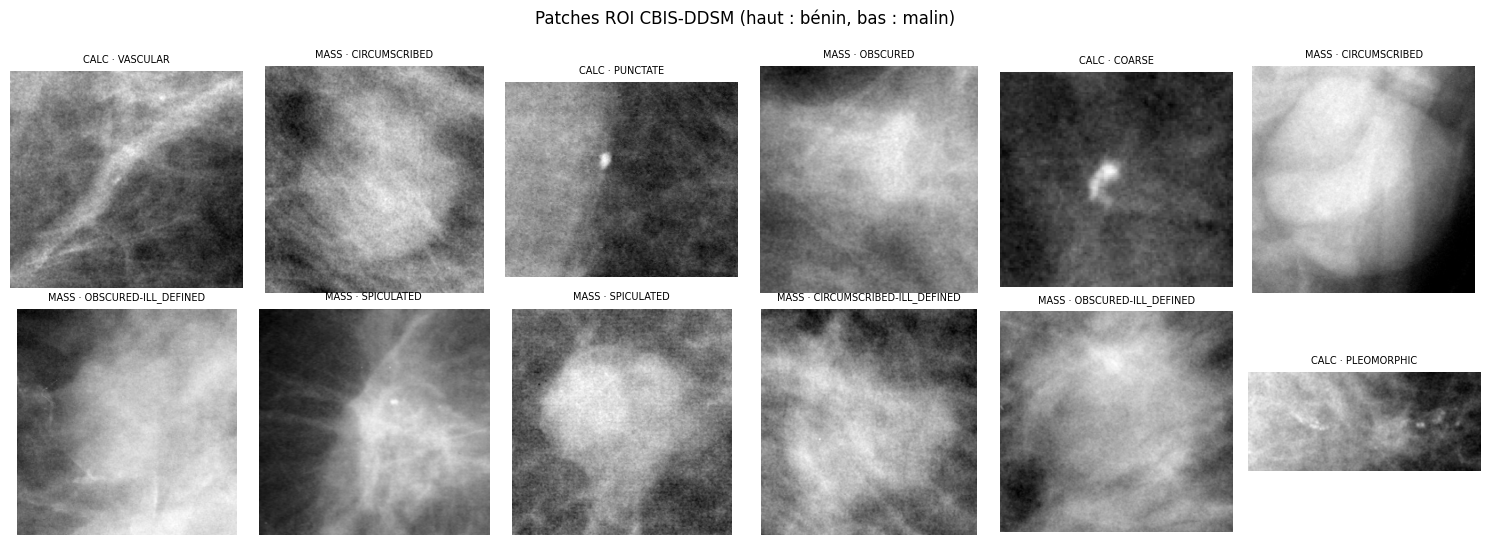

binarité moyenne des images retenues : 0.010 (un masque vaudrait ~1.0)
images suspectes (>0.9) : 0/200


In [12]:
import numpy as np, matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for row, lab in enumerate([0, 1]):
    sub = man[man.malignancy == lab].sample(6, random_state=0)
    for ax, (_, r) in zip(axes[row], sub.iterrows()):
        ax.imshow(np.asarray(Image.open(r.image_path)), cmap="gray")
        ax.axis("off")
        d = r.mass_margins if r.abnormality_type == "MASS" else r.calc_type
        ax.set_title(f"{str(r.abnormality_type)[:4]} · {d}", fontsize=7)
    axes[row, 0].set_ylabel("BÉNIN" if lab == 0 else "MALIN")
fig.suptitle("Patches ROI CBIS-DDSM (haut : bénin, bas : malin)", y=1.0)
plt.tight_layout(); plt.show()

# un patch de tissu n'est PAS binaire : cette fraction doit rester basse
def binariness(p, n=64):
    a = np.asarray(Image.open(p).convert("L").resize((n, n)))
    return float(((a <= 12) | (a >= 243)).mean())
b = man.image_path.sample(200, random_state=0).map(binariness)
print(f"binarité moyenne des images retenues : {b.mean():.3f} "
      f"(un masque vaudrait ~1.0)")
print(f"images suspectes (>0.9) : {(b > 0.9).sum()}/200")

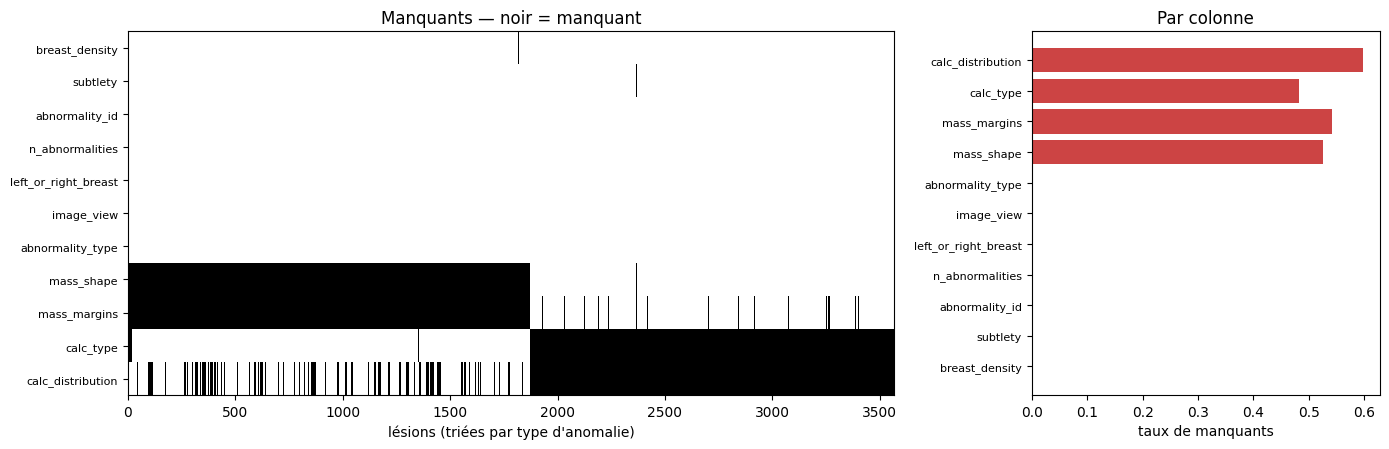

Les deux blocs complémentaires en haut à droite / bas à gauche sont la
manquance STRUCTURELLE : mass_* n'existe que pour les masses,
calc_* que pour les calcifications. Une imputation par la moyenne
détruirait cette information. C'est ce que l'encodeur missing-aware
exploite via un embedding [MISSING] appris PAR COLONNE.


In [13]:
cols = ["breast_density", "subtlety", "abnormality_id", "n_abnormalities",
        "left_or_right_breast", "image_view", "abnormality_type",
        "mass_shape", "mass_margins", "calc_type", "calc_distribution"]
M = man[cols].isna().to_numpy()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6),
                             gridspec_kw={"width_ratios": [2.2, 1]})
order = np.argsort(man.abnormality_type.values, kind="stable")
a1.imshow(M[order].T, aspect="auto", cmap="Greys", interpolation="nearest")
a1.set_yticks(range(len(cols))); a1.set_yticklabels(cols, fontsize=8)
a1.set_xlabel("lésions (triées par type d'anomalie)")
a1.set_title("Manquants — noir = manquant")

rate = M.mean(0)
a2.barh(range(len(cols)), rate, color=["#c44" if r > .4 else "#48a" for r in rate])
a2.set_yticks(range(len(cols))); a2.set_yticklabels(cols, fontsize=8)
a2.set_xlabel("taux de manquants"); a2.set_title("Par colonne")
plt.tight_layout(); plt.show()

print("Les deux blocs complémentaires en haut à droite / bas à gauche sont la")
print("manquance STRUCTURELLE : mass_* n'existe que pour les masses,")
print("calc_* que pour les calcifications. Une imputation par la moyenne")
print("détruirait cette information. C'est ce que l'encodeur missing-aware")
print("exploite via un embedding [MISSING] appris PAR COLONNE.")

---
## Étape 3 — Configuration et smoke test

Le smoke test valide sept points en quelques minutes : formes des tenseurs,
décroissance de la perte contrastive **sous la valeur du hasard** `log(B)`,
absence de NaN quand 100 % des features sont manquantes, effet mesurable du
masque sur la représentation, cohérence des métriques, et un cycle
pré-entraînement → fine-tuning complet.

À lancer systématiquement avant les expériences longues.

In [14]:
from src.utils import load_config, set_seed, get_device, count_params

FAST = False    # True = version courte pour déboguer (~20 min au total)

cfg = load_config("configs/cbis_kaggle.yaml", {
    "data.root":            str(CACHE),
    "data.image_size":      224,
    "data.num_workers":     2,
    "out_dir":              str(WORK / "outputs"),
    "pretrain.epochs":      8  if FAST else 60,
    "finetune.epochs":      5  if FAST else 25,
    "model.image.name":     "resnet18",
})
set_seed(cfg.seed)
print("device :", get_device(cfg.device))
print("epochs : pretrain", cfg.pretrain.epochs, "| finetune", cfg.finetune.epochs)

device : cuda
epochs : pretrain 60 | finetune 25


In [15]:
!python scripts/smoke_test.py

SMOKE TEST — Fusion multimodale imagerie + tabulaire
  [OK]  1. construction du dataset — train=210 val=45 test=45, 14 features, manquants=24.7%
  [OK]  2. sorties du DataLoader — image(8, 1, 64, 64) x_num(8, 4)
  [OK]  3. passe avant du modèle multimodal — z_image(8, 128), embeddings sémantiques (14, 128)
  [OK]  4. la perte contrastive décroît — InfoNCE 3.851 -> 3.609, encore au-dessus du hasard 3.47
  [OK]  5. robustesse aux valeurs manquantes — pas de NaN ; distance masqué/non-masqué = 2.079
  [OK]  6. métriques — AUROC et retrieval conformes
[downstream] 161 tenseurs d'encodeur chargés depuis /kaggle/working/fusion-multimodale/outputs/_smoke/pretrain/smoke/best.pt
  [OK]  7. pré-entraînement + fine-tuning de bout en bout — R@10 pré-entraînement=0.222, AUROC aval=0.482
TOUS LES TESTS SONT PASSÉS — le pipeline est opérationnel.
Étape suivante :  python -m src.train.run_experiments --config configs/default.yaml


---
## Étape 4 — Les données, telles que le modèle les voit

Trois précautions décident de la validité de tous les chiffres qui suivent :

1. **Anti-fuite.** `pathology` et `assessment` (le BI-RADS) sont retirés du
   vecteur tabulaire. `assessment` prédit presque parfaitement la malignité :
   le laisser rendrait la comparaison vide de sens.
2. **Split officiel CBIS-DDSM**, avec un garde-fou. CBIS sépare les masses et
   les calcifications **indépendamment** : un patient peut donc apparaître dans
   `mass_test` *et* dans `calc_train`. Ces patients sont retirés du train
   (jamais du test, qui reste la référence comparable).
3. **Regroupement des modalités rares.** `calc_type` contient des valeurs
   composées (`PLEOMORPHIC-FINE_LINEAR_BRANCHING`) et monte à ~45 modalités,
   dont beaucoup à une ou deux occurrences. Celles-ci sont regroupées en
   `OTHER` : sinon elles identifient le patient et la perte contrastive
   apprend un raccourci au lieu de la sémantique.

In [16]:
from src.data.datamodule import build_datasets

bundle = build_datasets(cfg, seed=cfg.seed)
s = bundle.schema
print(f"\ntrain={len(bundle.train_ds)} val={len(bundle.val_ds)} test={len(bundle.test_ds)}")
print(f"features tabulaires : {s.n_features} ({s.n_num} num + {s.n_cat} cat)")
print(f"cardinalités : {dict(zip(s.cat_cols, s.cat_cardinalities))}")
print(f"manquants (train) : {bundle.train_ds.mask.mean():.1%}")
print(f"poids de classe : {bundle.class_weights.round(3)}")

b = next(iter(bundle.loader("train", 4, num_workers=0, mode="pretrain")))
for k, v in b.items():
    print(f"  {k:8s} {tuple(v.shape)} {v.dtype}")

# --- Figer les embeddings sémantiques des colonnes ------------------------
# `semantic_field_emb: auto` les recalcule à CHAQUE construction de modèle
# (pré-entraînement, chaque fine-tuning, sonde) : c'est lent, et si le backend
# bascule en cours de route — sentence-transformers 384-d indisponible, repli
# hachage 128-d — le chargement des checkpoints casse en pleine expérience.
# On matérialise donc la matrice une fois sur disque.
import numpy as np
from src.data.semantic import build_semantic_matrix

if cfg.model.tabular.get("semantic_field_emb") in (True, "auto", "hashing"):
    sem_path = Path(cfg.out_dir) / "semantic_emb.npy"
    sem_path.parent.mkdir(parents=True, exist_ok=True)
    sem_mat = build_semantic_matrix(s, backend="auto", verbose=True)
    np.save(sem_path, sem_mat)
    cfg["model"]["tabular"]["semantic_field_emb"] = str(sem_path)
    print(f"[semantic] matrice figée {sem_mat.shape} -> {sem_path}")

[cbis] manifeste : /kaggle/working/cbis_cache/cbis_manifest.csv (3567 lignes, 1566 patients)
[cbis] mass_shape: 11 modalités rares regroupées en 'OTHER' (28 lignes) -> 10 modalités
[cbis] mass_margins: 10 modalités rares regroupées en 'OTHER' (30 lignes) -> 10 modalités
[cbis] calc_type: 33 modalités rares regroupées en 'OTHER' (194 lignes) -> 15 modalités
[cbis] calc_distribution: 3 modalités rares regroupées en 'OTHER' (13 lignes) -> 7 modalités
[cbis] malignité : 40.8% de positifs | split officiel {'train': np.int64(2863), 'test': np.int64(704)}
[cbis] tabulaire : 3 num + 7 cat (vue 'full') -> ['breast_density', 'subtlety', 'n_abnormalities', 'left_or_right_breast', 'image_view', 'abnormality_type', 'mass_shape', 'mass_margins', 'calc_type', 'calc_distribution']
[data] groupes détectés sur 'patient_id' (1566 groupes pour 3567 lignes)
[data] 31 patients présents à la fois dans le train et le test officiels (83 lignes de train). Cause : CBIS-DDSM sépare masses et calcifications indépe

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[semantic] sentence-transformers -> (10, 384)
[semantic] matrice figée (10, 384) -> /kaggle/working/outputs/semantic_emb.npy


---
## Étape 5 — Pré-entraînement contrastif image ↔ tabulaire

Aucune étiquette de malignité n'est utilisée. Le seul signal est
« ce patch appartient à cette lésion ».

```
logits   = (z_I @ z_T.T) / τ
L_{I→T}  = CE(logits,   diag)
L_{T→I}  = CE(logits.T, diag)
```

Deux indicateurs à surveiller :

* la **perte** doit descendre nettement sous `log(batch_size)` ;
* le **retrieval croisé** R@K sur la validation doit décoller au-dessus de `K/N`.

Si R@10 reste au niveau du hasard, inutile de continuer : l'alignement n'a pas
eu lieu. Les deux suspects habituels sont `tabular_corruption_rate` (trop bas →
solution triviale, trop haut → paires détruites) et un `batch_size` trop petit
(InfoNCE a besoin de négatifs).

In [17]:
from src.train.pretrain import pretrain

res_mm = pretrain(cfg, bundle=bundle, verbose=True, mode="multimodal", tag="multimodal")
res_mm

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

IDENTIFIABILITÉ DU VECTEUR TABULAIRE
  lignes                       : 2276
  vecteurs distincts           : 1149 (50.5%)
  lignes dans un groupe dupliqué: 70.4%
  plus grand groupe / médiane   : 12 / 1
  entropie de la ligne         : 9.79 bits (il en faut 7.00 pour désigner 1 élément parmi 128)
  PLAFOND de retrieval, batch 128 : R@1<=0.940  R@5<=1.000  R@10<=1.000
  PLAFOND sur l'ensemble d'éval (504) : R@1<=0.798  R@5<=1.000  R@10<=1.000

  VERDICT : le vecteur tabulaire n'identifie PAS le patient.
  La cible one-hot de l'InfoNCE demande de distinguer des lignes
  indistinguables ; la perte restera loin de zéro quoi que fasse
  le modèle.
  -> activez `pretrain.soft_targets: true` (cible pondérée par la
     similarité tabulaire au lieu de la diagonale stricte),
  -> et comparez le R@1 mesuré au PLAFOND ci-dessus, pas au hasard.

[pretrain] device=cuda | image_enc=11,170,240 params | tab_enc=380,544 params
[pretrain] 2276 paires d'entraînement, 17 pas/époque
  ep000 step0000 loss=5.

{'best_ckpt': '/kaggle/working/outputs/pretrain/multimodal/best.pt',
 'last_ckpt': '/kaggle/working/outputs/pretrain/multimodal/last.pt',
 'best_r10': 0.17857142857142858,
 'max_r10': np.float64(1.0),
 'mode': 'multimodal',
 'soft_targets': False,
 'identifiability': {'n_rows': 2276.0,
  'n_distinct': 1149.0,
  'frac_distinct': 0.5048330404217927,
  'frac_rows_in_duplicate_group': 0.7038664323374341,
  'largest_group': 12.0,
  'median_group': 1.0,
  'entropy_bits': 9.788297420275835,
  'bits_needed_batch': 7.0,
  'max_R@1': 0.9401953125,
  'max_R@5': 1.0,
  'max_R@10': 1.0,
  'max_R@1_eval': 0.7981547619047619,
  'max_R@5_eval': 0.9995932539682539,
  'max_R@10_eval': 1.0}}

[report] /kaggle/working/outputs/figures/pretrain_curves.png


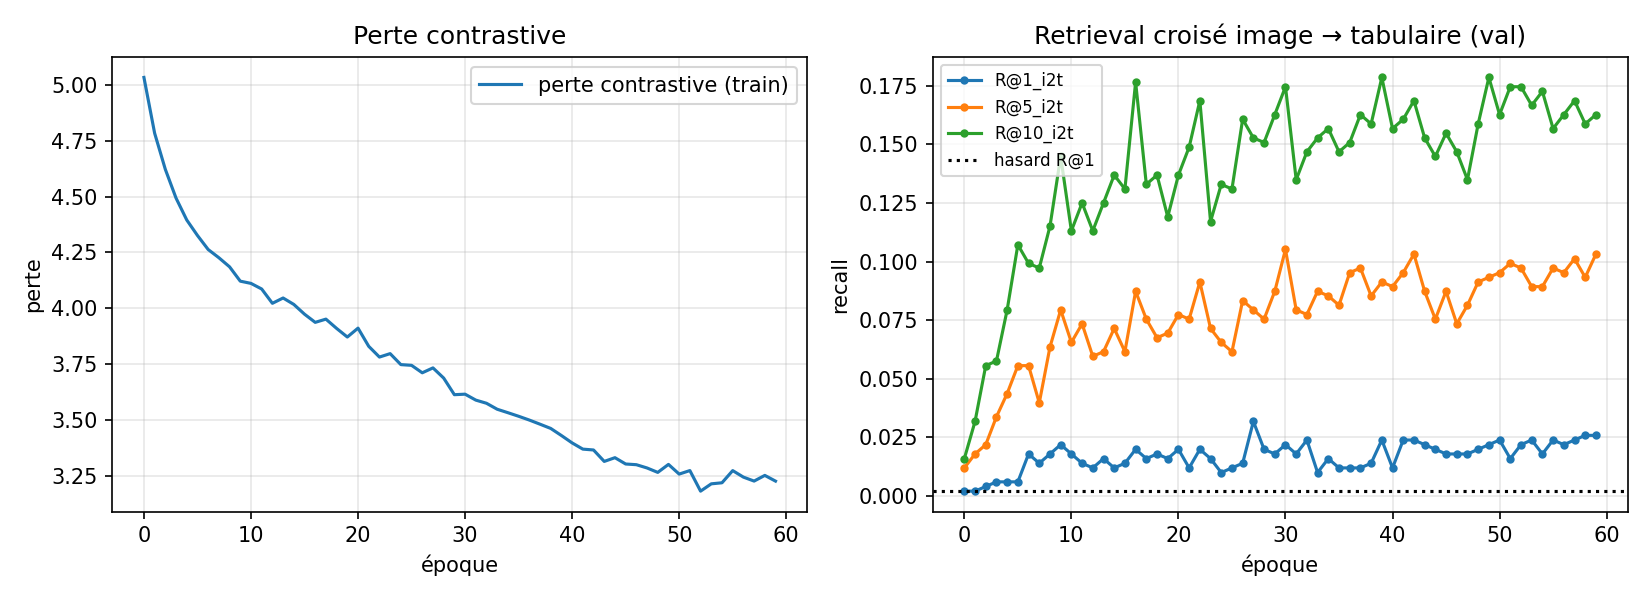

perte du hasard log(B) = 4.852
perte finale           = 3.227
R@1  final (val)       = 0.026  (hasard 0.0020)
R@10 final (val)       = 0.163


In [18]:
import json
from IPython.display import Image as IPImage, display
from src.eval.report import plot_pretrain_curves

log = Path(cfg.out_dir) / "pretrain" / "multimodal" / "log.jsonl"
png = Path(cfg.out_dir) / "figures" / "pretrain_curves.png"
plot_pretrain_curves(log, png); display(IPImage(str(png)))

hist = pd.DataFrame([json.loads(l) for l in log.read_text().splitlines() if l.strip()])
print(f"perte du hasard log(B) = {np.log(cfg.pretrain.batch_size):.3f}")
print(f"perte finale           = {hist['loss'].iloc[-1]:.3f}")
print(f"R@1  final (val)       = {hist['R@1_i2t'].iloc[-1]:.3f}  "
      f"(hasard {hist['chance_R@1'].iloc[-1]:.4f})")
print(f"R@10 final (val)       = {hist['R@10_i2t'].iloc[-1]:.3f}")

### L'espace latent est-il vraiment partagé ?

Si l'alignement a fonctionné, chaque patch et son dossier tombent au même
endroit. Les traits gris relient les vraies paires : plus ils sont courts,
mieux c'est.

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[report] /kaggle/working/outputs/figures/latent_space.png


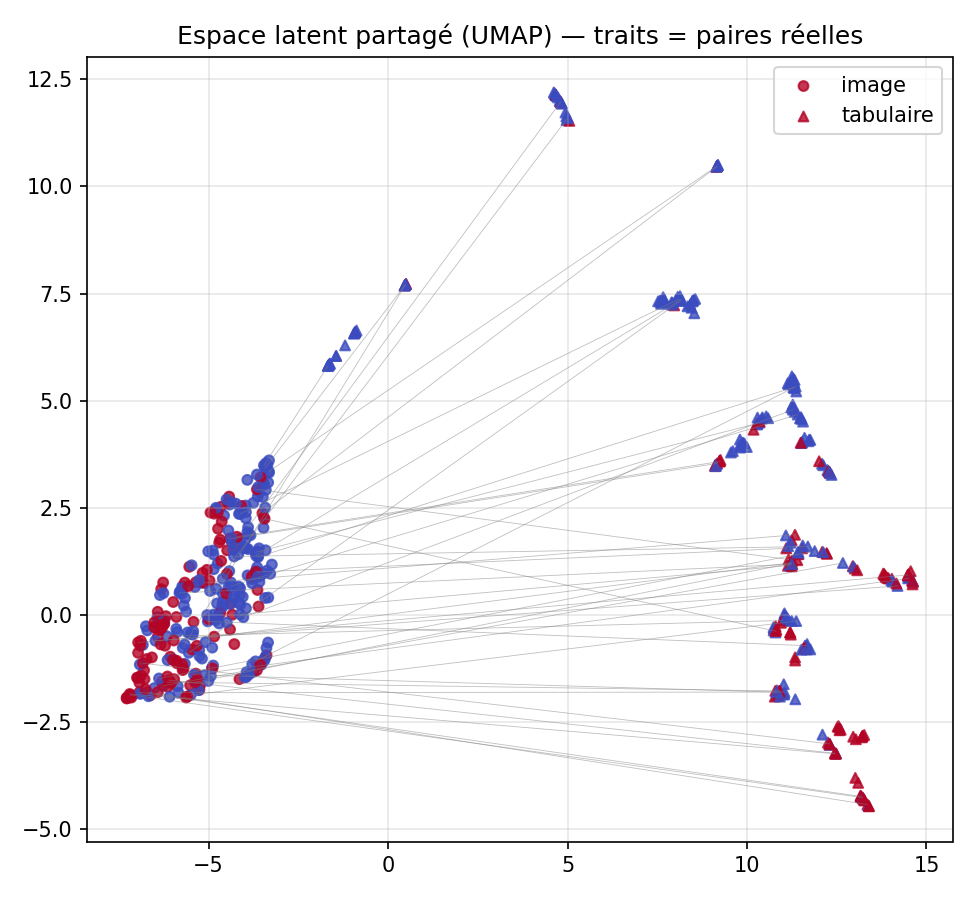

{'R@1_i2t': 0.0156, 'R@5_i2t': 0.0881, 'R@10_i2t': 0.1591, 'medr_i2t': 57.5, 'R@1_t2i': 0.0213, 'R@5_t2i': 0.0895, 'R@10_t2i': 0.1562, 'medr_t2i': 55.5, 'chance_R@1': 0.0014}


In [19]:
import torch, torch.nn.functional as F
from src.data.semantic import resolve_semantic_emb
from src.models.multimodal import build_pretrain_model
from src.eval.report import plot_embedding_umap
from src.eval.metrics import retrieval_metrics
from src.utils import load_checkpoint

device = get_device(cfg.device)
sem = resolve_semantic_emb(cfg, s, verbose=False)   # lit le .npy figé
model = build_pretrain_model(cfg, s, sem).to(device)
model.load_state_dict(load_checkpoint(res_mm["best_ckpt"], map_location=device)["model"])
model.eval()

Zi, Zt, Y = [], [], []
with torch.no_grad():
    for batch in bundle.loader("test", 128, shuffle=False, num_workers=2):
        o = model(batch["image"].to(device), batch["x_num"].to(device),
                  batch["x_cat"].to(device), batch["mask"].to(device))
        Zi.append(F.normalize(o["z_image"], dim=-1).cpu().numpy())
        Zt.append(F.normalize(o["z_tabular"], dim=-1).cpu().numpy())
        Y.append(batch["label"].numpy())
Zi, Zt, Y = np.concatenate(Zi), np.concatenate(Zt), np.concatenate(Y)

png = Path(cfg.out_dir) / "figures" / "latent_space.png"
plot_embedding_umap(Zi, Zt, Y, png, n=300); display(IPImage(str(png)))
print({k: round(v, 4) for k, v in retrieval_metrics(Zi, Zt, (1, 5, 10)).items()})

### Si l'alignement stagne : que l'image peut-elle réellement prédire ?

Deux causes possibles. Le rapport d'identifiabilité affiché avant le
pré-entraînement en mesure une, la sonde ci-dessous mesure l'autre — et sur ce
dataset **les deux sont réelles**.

1. **Lignes tabulaires dupliquées.** Mesuré sur CBIS en vue `full` : seulement
   **50,5 %** des 2276 vecteurs sont distincts, **70 %** des lignes partagent leur
   vecteur avec au moins une autre, et le plus grand groupe compte 12 lésions
   identiques. Le plafond de R@1 tombe à **0,80** sur l'ensemble de validation.
   La cible one-hot demande donc en partie de distinguer l'indistinguable.
   En vue `clinical_only` c'est extrême : 32 vecteurs distincts pour 2276 lignes.

2. **Colonnes non observables dans l'image.** Avec `cbis_kind: roi`, l'entrée est
   un patch recadré sur la lésion : ce qui décrit le sein entier ou l'examen ne
   peut pas s'y lire.

La sonde gèle l'encodeur image et ajuste une régression logistique par colonne.
Gain nul contre le classifieur majoritaire = colonne invisible. À lire en
sachant que le résultat peut surprendre : la densité mammaire, que l'on croirait
perdue au recadrage, reste partiellement lisible dans la texture du patch.


In [20]:
from src.eval.probe import probe_tabular_from_image

# bundle=bundle : on réutilise le dataset déjà construit au lieu de tout
# recharger. La sonde force shuffle=False ET drop_last=False, sinon les 100
# dernières lignes du train disparaîtraient (2276 -> 2176 avec un batch de 128)
# et les masques seraient décalés.
probe_rows = probe_tabular_from_image(cfg, ckpt=res_mm["best_ckpt"],
                                     bundle=bundle, verbose=True)
pd.DataFrame(probe_rows).round(4)

[probe] encodeur image chargé depuis /kaggle/working/outputs/pretrain/multimodal/best.pt
[probe] extraction des embeddings image…

colonne                  type            cl.   sonde  major.    gain  visible ?
------------------------------------------------------------------------------
abnormality_type         cat               3   0.927   0.500  +0.427  OUI
breast_density           num(terciles)     3   0.495   0.333  +0.162  OUI
mass_shape               cat              11   0.238   0.100  +0.138  OUI
calc_type                cat              16   0.220   0.091  +0.129  OUI
subtlety                 num(terciles)     3   0.461   0.333  +0.128  OUI
mass_margins             cat              11   0.211   0.100  +0.111  OUI
calc_distribution        cat               8   0.251   0.143  +0.109  OUI
image_view               cat               3   0.539   0.500  +0.039  ~
left_or_right_breast     cat               3   0.494   0.500  -0.006  NON

Lecture : une colonne à gain nul n'est pas ob

,column,kind,n_classes,n_observed_test,probe_bacc,majority_bacc,gain
0,abnormality_type,cat,3,704,0.9273,0.5000,0.4273
1,breast_density,num(terciles),3,702,0.4954,0.3333,0.1621
2,mass_shape,cat,11,378,0.2380,0.1000,0.1380
3,calc_type,cat,16,322,0.2196,0.0909,0.1287
4,subtlety,num(terciles),3,704,0.4609,0.3333,0.1276
5,mass_margins,cat,11,361,0.2114,0.1000,0.1114
6,calc_distribution,cat,8,263,0.2514,0.1429,0.1086
7,image_view,cat,3,704,0.5390,0.5000,0.0390
8,left_or_right_breast,cat,3,704,0.4941,0.5000,-0.0059


---
## Étape 6 — Fine-tuning et comparaison aux baselines

Le protocole décisif est `modalities="image"` : **au test, seule l'image est
disponible**. En clinique, l'image est toujours là ; le compte rendu structuré,
souvent non. On mesure donc ce que le pré-entraînement multimodal a *injecté*
dans l'encodeur image.

Sept méthodes, un seul `bundle` : même split, même prétraitement, même budget.

| Code | Méthode | Ce qu'elle isole |
|---|---|---|
| A | Image seule, init aléatoire | plancher |
| B | Image seule, init ImageNet | pré-entraînement générique |
| C | Image seule, SimCLR unimodal | SSL **sans** le tabulaire |
| D | Tabulaire seul | plafond de l'information du compte rendu |
| E | Concaténation naïve (MLP), supervisé | fusion **sans** le SSL |
| **F** | **SSL multimodal → test image seule** | **la méthode** |
| G | SSL multimodal → test image + tabulaire | idem, dossier disponible |

Les deux comparaisons qui concluent : **F − C** (apport du tabulaire dans le
SSL) et **F − E** (apport du SSL sur la fusion supervisée naïve).

> Sur CBIS-DDSM, attendez-vous à un **D élevé** (~0.75-0.85) : `mass_margins`
> et `calc_type` sont des descripteurs de radiologue portant sur la lésion
> montrée. C'est légitime — ce sont des métadonnées de compte rendu — mais
> l'expérience plus conservatrice est `data.clinical_only=true`, qui ne garde
> que densité, latéralité, incidence et nombre d'anomalies. Faites tourner les
> deux ; c'est plus honnête et plus convaincant.

In [21]:
from src.train.run_experiments import run_all

results = run_all(cfg, fractions=[0.01, 0.1, 1.0], ablations=True, verbose=True)
results

[cbis] manifeste : /kaggle/working/cbis_cache/cbis_manifest.csv (3567 lignes, 1566 patients)
[cbis] mass_shape: 11 modalités rares regroupées en 'OTHER' (28 lignes) -> 10 modalités
[cbis] mass_margins: 10 modalités rares regroupées en 'OTHER' (30 lignes) -> 10 modalités
[cbis] calc_type: 33 modalités rares regroupées en 'OTHER' (194 lignes) -> 15 modalités
[cbis] calc_distribution: 3 modalités rares regroupées en 'OTHER' (13 lignes) -> 7 modalités
[cbis] malignité : 40.8% de positifs | split officiel {'train': np.int64(2863), 'test': np.int64(704)}
[cbis] tabulaire : 3 num + 7 cat (vue 'full') -> ['breast_density', 'subtlety', 'n_abnormalities', 'left_or_right_breast', 'image_view', 'abnormality_type', 'mass_shape', 'mass_margins', 'calc_type', 'calc_distribution']
[data] groupes détectés sur 'patient_id' (1566 groupes pour 3567 lignes)
[data] 31 patients présents à la fois dans le train et le test officiels (83 lignes de train). Cause : CBIS-DDSM sépare masses et calcifications indépe

,method,label_fraction,modalities,test_auroc,test_auroc_lo,test_auroc_hi,test_auprc,test_balanced_accuracy,test_macro_f1,test_ece,val_auroc
6,G_ours_both,0.01,both,0.651759,0.612335,0.689108,0.563619,0.556075,0.511540,0.202063,0.752753
5,F_ours_img,0.01,image,0.629470,0.588865,0.669641,0.528077,0.596167,0.536008,0.082935,0.683847
2,C_img_simclr,0.01,image,0.616204,0.573789,0.655102,0.486016,0.577932,0.525269,0.053379,0.683619
0,A_img_scratch,0.01,image,0.588099,0.547387,0.627138,0.475207,0.559563,0.534087,0.004215,0.632404
4,E_concat_naive,0.01,both,0.585991,0.541140,0.627904,0.448431,0.560020,0.468111,0.107782,0.663175
1,B_img_imagenet,0.01,image,0.583960,0.547491,0.624394,0.441090,0.506738,0.442634,0.031300,0.572425
3,D_tab_only,0.01,tabular,0.497664,0.451840,0.542936,0.382838,0.498188,0.492508,0.173041,0.557071
13,G_ours_both,0.10,both,0.787688,0.758518,0.818759,0.675665,0.719406,0.698942,0.077536,0.837069
12,F_ours_img,0.10,image,0.741323,0.705467,0.776913,0.650222,0.659996,0.633378,0.062724,0.786782
11,E_concat_naive,0.10,both,0.734568,0.698746,0.768844,0.610172,0.667869,0.652388,0.058909,0.789926


label_fraction,0.010000,0.100000,1.000000
method,,,
A_img_scratch,0.5881,0.5866,0.6351
B_img_imagenet,0.5840,0.6243,0.7292
C_img_simclr,0.6162,0.6694,0.7485
D_tab_only,0.4977,0.6918,0.7927
E_concat_naive,0.5860,0.7346,0.8265
F_ours_img,0.6295,0.7413,0.7822
G_ours_both,0.6518,0.7877,0.8309
abl_missing_base,nan,nan,0.8309
abl_naive_tab_enc,nan,nan,0.7909


[report] /kaggle/working/outputs/figures/label_efficiency.png


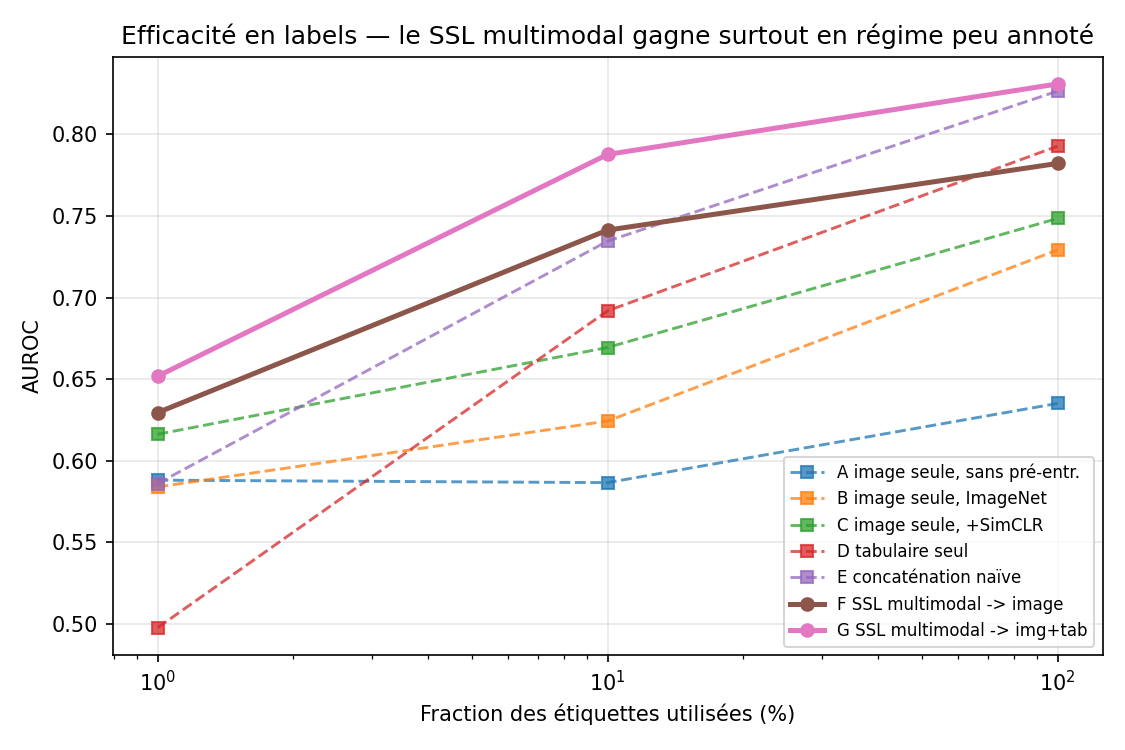

In [22]:
piv = results.pivot_table(index="method", columns="label_fraction", values="test_auroc")
display(piv.style.background_gradient(cmap="Greens", axis=0).format("{:.4f}"))

from src.eval.report import plot_label_efficiency, markdown_table
png = Path(cfg.out_dir) / "figures" / "label_efficiency.png"
plot_label_efficiency(Path(cfg.out_dir) / "results.csv", png)
display(IPImage(str(png)))

### Lire les résultats sans se raconter d'histoires

La règle : si les intervalles de confiance bootstrap se chevauchent largement,
**on ne conclut pas**. Sur ~400 lésions de test, un écart d'AUROC de 0.02 est
dans le bruit.

In [23]:
for frac, g in results.groupby("label_fraction"):
    g = g.set_index("method")
    if "F_ours_img" not in g.index:
        continue
    f = g.loc["F_ours_img"]
    print(f"\n--- {frac:.0%} des étiquettes ---")
    print(f"  F_ours_img : {f.test_auroc:.4f}  "
          f"IC95 [{f.test_auroc_lo:.3f}, {f.test_auroc_hi:.3f}]")
    for base in ("C_img_simclr", "E_concat_naive", "A_img_scratch", "B_img_imagenet"):
        if base not in g.index:
            continue
        bb = g.loc[base]
        delta = f.test_auroc - bb.test_auroc
        overlap = not (f.test_auroc_lo > bb.test_auroc_hi
                       or bb.test_auroc_lo > f.test_auroc_hi)
        verdict = "IC chevauchants -> non concluant" if overlap else "écart significatif"
        print(f"  vs {base:16s} {delta:+.4f}   ({verdict})")


--- 1% des étiquettes ---
  F_ours_img : 0.6295  IC95 [0.589, 0.670]
  vs C_img_simclr     +0.0133   (IC chevauchants -> non concluant)
  vs E_concat_naive   +0.0435   (IC chevauchants -> non concluant)
  vs A_img_scratch    +0.0414   (IC chevauchants -> non concluant)
  vs B_img_imagenet   +0.0455   (IC chevauchants -> non concluant)

--- 10% des étiquettes ---
  F_ours_img : 0.7413  IC95 [0.705, 0.777]
  vs C_img_simclr     +0.0719   (IC chevauchants -> non concluant)
  vs E_concat_naive   +0.0068   (IC chevauchants -> non concluant)
  vs A_img_scratch    +0.1547   (écart significatif)
  vs B_img_imagenet   +0.1170   (écart significatif)

--- 100% des étiquettes ---
  F_ours_img : 0.7822  IC95 [0.748, 0.816]
  vs C_img_simclr     +0.0337   (IC chevauchants -> non concluant)
  vs E_concat_naive   -0.0443   (IC chevauchants -> non concluant)
  vs A_img_scratch    +0.1471   (écart significatif)
  vs B_img_imagenet   +0.0530   (IC chevauchants -> non concluant)


### Robustesse : que se passe-t-il quand le compte rendu est vide ?

Situation réelle : à l'inférence, les métadonnées structurées sont souvent
incomplètes. On prend le **même** modèle fine-tuné en image+tabulaire et on
masque progressivement les métadonnées au test.

In [24]:
rob_csv = Path(cfg.out_dir) / "robustness_missing.csv"
if rob_csv.exists():
    rob = pd.read_csv(rob_csv)
    display(rob.round(4))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(rob.extra_missing_rate * 100, rob.test_auroc, marker="o", lw=2.2,
            label="SSL multimodal (image+tab)")
    ref = results.query("method=='F_ours_img' and label_fraction==1.0")
    if len(ref):
        ax.axhline(ref.test_auroc.iloc[0], ls="--", c="gray",
                   label="SSL multimodal, image seule au test")
    ax.set_xlabel("métadonnées masquées au test (%)"); ax.set_ylabel("AUROC test")
    ax.set_title("Dégradation quand le compte rendu se vide")
    ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("relancez run_all avec ablations=True")

,extra_missing_rate,effective_missing_rate,test_accuracy,test_balanced_accuracy,test_macro_f1,test_ece,test_auroc,test_auprc
0,0.00,0.2122,0.7330,0.7341,0.7265,0.0841,0.8309,0.7652
1,0.25,0.4152,0.7145,0.6886,0.6923,0.1200,0.7873,0.7191
2,0.50,0.6099,0.6903,0.6353,0.6341,0.1715,0.7647,0.6965
3,0.75,0.8043,0.6534,0.5741,0.5430,0.2525,0.7149,0.6263
4,1.00,1.0000,0.6193,0.5145,0.4090,0.3344,0.7229,0.6740


---
## Étape 7 — Les trois vues du vecteur tabulaire

`data.tabular_view` sélectionne les colonnes, et chaque vue répond à une question
différente :

| vue | colonnes | question |
|---|---|---|
| `full` | tout | borne supérieure de l'apport des métadonnées |
| `clinical_only` | densité, latéralité, incidence, nb de lésions | et si on n'utilisait que ce qui précède toute lecture experte ? |
| `roi_visible` | type, forme, marges, morphologie et distribution des calcifications, subtilité | et si on ne gardait que ce que le patch peut montrer ? |

`clinical_only` est la version à défendre scientifiquement : les descripteurs
morphologiques sont des annotations de radiologue **portant sur la lésion
montrée**, ce qui explique un `D_tab_only` élevé en vue `full` (0,79).

Attention en lisant les résultats : réduire le vecteur réduit aussi son
identifiabilité, donc le plafond de l'InfoNCE. Mesuré ici — 50,5 % de vecteurs
distincts en `full`, 12 % en `roi_visible`, 1,4 % en `clinical_only` — et
l'alignement suit : R@10 de 0,18 puis 0,15 puis 0,08. Les deux effets jouent en
sens opposé, ce qui rend la comparaison entre vues intéressante mais pas
directement causale.


In [ ]:
from src.utils import load_config as _lc

runs = {}
for view in ["roi_visible", "clinical_only"]:
    cfg_v = _lc("configs/cbis_kaggle.yaml", {
        "data.root":         str(CACHE),
        "data.tabular_view": view,
        "out_dir":           str(WORK / f"outputs_{view}"),
        "pretrain.epochs":   cfg.pretrain.epochs,
        "finetune.epochs":   cfg.finetune.epochs,
        "data.num_workers":  2,
    })
    print("\n" + "#" * 78)
    print(f"# vue tabulaire : {view}")
    print("#" * 78)
    runs[view] = run_all(cfg_v, fractions=[1.0], ablations=False, verbose=True)

comp = pd.concat([results.assign(view="full")]
                 + [d.assign(view=v) for v, d in runs.items()])
comp = comp.query("label_fraction == 1.0").pivot_table(
    index="method", columns="view", values="test_auroc")
comp.round(4)


##############################################################################
# vue tabulaire : roi_visible
##############################################################################
[cbis] manifeste : /kaggle/working/cbis_cache/cbis_manifest.csv (3567 lignes, 1566 patients)
[cbis] mass_shape: 11 modalités rares regroupées en 'OTHER' (28 lignes) -> 10 modalités
[cbis] mass_margins: 10 modalités rares regroupées en 'OTHER' (30 lignes) -> 10 modalités
[cbis] calc_type: 33 modalités rares regroupées en 'OTHER' (194 lignes) -> 15 modalités
[cbis] calc_distribution: 3 modalités rares regroupées en 'OTHER' (13 lignes) -> 7 modalités
[cbis] malignité : 40.8% de positifs | split officiel {'train': np.int64(2863), 'test': np.int64(704)}
[cbis] tabulaire : 1 num + 5 cat (vue 'roi_visible') -> ['subtlety', 'abnormality_type', 'mass_shape', 'mass_margins', 'calc_type', 'calc_distribution']
[data] groupes détectés sur 'patient_id' (1566 groupes pour 3567 lignes)
[data] 31 patients présents à 

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[semantic] sentence-transformers -> (6, 384)
[semantic] matrice figée (6, 384) -> /kaggle/working/outputs_roi_visible/semantic_emb.npy
[data] train=2276 val=504 test=704 | 6 features tabulaires (1 num + 5 cat) | 2 classes
[data] taux global de valeurs manquantes : 35.7%

=== SSL 1/2 : contrastif MULTIMODAL (image <-> tabulaire) ===
IDENTIFIABILITÉ DU VECTEUR TABULAIRE
  lignes                       : 2276
  vecteurs distincts           : 274 (12.0%)
  lignes dans un groupe dupliqué: 97.8%
  plus grand groupe / médiane   : 105 / 4
  entropie de la ligne         : 7.11 bits (il en faut 7.00 pour désigner 1 élément parmi 128)
  PLAFOND de retrieval, batch 128 : R@1<=0.617  R@5<=0.975  R@10<=1.000
  PLAFOND sur l'ensemble d'éval (504) : R@1<=0.334  R@5<=0.781  R@10<=0.911

  VERDICT : le vecteur tabulaire n'identifie PAS le patient.
  La cible one-hot de l'InfoNCE demande de distinguer des lignes
  indistinguables ; la perte restera loin de zéro quoi que fasse
  le modèle.
  -> activez `pr

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[semantic] sentence-transformers -> (5, 384)
[semantic] matrice figée (5, 384) -> /kaggle/working/outputs_clinical_only/semantic_emb.npy
[data] train=2276 val=504 test=704 | 5 features tabulaires (2 num + 3 cat) | 2 classes
[data] taux global de valeurs manquantes : 0.0%

=== SSL 1/2 : contrastif MULTIMODAL (image <-> tabulaire) ===
IDENTIFIABILITÉ DU VECTEUR TABULAIRE
  lignes                       : 2276
  vecteurs distincts           : 32 (1.4%)
  lignes dans un groupe dupliqué: 100.0%
  plus grand groupe / médiane   : 143 / 69
  entropie de la ligne         : 4.83 bits (il en faut 7.00 pour désigner 1 élément parmi 128)
  PLAFOND de retrieval, batch 128 : R@1<=0.233  R@5<=0.829  R@10<=0.991
  PLAFOND sur l'ensemble d'éval (504) : R@1<=0.063  R@5<=0.308  R@10<=0.564

  VERDICT : le vecteur tabulaire n'identifie PAS le patient.
  La cible one-hot de l'InfoNCE demande de distinguer des lignes
  indistinguables ; la perte restera loin de zéro quoi que fasse
  le modèle.
  -> activez `p

---
## Sauvegarder les résultats

`/kaggle/working` est vidé entre les sessions : téléchargez ce qui compte, ou
faites **Save Version** pour que les fichiers de sortie soient conservés.

In [ ]:
import shutil
out = WORK / "resultats_cbis"
out.mkdir(exist_ok=True)
for src in [Path(cfg.out_dir) / "results.csv",
            Path(cfg.out_dir) / "robustness_missing.csv",
            Path(cfg.out_dir) / "pretrain_summary.json",
            WORK / "outputs_roi_visible" / "results.csv",
            WORK / "outputs_clinical_only" / "results.csv",
            Path(cfg.out_dir) / "probe_tabular_from_image.csv"]:
    if src.exists():
        shutil.copy(src, out / f"{src.parent.name}_{src.name}")
figs = out / "figures"; figs.mkdir(exist_ok=True)
for p in (Path(cfg.out_dir) / "figures").glob("*.png"):
    shutil.copy(p, figs / p.name)
# les checkpoints SSL, utiles pour repartir de là
for tag in ("multimodal", "simclr"):
    ck = Path(cfg.out_dir) / "pretrain" / tag / "best.pt"
    if ck.exists():
        shutil.copy(ck, out / f"ssl_{tag}.pt")
print("\n".join(str(p.relative_to(WORK)) for p in sorted(out.rglob("*")) if p.is_file()))

---
## Bilan et pistes

| Affirmation | Preuve |
|---|---|
| L'alignement patch ↔ compte rendu s'apprend | R@10 très au-dessus du hasard, espace latent superposé |
| Le SSL multimodal bat le SSL unimodal | écart F − C, avec IC bootstrap |
| Il bat la fusion supervisée naïve | écart F − E |
| Le gain est maximal en régime peu annoté | courbe d'efficacité en labels |
| L'encodeur gère la manquance structurelle | courbe de robustesse |

**Pistes, par ordre d'intérêt :**

1. Plusieurs graines (`--set seed=1,2,3`) et report en moyenne ± écart-type.
2. `--kind full --size 512` : mammographie complète, scénario clinique réaliste.
   Le SSL multimodal devrait y aider davantage, la lésion étant noyée.
3. `data.target=birads` : tâche multi-classes, plus difficile et plus proche de
   l'usage radiologique.
4. Reconstruction tabulaire depuis l'image en tâche auxiliaire : force
   l'encodeur image à retenir explicitement l'information du compte rendu.
5. Attention croisée pixels ↔ colonnes plutôt que fusion tardive : permet de
   montrer *quelle colonne* regarde *quelle région*. Fort argument
   d'interprétabilité clinique.
6. Transfert CBIS-DDSM → VinDr-Mammo. C'est là que les embeddings sémantiques
   de colonnes deviennent indispensables, les schémas tabulaires différant — et
   c'est probablement la contribution la plus originale accessible.

Voir `README.md` §CBIS-DDSM et §9.
